# 학술제 최종 코드 — DART 패널 2015~2025

> **산술식 규칙은 `formula.py` 한 파일에서 불러옵니다** (근거·출처: `결정표.md`). 4장 가설검정·5장 산술식·6장 모델링이 같은 정의를 씁니다. Colab에서는 `formula.py`를 이 노트북과 같은 드라이브 폴더에 올리거나 0장의 `FORMULA_CANDIDATES`에 폴더를 적어 주세요.
**성과급·임금 진단 에이전트** · 너신발끈풀렸다인사잘한다 (Dart-B HR 학술제)

같은 업종 비교("하이닉스가 10%니까 우리도")만으로는 우리 회사가 성과급·임금을 올릴 수 있는지 알 수 없습니다. 이 노트북은 DART 공시 패널로 **① 우리 회사 임금이 비슷한 회사들 사이에서 어디쯤인지, ② 올릴 여력이 있는지, ③ 올리면 비용과 위험이 얼마인지**를 계산합니다.

| 장 | 내용 | 결과물 |
|---|---|---|
| 0 | 환경 설정 (Colab 드라이브 연결, 한글 폰트, 경로) | — |
| 1 | EDA: 구조·결측·분포·이상치·업종·연도 변화 | 1-x 표·그림 |
| 2 | 전처리: 감가상각비 이상값 비우기 (산술식 최종본 규칙, **행은 지우지 않음**) | 감가 2,995개 값 비움 |
| 3 | EDA 요약 | — |
| 4 | 가설검정 H1~H8 (H7·H8은 WPS) → 산술식의 각 결정에 대한 근거 (업종 기준: 중분류 우선, 2026-11-20 수정판) | 4-6 요약표 |
| 5 | 산술식 적용 (최종본 v3 업종 규칙 수정판, 2-6 α는 발표 슬라이드 정의) | 임금 위치 × 지급 여력, 비용, 진단문장 |
| 6 | 통합 모델링: 1년 예측(검증) + 3년 시나리오 | 회사별 통합 결과표, 예측 결과(6-9) |

**표본은 하나로 통일했습니다.** 4장 가설검정, 5장 산술식, 6장 모델링은 모두 **산술식 분석 자격(v3)**을 씁니다: 직원 10명 이상, 지주회사·급여이상·직원10명미만·공시접수검토 플래그 제외, 단위 오류(직원수·급여·자산 30배, 매출 100배 이탈, |영업이익| > 3×자산) 제외, 비금융. 상장시장은 제한하지 않아 비상장 외감(기타)·코넥스 기업도 들어갑니다.
- 전체 기간 **21,761행 · 2,840곳**, 3년 판정 구간(2023~2025) **2,205곳**

**확정된 결정**
- 인건비 = **급여총액 S** (H1: W 공시 기업과 아닌 기업이 실질적으로 같고, S와 W의 순서가 대체로 일치)
- **K = 3년 합산** (H4: 판정이 덜 흔들림)
- 비교군 = **같은 중분류 먼저, 20곳이 안 되면 같은 대분류에서 채운** 매출·1인당 자산이 가까운 20곳 (H3, 2026-11-20 수정: 제조 4군 폐기)
- 2-6 이익연동 전환의 시작값 α* = 5% × ΣS ÷ ΣOP (3년 합산, 과거에 적용해 보는 계산은 하지 않음, 11-21 결정)
- **성과급·임금을 올리면 이익이 오른다는 효과는 계산에 넣지 않음** (H6)
- **임금의 근거는 생산성이 아니라 인력 유지, 성과급의 근거는 생산성이 아니라 성과 공유** (H7: 임금 위치가 낮을수록 자발적 이직이 많음 / H8: 성과급은 성과를 뒤따름, 생산성 상승 근거 없음)

**실행 방법**: Colab에서 위에서부터 순서대로 실행합니다(전체 약 3~5분). 패널 CSV(`DART_패널_2015_2025.csv`)는 0장의 경로에서 자동으로 찾습니다. 6장의 `TENURE_PATH`(근속), `F6_PATH`(산술식 결과 파일)는 선택 사항이고, 없으면 해당 열만 비워 둡니다.


## 0️⃣ 환경 설정

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
from scipy import stats

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore', category=FutureWarning)

#### Colab 설정
Colab이면 드라이브를 연결하고 한글 폰트(나눔고딕)를 설치합니다.

In [2]:
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    drive.mount('/content/drive')
    font_path = Path('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
    if not font_path.exists():
        subprocess.run(['apt-get', '-qq', 'update'], check=True)
        subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-nanum'], check=True)
    font_manager.fontManager.addfont(str(font_path))
print('Colab 환경:', IN_COLAB)

Colab 환경: False


#### 경로 설정
파일 이름이 `DART_통합_2015_2025.csv` / `DART_패널_2015_2025.csv` 두 가지로 돌아다녀서 둘 다 찾습니다.
세션 로컬(`/content`)은 런타임이 끊기면 사라지므로 드라이브 사본을 먼저 찾습니다.

In [3]:
CANDIDATE_NAMES = ['DART_통합_2015_2025.csv', 'DART_패널_2015_2025.csv', 'DART_패널_2015_2025 (1).csv']
# 제공해주신 구글 드라이브 상세 경로를 탐색 대상에 추가합니다.
SEARCH_ROOTS = ([
    Path('/content/drive/MyDrive/외부 활동/Dart-B/26-2/학술제 HR (1)/5_데이터/최종 통합 DART 데이터셋'),
    Path('/content/drive/MyDrive'),
    Path('/content')
] if IN_COLAB else [Path.cwd(), Path(os.environ.get('DART_DIR', '.'))])

def find_data_file():
    for root in SEARCH_ROOTS:
        if not root.exists():
            continue
        for name in CANDIDATE_NAMES:
            direct = root / name
            if direct.is_file():
                return direct
        for name in CANDIDATE_NAMES:
            try:
                found = sorted(root.glob(f'**/{name}'))
                if found:
                    return found[0]
            except Exception:
                continue
    raise FileNotFoundError(
        '패널 CSV를 찾지 못했습니다. 구글 드라이브(My Drive) 최상위 폴더에 파일을 업로드했는지 확인해 주세요.\n'
        '허용 파일명: ' + ', '.join(CANDIDATE_NAMES))

try:
    DATA_PATH = find_data_file()
    print('데이터 파일 발견:', DATA_PATH)
except FileNotFoundError as e:
    print('⚠️ 오류 발생:', e)
    print('💡 해결 방법: 왼쪽 파일 사이드바(📁)를 열어 /content/ 밑에 패널 데이터를 업로드하거나, 구글 드라이브의 My Drive에 CSV 파일을 직접 올려주세요.')
    raise e

OUTPUT_DIR = (Path('/content/drive/MyDrive/외부 활동/Dart-B/26-2/학술제 HR/결과') if IN_COLAB
              else Path('outputs/final_eda'))
FIGURE_DIR = OUTPUT_DIR / 'figures'
for folder in [OUTPUT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print('출력 디렉토리:', OUTPUT_DIR)

데이터 파일 발견: C:\Users\kevin\Downloads\DART_패널\DART_패널_2015_2025.csv
출력 디렉토리: outputs\final_eda


#### 산술식 모듈(formula.py) 불러오기
산술식의 규칙과 상수(비교군 20곳, 임금 위치 경계, 업종 기준, 지급률·부대비용 등)는 모두 `formula.py`에 한 번만 정의돼 있습니다. 이 노트북은 그 파일을 불러다 쓰기만 합니다.

In [4]:
# formula.py 불러오기: 산술식의 모든 규칙과 상수가 들어 있는 파일 (결정표.md)
import sys
FORMULA_CANDIDATES = [Path(os.environ['FORMULA_DIR'])] if os.environ.get('FORMULA_DIR') else []
FORMULA_CANDIDATES += ([Path('/content/drive/MyDrive/외부 활동/Dart-B/26-2/학술제 HR (1)/formula'), DATA_PATH.parent, Path('/content')]
                       if IN_COLAB else [Path.cwd(), Path.cwd() / 'formula'])
for _p in FORMULA_CANDIDATES:
    if (_p / 'formula.py').exists():
        sys.path.insert(0, str(_p))
        break
else:
    raise FileNotFoundError('formula.py를 찾지 못했습니다. FORMULA_DIR 환경변수나 FORMULA_CANDIDATES에 폴더를 넣어 주세요.')
import formula as F
print('산술식 모듈:', F.__file__)


산술식 모듈: C:\Users\kevin\Downloads\산술식_재검토\formula\formula.py


#### 분석 설정값

In [5]:
SEED = 42
YEAR_MIN, YEAR_MAX = 2015, 2025
EOK = 1e8                          # 금액 표시 단위: 억 원
K = F.YEARS_IN_WINDOW              # 3년 합산 (formula.py)
RECENT_YEARS = [2023, 2024, 2025]  # K=3 판정 구간
KEY_COLS = ['기업고유코드', '사업연도']

JUMP_RATIO = 30        # 같은 기업 다른 연도 중앙값 대비 이탈 배수 (단위 오류 의심)
JUMP_MIN_OBS = 3       # 급변 판정에 필요한 최소 관측 연수
WS_RANGE = (0.8, 2.0)  # W ÷ 급여총액 정상 범위 (1-8에서 인건비W_상태와 일치 확인)
PAY_RANGE_MAN = (2000, 30000)  # 1인당 급여 정상 범위, 만 원 (플래그_급여이상 역추정값)

# 2장 정제 규칙: True면 적용 (팀 확정 전 임시값)
CLEAN_RULES = {
    '직원수·급여총액 결측·0': True,
    '플래그_직원10명미만': True,
    '플래그_급여이상': True,
    '공시접수검토': True,
    '직원현황 미교정': True,
    '단위 오류 의심(30배 이탈)': True,
    'W 급여총액대비이상': False,   # 인건비 W를 쓰기로 하면 True 검토
    '플래그_지주회사': False,
    '군집 지주·투자형(2025 기준)': False,  # 1-12 참고: 플래그가 못 잡는 지주형
    '금융·보험업(64~66)': False,
}

# 1-12 군집: 여기서 k는 군집 수, 산술식의 K(3년 합산)와 다른 개념
CLUSTER_YEAR = 2025
CLUSTER_K_VALUES = [3, 4, 5]
CLUSTER_K = 5
# 아래 이름·번호는 이번 실행 결과 기준입니다. 다른 환경에서 군집 번호가 바뀌면 1-12 프로필 표를 보고 다시 맞추세요.
CLUSTER_NAMES = {0: '중견', 1: '적자 소형', 2: '대형', 3: '중소형', 4: '지주·투자형'}
HOLDING_CLUSTER = 4  # 1-12에서 '지주·투자형'으로 보이는 군집 번호 (없으면 None)

# ⚠️ 1-13 임시 필수 컬럼: 8차시 산술식 입력(W·N·OP·D 3개) + 규모 기준(매출·자산)
# 산술식 변수가 확정되면 이 리스트만 바꾸고 1-13을 다시 실행
REQUIRED_COLS = [
    '인건비총액W(원)', '직원수', '영업이익(원)', '매출액(원)', '자산총계(원)',
    '감가상각비(원)', '세금과공과(원)', '대손상각비(원)',
]

MARKET_ORDER = ['코스피', '코스닥', '코넥스', '기타']
MARKET_COLORS = dict(zip(MARKET_ORDER, ['#418b91', '#d69846', '#c26a59', '#8f8f8a']))
MAIN_COLOR, SUB_COLOR = '#418b91', '#d69846'

#### 컬럼 그룹

In [6]:
ID_COLS = ['기업고유코드', '사업연도', '기업명', '종목코드', '상장시장', '업종코드',
           '업종코드_중분류', 'WPS기준연도', '공시접수번호']
MONEY_COLS = ['급여총액(원)', '인건비총액W(원)', '영업이익(원)', '매출액(원)', '자산총계(원)',
              '이자비용(원)', '감가상각비(원)', '세금과공과(원)', '대손상각비(원)']
COUNT_COLS = ['직원수']
NUMERIC_COLS = COUNT_COLS + MONEY_COLS
STATUS_COLS = ['직원현황_상태', '이자비용_출처', '감가상각비_상태', '세금과공과_상태',
               '대손상각비_상태', '인건비W_상태']
FLAG_COLS = ['공시접수검토', '플래그_지주회사', '플래그_급여이상', '플래그_직원10명미만',
             '플래그_감가이상', '플래그_이자이상']
SHORT = {c: c.replace('(원)', '') for c in NUMERIC_COLS}

#### 시각화 설정

In [7]:
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font in ['NanumGothic', 'AppleGothic', 'Malgun Gothic', 'Noto Sans CJK KR', 'DejaVu Sans']:
    if font in available_fonts:
        plt.rcParams['font.family'] = font
        break
sns.set_theme(style='whitegrid', font=plt.rcParams['font.family'])
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

#### 공통 함수

In [8]:
def save_figure(fig, name):
    fig.savefig(FIGURE_DIR / f'{name}.png', dpi=200, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / f'{name}.svg', bbox_inches='tight')

def save_table(frame, name, index=True):
    frame.to_csv(OUTPUT_DIR / f'{name}.csv', index=index, encoding='utf-8-sig')

def signed_log(values):
    # 음수가 있는 금액(영업이익 등)용: sign(x)·log(1+|x|)
    return np.sign(values) * np.log1p(np.abs(values))

def to_eok(col):
    return col.replace('(원)', '_억')

def firm_complete_years(frame, years):
    # 주어진 연도가 모두 있는 기업 수
    part = frame.loc[frame['사업연도'].isin(years)]
    return int(part.groupby('기업고유코드')['사업연도'].nunique().eq(len(years)).sum())

MAJOR_LABEL = {'A': '농림어업', 'B': '광업', 'C': '제조업', 'D': '전기·가스', 'E': '수도·환경', 'F': '건설업',
               'G': '도소매업', 'H': '운수·창고', 'I': '숙박·음식', 'J': '정보통신', 'K': '금융·보험', 'L': '부동산',
               'M': '전문·과학·기술', 'N': '사업지원', 'O': '공공행정', 'P': '교육', 'Q': '보건·복지', 'R': '예술·여가',
               'S': '기타 서비스', 'Z': '기타 서비스'}

def ksic_major(code2):
    # 중분류 → 대분류 표시 이름(예: 'C 제조업'). 대분류 판정은 formula.ksic_section 하나만 씀
    sec = F.ksic_section(code2)
    return f"{'S' if sec == 'Z' else sec} {MAJOR_LABEL[sec]}"


## 1️⃣ EDA

### 1-1. 데이터 구조와 결측치

In [9]:
panel_raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig', dtype={'종목코드': str}, low_memory=False)
panel_raw['업종_대분류'] = panel_raw['업종코드_중분류'].map(ksic_major)
assert panel_raw.set_index(KEY_COLS).index.is_unique, '기업×연도 키가 중복됩니다.'
assert panel_raw['사업연도'].between(YEAR_MIN, YEAR_MAX).all()
assert set(NUMERIC_COLS + STATUS_COLS + FLAG_COLS).issubset(panel_raw.columns)
print(f'로드 완료: {panel_raw.shape[0]:,}행 × {panel_raw.shape[1]}열')

로드 완료: 32,501행 × 32열


#### Dataset 크기

In [10]:
display(pd.DataFrame({
    '항목': ['행 (기업×연도)', '열', '기업 수', '연도 범위', '업종 중분류 수'],
    '값': [f'{len(panel_raw):,}', panel_raw.shape[1] - 1,
          f"{panel_raw['기업고유코드'].nunique():,}",
          f"{panel_raw['사업연도'].min()}~{panel_raw['사업연도'].max()}",
          panel_raw['업종코드_중분류'].nunique()],
}).set_index('항목'))

,값
항목,
행 (기업×연도),"32,501"
열,31
기업 수,"4,109"
연도 범위,2015~2025
업종 중분류 수,64


#### 컬럼 자료형&결측치 점검표

In [11]:
column_check = pd.DataFrame({
    'dtype': panel_raw.dtypes.astype(str),
    'missing': panel_raw.isna().sum(),
    'missing_pct': panel_raw.isna().mean() * 100,
    'unique': panel_raw.nunique(),
}).drop(index='업종_대분류')
display(column_check)
save_table(column_check, '1_1_column_check')

,dtype,missing,missing_pct,unique
기업고유코드,int64,0,0.000,4109
사업연도,int64,0,0.000,11
기업명,str,0,0.000,4080
종목코드,str,4180,12.861,3415
상장시장,str,0,0.000,4
업종코드,int64,0,0.000,676
업종코드_중분류,int64,0,0.000,64
WPS기준연도,int64,0,0.000,5
공시접수번호,int64,0,0.000,32501
공시접수검토,int64,0,0.000,2


#### 중복과 키 무결성 점검

In [12]:
firm_groups = panel_raw.groupby('기업고유코드')
integrity = pd.Series({
    '기업×연도 중복 행': panel_raw.duplicated(KEY_COLS).sum(),
    '완전 중복 행': panel_raw.duplicated().sum(),
    '연도 범위 밖 행': (~panel_raw['사업연도'].between(YEAR_MIN, YEAR_MAX)).sum(),
    '공시접수번호 중복': panel_raw['공시접수번호'].duplicated().sum(),
    '기업명이 바뀐 기업': (firm_groups['기업명'].nunique() > 1).sum(),
    '상장시장이 바뀐 기업': (firm_groups['상장시장'].nunique() > 1).sum(),
    '업종코드가 바뀐 기업': (firm_groups['업종코드'].nunique() > 1).sum(),
    '종목코드 없는 상장사(코스피·코스닥) 행':
        (panel_raw['종목코드'].isna() & panel_raw['상장시장'].isin(['코스피', '코스닥'])).sum(),
}, name='건수').to_frame()
display(integrity)

,건수
기업×연도 중복 행,0
완전 중복 행,0
연도 범위 밖 행,0
공시접수번호 중복,0
기업명이 바뀐 기업,0
상장시장이 바뀐 기업,0
업종코드가 바뀐 기업,0
종목코드 없는 상장사(코스피·코스닥) 행,0


> 기업명·상장시장·업종코드가 기업 안에서 한 번도 바뀌지 않습니다. 이 세 값은 **연도별 값이 아니라 현재 기준 하나**로 들어가 있다는 뜻입니다. 비교군을 만들 때 과거 연도도 '현재 업종' 기준이라는 점을 명시해야 합니다.

#### 데이터 미리보기

In [13]:
display(panel_raw.head(3).T)

,0,1,2
기업고유코드,100258,100258,100258
사업연도,2015,2016,2017
기업명,에스마크,에스마크,에스마크
종목코드,030270,030270,030270
상장시장,기타,기타,기타
업종코드,13101,13101,13101
업종코드_중분류,13,13,13
WPS기준연도,2015,2015,2017
공시접수번호,20160518000265,20170331005373,20180614000626
공시접수검토,0,0,0


### 1-3. 업종 대분류·중분류 분포

#### 업종 대분류·중분류 분포

상장시장,코스피,코스닥,코넥스,기타,합계
업종_대분류,,,,,
C 제조업,491,1108,64,512,2175
K 금융·보험,108,101,1,304,514
J 정보통신,39,282,14,164,499
G 도소매업,62,102,6,88,258
M 전문·과학·기술,21,117,14,72,224
F 건설업,28,28,4,56,116
L 부동산,24,3,0,48,75
N 사업지원,8,12,1,40,61
H 운수·창고,24,4,1,22,51


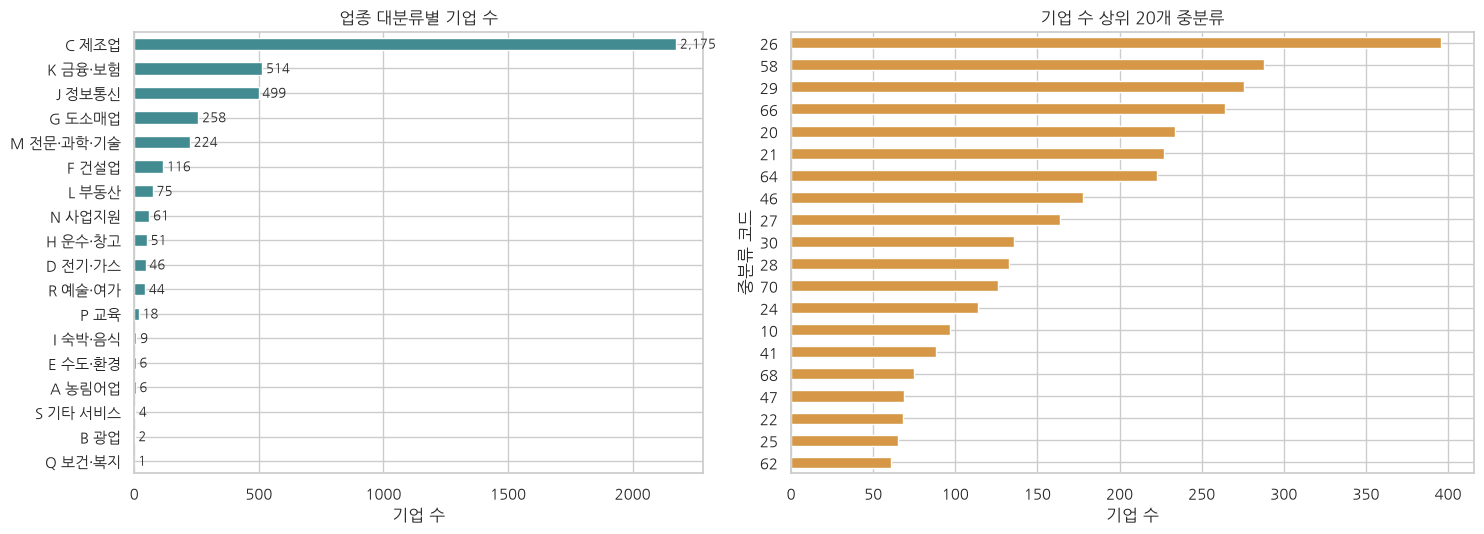

중분류 개수: 64 | 기업 10곳 미만 중분류: 15 | 그 중분류에 속한 기업: 50
금융·보험(중분류 64~66) 기업: 514곳 (12.5%)


In [14]:
# 기업 단위(기업당 1행)로 업종 분포를 봅니다.
# ※ 원래 1-3의 '상장시장·업종 대분류 분포표' 셀에서 만들던 firm_level, industry_table을 이 셀로 옮겼습니다.
firm_level = panel_raw.drop_duplicates('기업고유코드')
industry_table = pd.crosstab(firm_level['업종_대분류'], firm_level['상장시장'])[MARKET_ORDER]
industry_table['합계'] = industry_table.sum(axis=1)
industry_table = industry_table.sort_values('합계', ascending=False)
display(industry_table)
save_table(industry_table, '1_3_industry_market_firms')

mid_counts = firm_level['업종코드_중분류'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.2]})
industry_table['합계'].sort_values().plot.barh(ax=axes[0], color=MAIN_COLOR)
axes[0].set(title='업종 대분류별 기업 수', xlabel='기업 수', ylabel='')
for y, value in enumerate(industry_table['합계'].sort_values()):
    axes[0].text(value + 15, y, f'{value:,}', va='center', fontsize=9)
mid_counts.head(20).sort_values().plot.barh(ax=axes[1], color=SUB_COLOR)
axes[1].set(title='기업 수 상위 20개 중분류', xlabel='기업 수', ylabel='중분류 코드')
fig.tight_layout()
save_figure(fig, '1_3_industry')
plt.show()
print('중분류 개수:', mid_counts.size, '| 기업 10곳 미만 중분류:', (mid_counts < 10).sum(),
      '| 그 중분류에 속한 기업:', mid_counts[mid_counts < 10].sum())
finance_firms = firm_level['업종코드_중분류'].between(64, 66).sum()
print(f'금융·보험(중분류 64~66) 기업: {finance_firms:,}곳 ({finance_firms / len(firm_level):.1%})')

### 1-5. 단위 변환과 0·음수 점검
금액은 **원 → 억 원**으로 바꿔서 봅니다. 뒤 절(1-6 파생 지표 분포, 1-7 극단값, 1-9 업종 비교)에서 쓰는 파생 지표도 여기서 만듭니다.
- 1인당 급여 = 급여총액 ÷ 직원수 (만 원)
- W/S = 인건비총액W ÷ 급여총액
- 영업이익률 = 영업이익 ÷ 매출액, 1인당 매출 = 매출액 ÷ 직원수 (억 원)

#### 파생 지표 생성

In [15]:
panel_raw = panel_raw.copy()
EOK_COLS = []
for col in MONEY_COLS:
    panel_raw[to_eok(col)] = panel_raw[col] / EOK
    EOK_COLS.append(to_eok(col))
valid_n = panel_raw['직원수'].gt(0)
valid_pay = panel_raw['급여총액(원)'].gt(0)
panel_raw['1인당급여_만'] = (panel_raw['급여총액(원)'] / panel_raw['직원수']).where(valid_n) / 1e4
panel_raw['W_S_비율'] = (panel_raw['인건비총액W(원)'] / panel_raw['급여총액(원)']).where(valid_pay)
panel_raw['영업이익률'] = (panel_raw['영업이익(원)'] / panel_raw['매출액(원)']).where(
    panel_raw['매출액(원)'].gt(0))
panel_raw['1인당매출_억'] = (panel_raw['매출액(원)'] / panel_raw['직원수']).where(valid_n) / EOK
DERIVED_COLS = ['1인당급여_만', 'W_S_비율', '영업이익률', '1인당매출_억']

#### 기술통계표 (금액: 억 원, 직원수: 명)

In [16]:
describe_table = panel_raw[EOK_COLS + COUNT_COLS].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
describe_table['skew'] = panel_raw[EOK_COLS + COUNT_COLS].skew()
display(describe_table)
save_table(describe_table, '1_5_describe')
display(panel_raw[DERIVED_COLS].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(3))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew
급여총액_억,"31,147.000","2,908.788","179,010.405",0.000,0.047,5.596,31.977,82.040,229.129,"2,017.519","10,414.164","25,571,435.960",111.823
인건비총액W_억,"14,425.000",637.291,"5,333.971",0.014,7.103,16.928,48.523,105.538,261.601,"1,629.560","8,036.433","235,875.250",26.924
영업이익_억,"25,088.000","3,785.213","845,006.223","-44,225,193.640",-630.920,-140.967,-11.336,33.480,154.714,"1,219.969","8,012.130","126,305,481.300",127.401
매출액_억,"24,537.000","25,279.105","2,136,402.252",-0.643,0.000,49.369,304.102,853.576,"2,587.896","20,987.341","133,500.223","324,310,356.790",144.292
자산총계_억,"25,553.000","68,811.563","6,340,259.288",0.000,80.554,237.955,707.538,"1,508.420","4,052.761","38,357.760","297,480.291","950,284,993.730",138.367
이자비용_억,"23,360.000",918.721,"107,311.626",0.000,0.000,0.024,1.443,7.177,28.351,376.085,"2,938.409","16,393,347.080",152.608
감가상각비_억,"31,162.000","4,399.980","590,722.418","-6,494.300",0.000,0.193,4.893,16.231,58.343,653.272,"4,430.138","103,894,394.000",174.622
세금과공과_억,"27,864.000",50.299,"4,186.427",-450.250,0.000,0.037,0.637,2.035,7.334,79.616,497.735,"698,490.300",166.671
대손상각비_억,"27,024.000",195.556,"9,872.794","-74,761.400",-91.342,-13.303,-0.224,0.671,7.895,102.682,"1,218.274","896,235.000",78.441
직원수,"31,633.000",887.186,"25,474.537",0.000,1.000,13.000,67.000,161.000,399.000,"2,586.000","9,725.000","3,628,960.000",127.078


,count,mean,std,min,1%,25%,50%,75%,99%,max
1인당급여_만,"31,083.000","285,582.070","21,553,701.064",0.000,4.494,"4,138.321","5,164.638","6,590.254","16,555.882","2,346,003,299.083"
W_S_비율,"14,338.000","6,397.562","155,351.255",0.000,0.331,1.118,1.262,1.433,"1,171.028","15,482,664.384"
영업이익률,"24,045.000",-3.180,157.658,"-17,953.979",-6.658,-0.022,0.037,0.097,0.724,3.823
1인당매출_억,"24,207.000",799.976,"105,531.493",-0.129,0.007,2.614,4.702,8.626,69.570,"16,215,517.840"


#### 0·음수 점검표

In [17]:
sign_table = pd.DataFrame({
    '값 있음': panel_raw[NUMERIC_COLS].notna().sum(),
    '0': panel_raw[NUMERIC_COLS].eq(0).sum(),
    '음수': panel_raw[NUMERIC_COLS].lt(0).sum(),
})
sign_table['음수 비율(%)'] = sign_table['음수'] / sign_table['값 있음'] * 100
sign_table.index = [SHORT[c] for c in sign_table.index]
display(sign_table)

,값 있음,0,음수,음수 비율(%)
직원수,31633,9,0,0.000
급여총액,31147,13,0,0.000
인건비총액W,14425,0,0,0.000
영업이익,25088,2,7546,30.078
매출액,24537,274,1,0.004
자산총계,25553,1,0,0.000
이자비용,23360,527,0,0.000
감가상각비,31162,12,110,0.353
세금과공과,27864,7,137,0.492
대손상각비,27024,91,8815,32.619


> 음수가 정상일 수 있는 컬럼은 영업이익과 대손상각비(충당금 환입)뿐입니다. **감가상각비 음수·0은 추출 오류일 가능성이 큽니다.**
> 여기서는 **점검만 하고 값은 그대로 둡니다.** 처리는 EDA를 모두 본 뒤 2장 전처리에서 합니다(1-6 분포, 1-7 급변, 1-11 시계열 안정성에서 감가상각비 문제가 어떻게 드러나는지 먼저 확인).

### 1-6. 수치형 분포와 로그변환 전후 비교

#### 수치형 변수 원본 분포 (1~99백분위 표시)

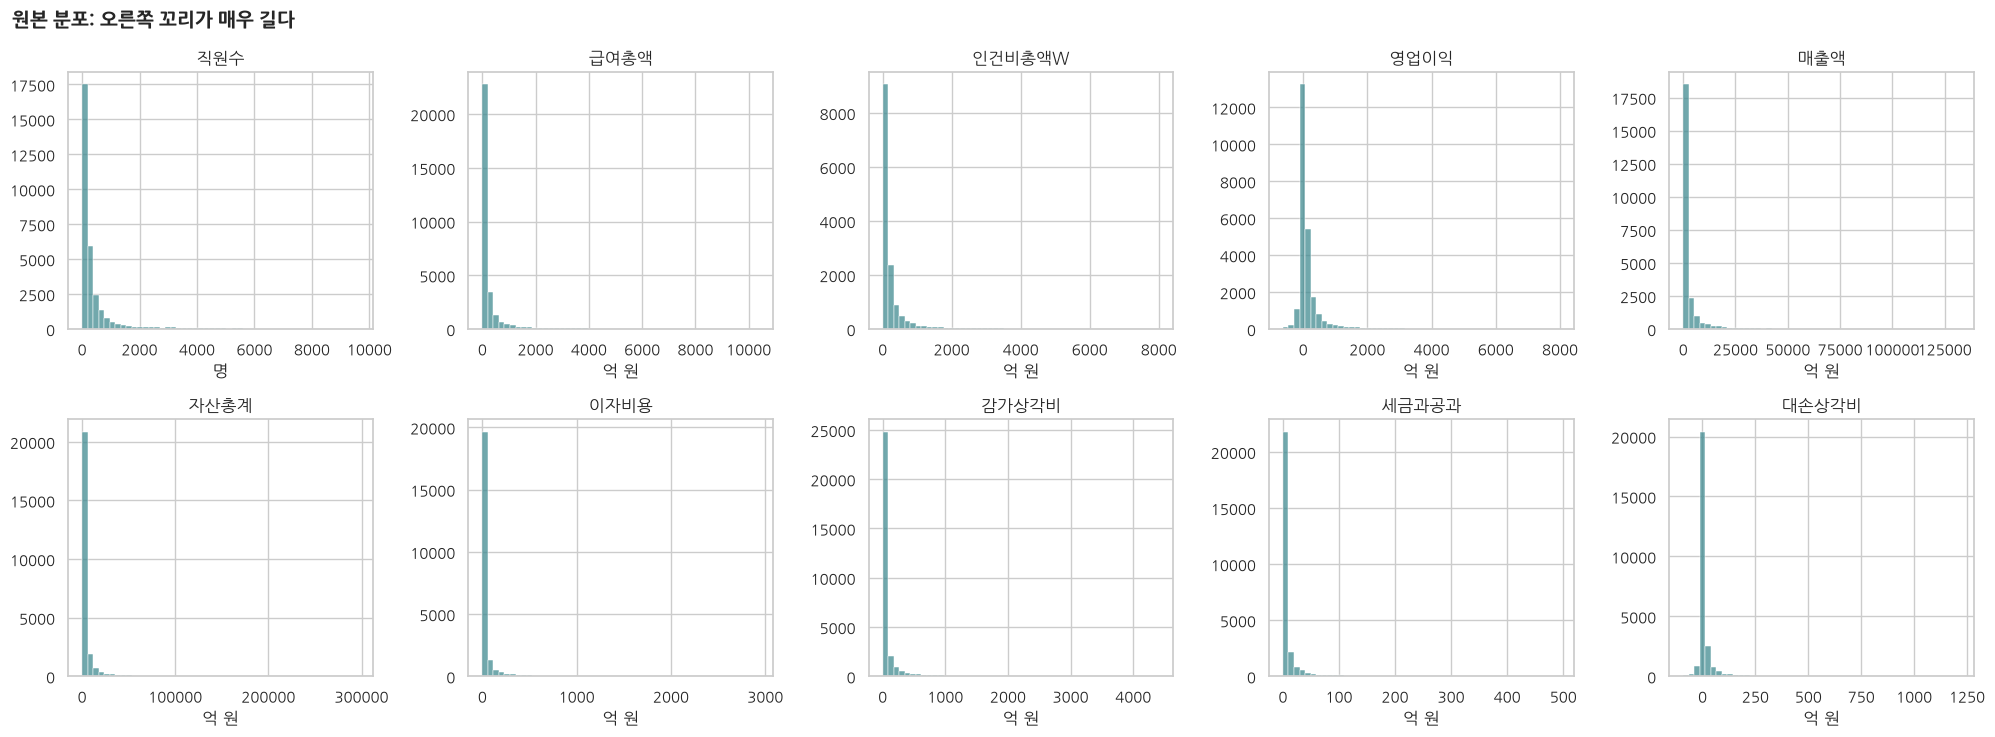

In [18]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    values = panel_raw[to_eok(col) if col in MONEY_COLS else col].dropna()
    lo, hi = values.quantile([.01 if values.min() < 0 else 0, .99])
    sns.histplot(values[values.between(lo, hi)], bins=50, ax=ax, color=MAIN_COLOR, edgecolor=None)
    ax.set(title=SHORT[col], xlabel='명' if col == '직원수' else '억 원', ylabel='')
fig.suptitle('원본 분포: 오른쪽 꼬리가 매우 길다', x=0.01, ha='left', fontsize=14, fontweight='bold')
fig.tight_layout()
save_figure(fig, '1_6_raw_distribution')
plt.show()

#### 로그변환 전후 왜도 비교표

In [19]:
log_rows, log_values = [], {}
for col in NUMERIC_COLS:
    values = panel_raw[col].dropna()
    has_negative = values.lt(0).any()
    transformed = signed_log(values) if has_negative else np.log1p(values.clip(lower=0))
    log_values[col] = transformed
    log_rows.append({'변수': SHORT[col], '변환': 'sign·log1p|x|' if has_negative else 'log1p',
                     'raw_skew': values.skew(), 'log_skew': transformed.skew()})
log_table = pd.DataFrame(log_rows).set_index('변수')
display(log_table)
save_table(log_table, '1_6_skew')

,변환,raw_skew,log_skew
변수,,,
직원수,log1p,127.078,0.122
급여총액,log1p,111.823,-1.987
인건비총액W,log1p,26.924,0.628
영업이익,sign·log1p|x|,127.401,-0.858
매출액,sign·log1p|x|,144.292,-5.142
자산총계,log1p,138.367,0.505
이자비용,log1p,152.608,-2.791
감가상각비,sign·log1p|x|,174.622,-5.654
세금과공과,sign·log1p|x|,166.671,-5.934


#### 로그변환 후 분포

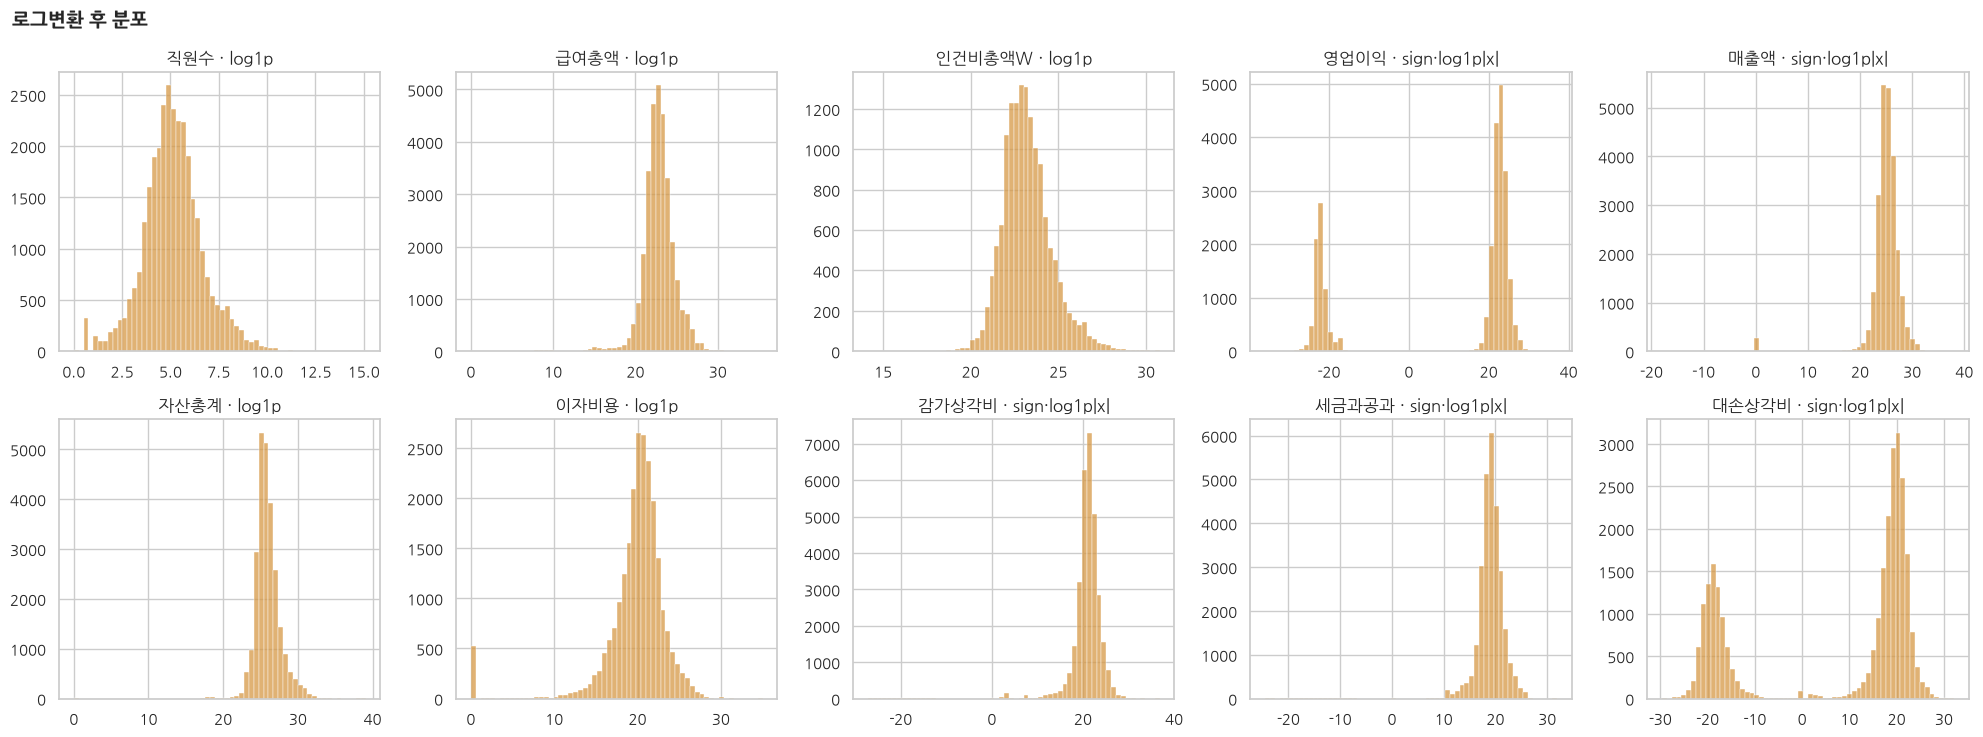

In [20]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    sns.histplot(log_values[col], bins=60, ax=ax, color=SUB_COLOR, edgecolor=None)
    ax.set(title=f'{SHORT[col]} · {log_table.loc[SHORT[col], "변환"]}', xlabel='', ylabel='')
fig.suptitle('로그변환 후 분포', x=0.01, ha='left', fontsize=14, fontweight='bold')
fig.tight_layout()
save_figure(fig, '1_6_log_distribution')
plt.show()

> - 영업이익과 대손상각비는 0을 기준으로 양쪽이 갈라져 변환 뒤에도 두 봉우리입니다. 흑자와 적자 기업이 다른 집단처럼 보인다는 점을 이후 분석에서 고려해야 합니다.
> - 나머지 규모 변수(직원수·급여총액·자산·W)는 로그변환 뒤 대체로 종 모양이 됩니다. 급여총액의 왼쪽 꼬리는 단위 오류 행 때문입니다.

#### 파생 지표 분포 (표시 범위 지정)

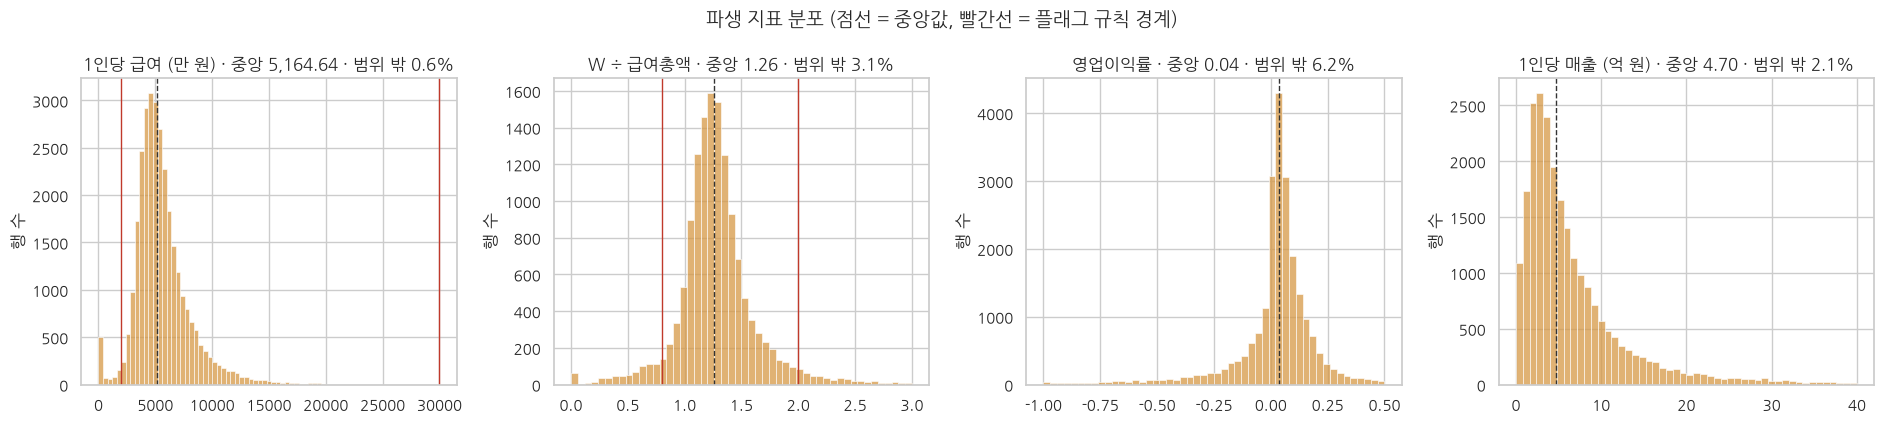

In [21]:
derived_specs = {
    '1인당급여_만': ('1인당 급여 (만 원)', (0, 20000)),
    'W_S_비율': ('W ÷ 급여총액', (0, 3)),
    '영업이익률': ('영업이익률', (-1, 0.5)),
    '1인당매출_억': ('1인당 매출 (억 원)', (0, 40)),
}
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, (col, (label, (lo, hi))) in zip(axes, derived_specs.items()):
    values = panel_raw[col].replace([np.inf, -np.inf], np.nan).dropna()
    inside = values.between(lo, hi)
    sns.histplot(values[inside], bins=50, binrange=(lo, hi), color=SUB_COLOR, ax=ax)
    ax.axvline(values.median(), color='#333', ls='--', lw=1)
    ax.set(title=f'{label} · 중앙 {values.median():,.2f} · 범위 밖 {1 - inside.mean():.1%}',
           xlabel='', ylabel='행 수')
for x in PAY_RANGE_MAN:
    axes[0].axvline(x, color='#c0392b', lw=1)
for x in WS_RANGE:
    axes[1].axvline(x, color='#c0392b', lw=1)
fig.suptitle('파생 지표 분포 (점선 = 중앙값, 빨간선 = 플래그 규칙 경계)', fontsize=14)
fig.tight_layout()
save_figure(fig, '1_6_derived_distribution')
plt.show()

### 1-7. 이상치 점검

#### 변수별 이상치 점검표 (로그 척도 IQR)

In [22]:
outlier_rows = []
for col in NUMERIC_COLS:
    values = log_values[col]
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    raw = panel_raw[col].dropna()
    outlier_rows.append({
        '변수': SHORT[col], '값 있음': len(values),
        '하단 이탈': (values < q1 - 1.5 * iqr).sum(), '상단 이탈': (values > q3 + 1.5 * iqr).sum(),
        'p99 대비 최대값 배수': raw.max() / raw.quantile(.99) if raw.quantile(.99) > 0 else np.nan,
    })
outlier_table = pd.DataFrame(outlier_rows).set_index('변수')
display(outlier_table)
save_table(outlier_table, '1_7_outliers')

,값 있음,하단 이탈,상단 이탈,p99 대비 최대값 배수
변수,,,,
직원수,31633,574,585,373.158
급여총액,31147,745,675,"2,455.448"
인건비총액W,14425,53,376,29.351
영업이익,25088,0,0,"15,764.283"
매출액,24537,589,487,"2,429.287"
자산총계,25553,170,1043,"3,194.447"
이자비용,23360,1069,284,"5,578.988"
감가상각비,31162,1347,512,"23,451.727"
세금과공과,27864,1071,504,"1,403.338"


#### 변수별 상위 극단값

In [23]:
extreme_rows = []
for col in ['매출액_억', '자산총계_억', '영업이익_억', '급여총액_억', '직원수']:
    top = panel_raw.nlargest(3, col)[['기업명', '사업연도', '상장시장', col]].rename(columns={col: '값'})
    top.insert(0, '변수', col)
    extreme_rows.append(top)
display(pd.concat(extreme_rows).reset_index(drop=True).round(1))

,변수,기업명,사업연도,상장시장,값
0,매출액_억,소프트센,2022,코스닥,"324,310,356.800"
1,매출액_억,엘에이티,2017,코넥스,"68,923,935.400"
2,매출액_억,제이앤케이인더스트리,2021,기타,"44,837,348.100"
3,자산총계_억,소프트센,2022,코스닥,"950,284,993.700"
4,자산총계_억,제이앤케이인더스트리,2021,기타,"350,559,475.900"
5,자산총계_억,엘에이티,2017,코넥스,"27,994,281.200"
6,영업이익_억,소프트센,2022,코스닥,"126,305,481.300"
7,영업이익_억,엘에이티,2017,코넥스,"1,782,191.900"
8,영업이익_억,SK하이닉스,2025,코스피,"440,074.100"
9,급여총액_억,글로앤웰,2017,기타,"25,571,436.000"


#### 같은 기업 안 급등·급락 점검 (단위 오류 의심)
같은 기업의 다른 연도 중앙값보다 **30배** 넘게 크거나 작은 값을 찾습니다(관측 3년 이상인 기업만).
천 원·원 단위가 섞인 경우가 대부분으로 보이지만 분할·합병처럼 실제 변화도 섞여 있어, 목록을 원문과 대조해야 합니다.

In [24]:
JUMP_COLS = ['직원수', '급여총액(원)', '매출액(원)', '자산총계(원)', '인건비총액W(원)']
jump_rows, jump_flags = [], pd.DataFrame(index=panel_raw.index)
for col in JUMP_COLS:
    positive = panel_raw[col].where(panel_raw[col] > 0)
    grouped = positive.groupby(panel_raw['기업고유코드'])
    ratio = positive / grouped.transform('median')
    enough = grouped.transform('count').ge(JUMP_MIN_OBS)
    flag = (enough & ((ratio > JUMP_RATIO) | (ratio < 1 / JUMP_RATIO))).fillna(False)
    jump_flags[col] = flag
    jump_rows.append({'변수': SHORT[col], f'{JUMP_RATIO}배 이탈 행': flag.sum(),
                      '기업': panel_raw.loc[flag, '기업고유코드'].nunique(),
                      '그중 급여이상 플래그 없음': (flag & panel_raw['플래그_급여이상'].eq(0)).sum()})
jump_table = pd.DataFrame(jump_rows).set_index('변수')
display(jump_table)
panel_raw['급변의심'] = jump_flags.any(axis=1)
print(f"급변 의심 행: {panel_raw['급변의심'].sum():,} "
      f"({panel_raw['급변의심'].mean():.1%}), 기업 {panel_raw.loc[panel_raw['급변의심'], '기업고유코드'].nunique():,}곳")
panel_raw.loc[panel_raw['급변의심'], ['기업고유코드', '기업명', '사업연도'] + JUMP_COLS].to_csv(
    OUTPUT_DIR / '1_7_jump_suspects.csv', index=False, encoding='utf-8-sig')

,30배 이탈 행,기업,그중 급여이상 플래그 없음
변수,,,
직원수,134,76,110
급여총액,583,448,51
매출액,80,58,78
자산총계,12,9,12
인건비총액W,18,12,13


급변 의심 행: 754 (2.3%), 기업 534곳


#### 급변 사례 상위

In [25]:
display(panel_raw.loc[panel_raw['급변의심'],
        ['기업명', '사업연도', '매출액_억', '자산총계_억', '영업이익_억', '급여총액_억', '직원수']]
        .sort_values('매출액_억', ascending=False).head(10).round(1))

,기업명,사업연도,매출액_억,자산총계_억,영업이익_억,급여총액_억,직원수
10235,소프트센,2022,"324,310,356.800","950,284,993.700","126,305,481.300",14.600,20.000
29824,엘에이티,2017,"68,923,935.400","27,994,281.200","1,782,191.900",9.500,27.000
13155,제이앤케이인더스트리,2021,"44,837,348.100","350,559,475.900","-44,225,193.600",53.600,122.000
16274,대산F&B,2023,"1,160,546.000","516,648.600","-16,350.400",26.300,47.000
29390,네오크레마,2022,"239,969.100","787,324.100","15,500.500",24.600,62.000
12319,한국가스공사,2016,"201,773.500","376,308.800","8,748.300",2.800,"3,693.000"
10581,BGF,2016,"49,412.700","17,075.500","1,969.500",955.900,"1,876.000"
10580,BGF,2015,"42,576.300","14,602.000","1,747.800",869.500,"1,778.000"
8515,HDC,2017,"41,259.100","53,521.800","5,433.500","1,505.600","1,781.000"
8514,HDC,2016,"35,072.500","47,890.300","4,069.100","1,214.900","1,751.000"


### 1-9. 업종별 비교
비교군이 **업종(중분류) × 규모**이므로 업종 기준으로 봅니다. 중분류 64개는 한눈에 안 들어와서 **대분류**로 묶고, 기업이 적은 대분류는 제외합니다.

#### 업종 대분류별 기술통계표

In [26]:
MAJOR_MIN_FIRMS = 30
major_counts = panel_raw.drop_duplicates('기업고유코드')['업종_대분류'].value_counts()
INDUSTRY_ORDER = list(major_counts[major_counts >= MAJOR_MIN_FIRMS].index)
INDUSTRY_COLORS = dict(zip(INDUSTRY_ORDER, sns.color_palette('tab20', len(INDUSTRY_ORDER))))
print(f'기업 {MAJOR_MIN_FIRMS}곳 이상인 대분류 {len(INDUSTRY_ORDER)}개 / 전체 {major_counts.size}개')
print('제외:', [f'{name}({n})' for name, n in major_counts[major_counts < MAJOR_MIN_FIRMS].items()])

industry_view = panel_raw[panel_raw['업종_대분류'].isin(INDUSTRY_ORDER)]
industry_stats = industry_view.groupby('업종_대분류').agg(**{
    '기업수': ('기업고유코드', 'nunique'), '행수': ('기업고유코드', 'size'),
    '직원수_중앙': ('직원수', 'median'), '1인당급여_중앙_만': ('1인당급여_만', 'median'),
    '매출_중앙_억': ('매출액_억', 'median'), '자산_중앙_억': ('자산총계_억', 'median'),
    '영업이익률_중앙': ('영업이익률', 'median'),
    '적자_비율': ('영업이익(원)', lambda s: s.lt(0).mean()),
    'W_S_중앙': ('W_S_비율', 'median'),
    'W_결측률': ('인건비총액W(원)', lambda s: s.isna().mean()),
}).reindex(INDUSTRY_ORDER)
display(industry_stats.round(3))
save_table(industry_stats, '1_9_industry_stats')

기업 30곳 이상인 대분류 11개 / 전체 18개
제외: ['P 교육(18)', 'I 숙박·음식(9)', 'A 농림어업(6)', 'E 수도·환경(6)', 'S 기타 서비스(4)', 'B 광업(2)', 'Q 보건·복지(1)']


,기업수,행수,직원수_중앙,1인당급여_중앙_만,매출_중앙_억,자산_중앙_억,영업이익률_중앙,적자_비율,W_S_중앙,W_결측률
업종_대분류,,,,,,,,,,
C 제조업,2175,18408,172.000,"5,042.873",984.477,"1,547.038",0.035,0.248,1.234,0.469
K 금융·보험,514,3053,165.000,"8,448.219",517.375,"5,853.532",0.280,0.108,1.381,0.904
J 정보통신,499,3888,140.000,"5,111.313",388.743,845.566,0.047,0.243,1.282,0.637
G 도소매업,258,2250,98.000,"4,564.320",860.633,"1,285.227",0.020,0.280,1.375,0.516
M 전문·과학·기술,224,1551,67.000,"5,230.536",242.483,"1,099.912",0.016,0.362,1.348,0.542
F 건설업,116,944,306.000,"6,060.432","3,260.139","3,583.965",0.031,0.174,1.446,0.581
L 부동산,75,405,20.000,"5,410.296",172.967,"2,783.360",0.481,0.109,1.408,0.837
N 사업지원,61,415,472.000,"4,109.157",791.637,"1,050.033",0.083,0.176,1.264,0.798
H 운수·창고,51,412,529.000,"5,768.037","5,550.884","6,203.666",0.032,0.170,1.309,0.536


#### 업종별 1인당 급여·영업이익률 분포

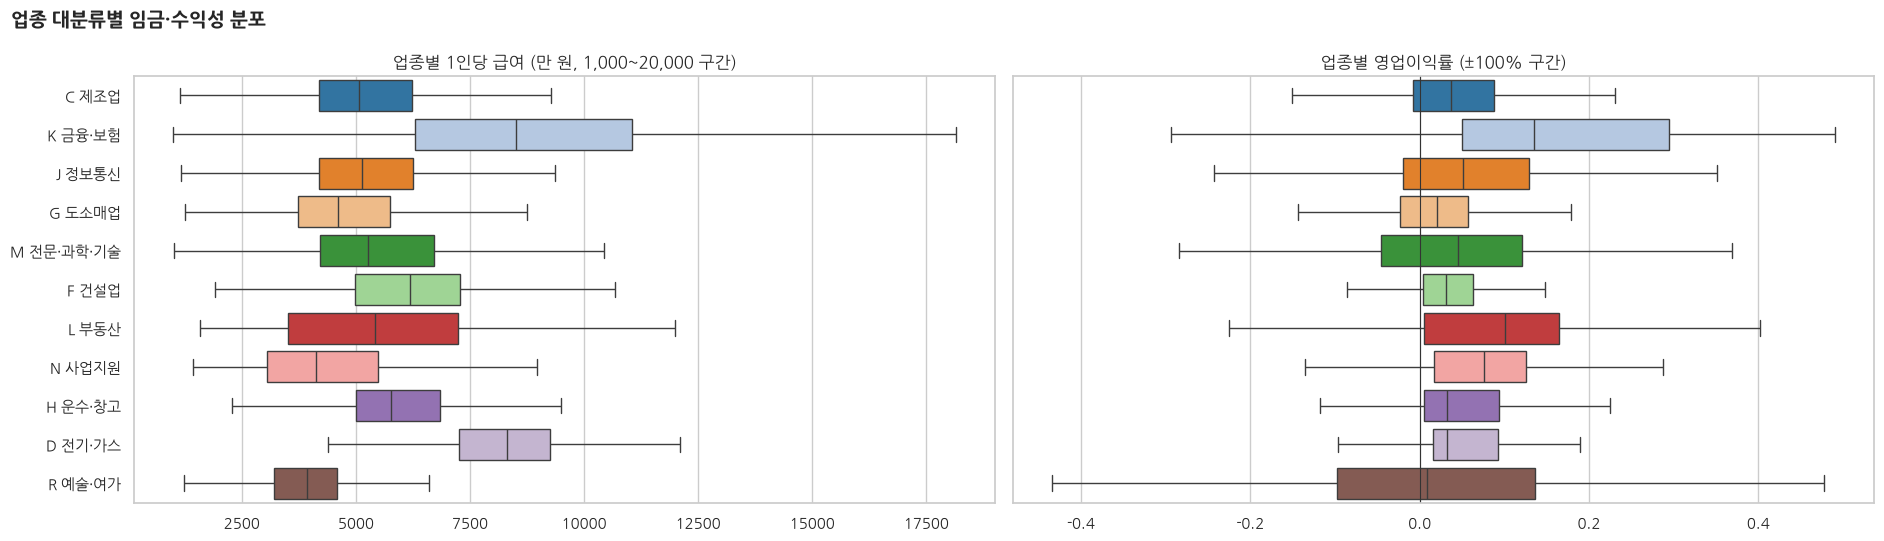

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(19, 5.5))
pay = industry_view[industry_view['1인당급여_만'].between(1000, 20000)]
sns.boxplot(data=pay, y='업종_대분류', x='1인당급여_만', order=INDUSTRY_ORDER,
            hue='업종_대분류', palette=INDUSTRY_COLORS, legend=False, showfliers=False, ax=axes[0])
axes[0].set(title='업종별 1인당 급여 (만 원, 1,000~20,000 구간)', xlabel='', ylabel='')
margin = industry_view[industry_view['영업이익률'].between(-1, 0.5)]
sns.boxplot(data=margin, y='업종_대분류', x='영업이익률', order=INDUSTRY_ORDER,
            hue='업종_대분류', palette=INDUSTRY_COLORS, legend=False, showfliers=False, ax=axes[1])
axes[1].axvline(0, color='#333', lw=.8)
axes[1].set(title='업종별 영업이익률 (±100% 구간)', xlabel='', ylabel='')
axes[1].set_yticklabels([])
fig.suptitle('업종 대분류별 임금·수익성 분포', x=0.01, ha='left', fontsize=14, fontweight='bold')
fig.tight_layout()
save_figure(fig, '1_9_industry_box')
plt.show()

#### 업종 × 연도 1인당 급여 중앙값

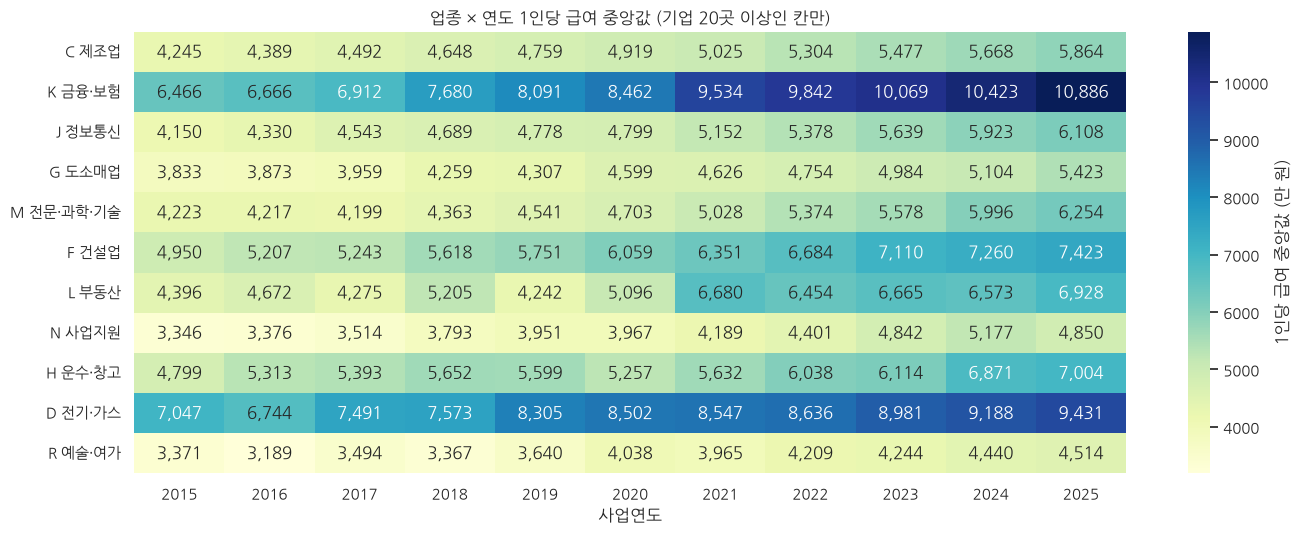

In [28]:
pay_pivot = industry_view.pivot_table(index='업종_대분류', columns='사업연도',
                                      values='1인당급여_만', aggfunc='median').reindex(INDUSTRY_ORDER)
pay_n = industry_view.pivot_table(index='업종_대분류', columns='사업연도',
                                  values='1인당급여_만', aggfunc='size').reindex(INDUSTRY_ORDER)
fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(pay_pivot.where(pay_n >= 20), annot=True, fmt=',.0f', cmap='YlGnBu',
            cbar_kws={'label': '1인당 급여 중앙값 (만 원)'}, ax=ax)
ax.set(title='업종 × 연도 1인당 급여 중앙값 (기업 20곳 이상인 칸만)', xlabel='사업연도', ylabel='')
fig.tight_layout()
save_figure(fig, '1_9_industry_pay_heatmap')
plt.show()
save_table(pay_pivot, '1_9_industry_pay')

#### 업종 그룹(중분류 우선) 기준 1인당 급여·영업이익률
산술식 비교군과 가설검정은 대분류가 아니라 **중분류**를 기준으로 씁니다(제조 4군 폐기, 2026-11-20). 기업이 21곳 이상인 중분류는 그대로, 나머지는 대분류로 묶어 봅니다.

In [29]:
# [1-9-b] 업종 그룹(중분류 우선) 기준 — 4장 가설검정·6장 모델과 같은 방향의 업종 구분 (2025년, 기업 단위)
_y = panel_raw.loc[panel_raw['사업연도'].eq(YEAR_MAX)].copy()
_n = _y.groupby('업종코드_중분류')['기업고유코드'].nunique()
_big = set(_n[_n.ge(F.PEER_COUNT + 1)].index)          # 기업 21곳 이상인 중분류는 그대로, 나머지는 대분류
_y['업종그룹'] = np.where(_y['업종코드_중분류'].isin(_big),
                       _y['업종코드_중분류'].map(lambda c: f"{F.ksic_section(c)}{c:02d} {F.IND2_NAME.get(c, '')}"),
                       _y['업종코드_중분류'].map(ksic_major))
group_view = (_y.groupby('업종그룹').agg(기업=('기업고유코드', 'nunique'), 급여_중앙_만원=('1인당급여_만', 'median'),
                                     영업이익률_중앙=('영업이익률', 'median')).sort_values('기업', ascending=False))
print(f'업종 그룹 {len(group_view)}개 (중분류 {len(_big)}개 + 나머지 대분류). 위의 대분류 표는 개요용이고, 비교·검정은 이 방향의 기준을 씁니다.')
display(group_view.round(3))
save_table(group_view, '1_9_industry_group_stats')


업종 그룹 47개 (중분류 34개 + 나머지 대분류). 위의 대분류 표는 개요용이고, 비교·검정은 이 방향의 기준을 씁니다.


,기업,급여_중앙_만원,영업이익률_중앙
업종그룹,,,
C26 전자부품·컴퓨터·통신장비(반도체 등),347,"5,707.740",0.015
C29 기타 기계·장비,243,"6,088.485",0.029
J58 출판(게임·소프트웨어 포함),239,"5,997.737",0.035
C21 의료용 물질·의약품,205,"5,726.531",0.030
C20 화학물질·화학제품,200,"6,118.849",0.038
K64,186,"10,449.153",0.460
G46 도매,146,"5,293.515",0.013
C27 의료·정밀·광학기기,142,"5,398.393",0.025
C30 자동차·트레일러,124,"6,715.445",0.027


### 1-10. 변수 간 관계

#### 수치형 변수 순위상관 (Spearman)

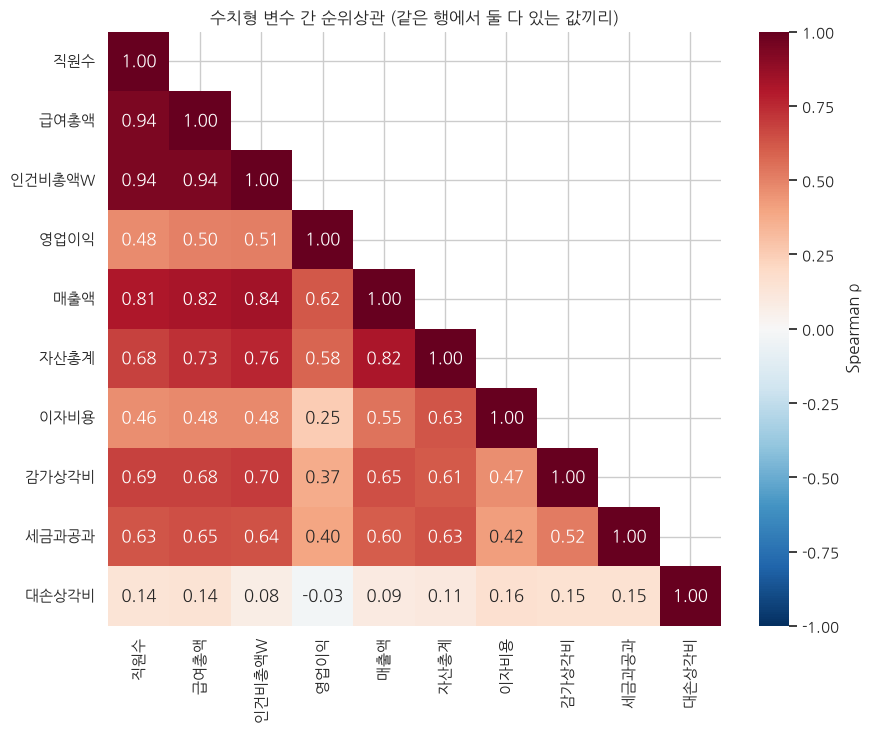

In [30]:
corr = panel_raw[NUMERIC_COLS].corr(method='spearman')
corr.index = corr.columns = [SHORT[c] for c in NUMERIC_COLS]
fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            ax=ax, cbar_kws={'label': 'Spearman ρ'})
ax.set_title('수치형 변수 간 순위상관 (같은 행에서 둘 다 있는 값끼리)')
fig.tight_layout()
save_figure(fig, '1_10_spearman')
plt.show()
save_table(corr, '1_10_spearman')

#### 규모 변수 간 관계 (로그 척도)

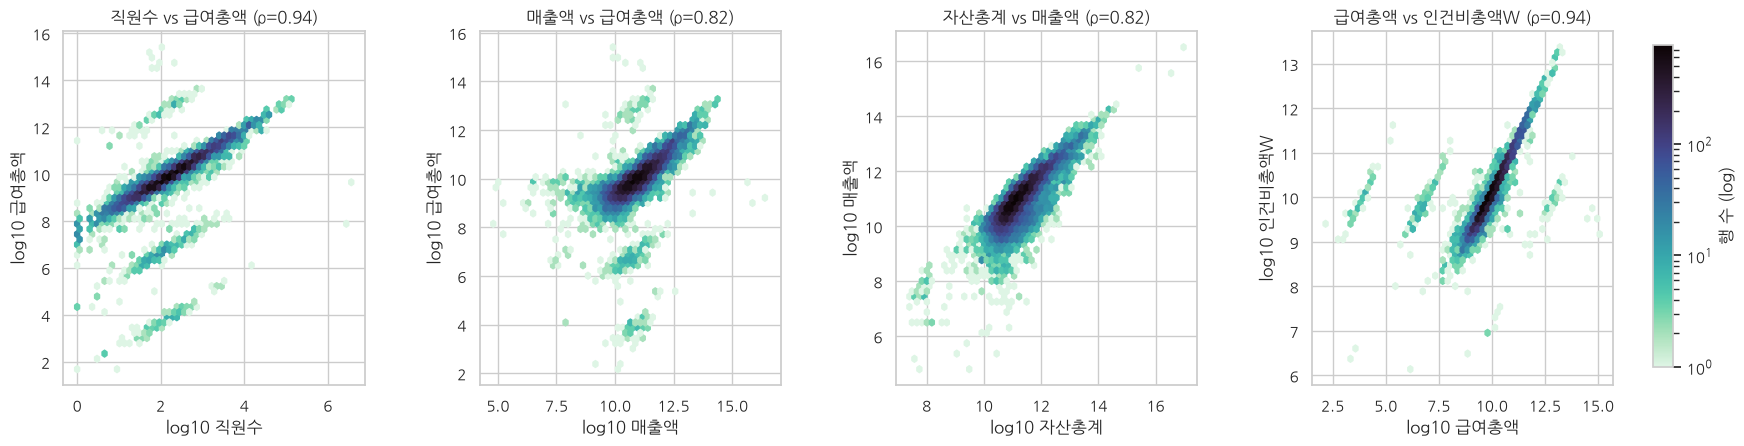

In [31]:
pairs = [('직원수', '급여총액(원)'), ('매출액(원)', '급여총액(원)'),
         ('자산총계(원)', '매출액(원)'), ('급여총액(원)', '인건비총액W(원)')]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (x, y) in zip(axes, pairs):
    sub = panel_raw[[x, y]].dropna()
    sub = sub[(sub[x] > 0) & (sub[y] > 0)]
    hb = ax.hexbin(np.log10(sub[x]), np.log10(sub[y]), gridsize=55, bins='log',
                   cmap='mako_r', mincnt=1)
    rho = stats.spearmanr(sub[x], sub[y])[0]
    ax.set(title=f'{SHORT[x]} vs {SHORT[y]} (ρ={rho:.2f})',
           xlabel=f'log10 {SHORT[x]}', ylabel=f'log10 {SHORT[y]}')
fig.subplots_adjust(wspace=0.38, right=0.9)
fig.colorbar(hb, cax=fig.add_axes([0.92, 0.15, 0.01, 0.7]), label='행 수 (log)')
save_figure(fig, '1_10_scale_pairs')
plt.show()

> **직원수 vs 급여총액, 급여총액 vs 인건비총액W 그림에 본 띠와 평행한 띠가 여러 개 보입니다.** 띠 사이 간격이 log10 기준 약 3(1,000배)이라 원·천 원 단위가 섞인 행으로 보입니다. 1-8에서 확인했듯 대부분 `플래그_급여이상`·`인건비W_상태`로 걸러지지만, 1-7의 급변 점검에서 보듯 플래그 밖에도 남아 있습니다.

### 1-11. 시계열 안정성
K=3(3년 합산)이 왜 필요한지 보여 주는 절입니다.

#### 전년 대비 변화율 분포표

In [32]:
ordered = panel_raw.sort_values(KEY_COLS).copy()
consecutive = ordered.groupby('기업고유코드')['사업연도'].diff().eq(1)
change_rows = []
for col in ['직원수', '급여총액(원)', '매출액(원)', '자산총계(원)', '인건비총액W(원)', '영업이익(원)']:
    prev = ordered.groupby('기업고유코드')[col].shift()
    valid = consecutive & ordered[col].notna() & prev.notna()
    if col == '영업이익(원)':
        sign_flip = (np.sign(ordered[col]) != np.sign(prev))[valid]
        change_rows.append({'변수': SHORT[col], '연속 연도 쌍': valid.sum(),
                            '흑자↔적자 전환(%)': sign_flip.mean() * 100})
        continue
    valid &= prev > 0
    growth = (ordered[col] / prev - 1)[valid]
    change_rows.append({'변수': SHORT[col], '연속 연도 쌍': valid.sum(),
                        '변화율 절댓값 중앙(%)': growth.abs().median() * 100,
                        '2배 이상 증가(%)': growth.gt(1).mean() * 100,
                        '절반 이하로 감소(%)': growth.lt(-.5).mean() * 100})
display(pd.DataFrame(change_rows).set_index('변수'))

,연속 연도 쌍,변화율 절댓값 중앙(%),2배 이상 증가(%),절반 이하로 감소(%),흑자↔적자 전환(%)
변수,,,,,
직원수,27604,6.631,1.253,1.815,NaN
급여총액,27263,10.495,3.147,3.176,NaN
매출액,21048,13.173,3.098,3.454,NaN
자산총계,22134,7.985,1.974,0.858,NaN
인건비총액W,10909,9.330,1.384,1.329,NaN
영업이익,21820,NaN,NaN,NaN,19.913


#### 전년 값과의 순위상관

In [33]:
persist_rows = []
for col in NUMERIC_COLS:
    prev = ordered.groupby('기업고유코드')[col].shift()
    cur = ordered[col]
    valid = consecutive & cur.notna() & prev.notna()
    if valid.sum() < 50:
        continue
    persist_rows.append({'변수': SHORT[col], '쌍': valid.sum(),
                         'Spearman ρ (t, t-1)': stats.spearmanr(cur[valid], prev[valid])[0]})
persist_table = pd.DataFrame(persist_rows).set_index('변수').sort_values(
    'Spearman ρ (t, t-1)', ascending=False)
display(persist_table)
save_table(persist_table, '1_11_persistence')

,쌍,"Spearman ρ (t, t-1)"
변수,,
자산총계,22135,0.980
인건비총액W,10909,0.977
직원수,27610,0.976
매출액,21187,0.969
급여총액,27270,0.935
이자비용,19768,0.913
세금과공과,23918,0.907
감가상각비,27219,0.886
영업이익,21820,0.762


> 자산·직원수·매출·인건비총액W는 해마다 거의 같은 순위를 유지합니다(ρ 0.97 이상). 반면 **영업이익(ρ 0.76)은 불안정하고, 기업-연도의 약 20%에서 흑자↔적자가 뒤집힙니다.**
>
> 산술식의 부가가치 A = W + OP + D에서 변동의 대부분은 OP에서 옵니다. **K=3 합산이 가장 필요한 컬럼이 영업이익**이라는 직접적인 근거입니다.

## 2️⃣ 전처리

EDA에서 확인한 감가상각비 문제(1-5 음수·0, 1-6 극단 왜도, 1-11 낮은 전년 순위상관)를 여기서 처리합니다. 규칙은 팀 산술식 최종본(v3)의 '감가 이상 규칙'과 같게 맞춥니다. **행은 지우지 않고 감가상각비 값만 비웁니다.**

In [34]:
# [2-0] 전처리 전 감가상각비 상태 저장 (전후 비교용)
DEP = '감가상각비(원)'
def dep_profile(df):
    s = df[DEP]
    o = df.sort_values(KEY_COLS)
    prev = o.groupby('기업고유코드')[DEP].shift()
    ok = prev.notna() & o[DEP].notna()
    return {'값 있는 행': int(s.notna().sum()), '음수': int(s.lt(0).sum()), '0': int(s.eq(0).sum()),
            '원본 왜도': round(float(s.skew()), 1),
            '전년 순위상관 ρ': round(float(o.loc[ok, DEP].corr(prev[ok], method='spearman')), 3)}
dep_before = dep_profile(panel_raw)


### 2-1. 감가상각비 이상값 비우기
아래 세 경우의 감가상각비 **값만** 비웁니다. 행(기업×연도)은 그대로 남습니다.
1. 음수
2. 패널의 `플래그_감가이상` = 1 (감가 > 매출 또는 감가 < 0)
3. 같은 기업의 중앙값(양수인 해, 관측 3년 이상)에서 **5배 넘게 크거나 1/5 미만**인 값 (0도 여기서 걸림)

- 매출 30% 규칙은 쓰지 않습니다(산술식 결정).
- 세금과공과·대손상각비는 손대지 않습니다. 산술식에서 이 둘은 g* 분모(D)에만 쓰이고, 없는 해는 0으로 봅니다.
- 5배는 산술식 문서에도 "근거 없는 임시값"으로 적혀 있어, 설정값(`DEP_RATIO`)으로 뺐습니다.

In [35]:
# [2-1] 감가상각비 이상값 비우기 — 산술식 최종본 규칙 (행은 유지)
DEP_RATIO = F.DEP_LIMIT        # 같은 기업 양수 중앙값 대비 이탈 배수 (formula.py)
DEP_MIN_OBS = F.DEP_MIN_OBS    # 중앙값을 믿을 수 있는 최소 관측 연수 (formula.py)

dep = panel_raw[DEP]
positive = dep.where(dep.gt(0))
firm_median = positive.groupby(panel_raw['기업고유코드']).transform('median')
firm_n = positive.groupby(panel_raw['기업고유코드']).transform('count')
ratio = dep / firm_median

rule_negative = dep.lt(0)
rule_flag = panel_raw['플래그_감가이상'].eq(1) & dep.notna() & ~rule_negative
rule_jump = (firm_n.ge(DEP_MIN_OBS) & (ratio.gt(DEP_RATIO) | ratio.lt(1 / DEP_RATIO))
             & ~rule_negative & ~rule_flag)
blank_mask = rule_negative | rule_flag | rule_jump

panel_raw['감가_비움사유'] = np.select([rule_negative, rule_flag, rule_jump],
                                   ['음수', '감가이상 플래그', f'{DEP_RATIO}배 이탈'], '')
dep_summary = pd.DataFrame({
    '비운 값': [rule_negative.sum(), rule_flag.sum(), rule_jump.sum(), blank_mask.sum()],
    '그중 원래 0': [0, (rule_flag & dep.eq(0)).sum(), (rule_jump & dep.eq(0)).sum(), (blank_mask & dep.eq(0)).sum()],
}, index=['① 음수', '② 감가이상 플래그(음수 제외)', f'③ {DEP_RATIO}배 이탈', '합계'])
dep_summary['값 있는 행 대비(%)'] = dep_summary['비운 값'] / dep.notna().sum() * 100
display(dep_summary.round(2))
print('남은 0:', int(dep.where(~blank_mask).eq(0).sum()), '| 비우기 전 값 있음:', int(dep.notna().sum()),
      '→ 후:', int((dep.notna() & ~blank_mask).sum()))

# 원문 대조용 목록 저장 (산술식의 f6_감가이상_비운행.csv와 같은 성격)
blanked = panel_raw.loc[blank_mask, KEY_COLS + ['기업명', '상장시장', '공시접수번호', DEP, '감가_비움사유']].copy()
blanked['같은기업_중앙값'] = firm_median[blank_mask]
blanked['중앙값_대비'] = ratio[blank_mask]
save_table(blanked, '1_5_dep_blanked', index=False)

# 값 비우기: 원 단위 컬럼과 1-5 앞에서 만든 억 원 컬럼을 같이 비웁니다
panel_raw.loc[blank_mask, [DEP, to_eok(DEP)]] = np.nan
assert not panel_raw[DEP].lt(0).any(), '감가상각비에 음수가 남아 있습니다.'
left_zero = panel_raw.loc[panel_raw[DEP].eq(0), ['기업명', '사업연도', '매출액(원)', '자산총계(원)']]
print('규칙으로 걸리지 않은 0 (같은 기업에 양수인 해가 3년 미만이라 중앙값 비교 불가):')
display(left_zero)
print(f'행 수는 그대로 {len(panel_raw):,}행 · {panel_raw["기업고유코드"].nunique():,}기업')

,비운 값,그중 원래 0,값 있는 행 대비(%)
① 음수,110,0,0.350
② 감가이상 플래그(음수 제외),225,0,0.720
③ 5배 이탈,2660,11,8.540
합계,2995,11,9.610


남은 0: 1 | 비우기 전 값 있음: 31162 → 후: 28167
규칙으로 걸리지 않은 0 (같은 기업에 양수인 해가 3년 미만이라 중앙값 비교 불가):


,기업명,사업연도,매출액(원),자산총계(원)
29542,선산,2019,NaN,NaN


행 수는 그대로 32,501행 · 4,109기업


### 2-2. 전처리 전후 비교
> 같은 기업 안에서 해마다 튀던 감가 값이 빠지면서 전년 순위상관이 올라가면, 규칙이 단위·추출 오류를 제대로 걸러 냈다는 근거가 됩니다.

In [36]:
# [2-2] 전처리 전후 비교
display(pd.DataFrame({'전처리 전': dep_before, '전처리 후': dep_profile(panel_raw)}))


,전처리 전,전처리 후
값 있는 행,"31,162.000","28,167.000"
음수,110.000,0.000
0,12.000,1.000
원본 왜도,174.600,43.200
전년 순위상관 ρ,0.886,0.976


## 3️⃣ EDA 요약

### 데이터 구조 (1-1)
- **32,501행 · 4,109기업 · 2015~2025년**, 업종 중분류 64개. 기업×연도 중복·완전 중복·공시접수번호 중복 모두 0건.
- **기업명·상장시장·업종코드가 기간 중 한 번도 바뀌지 않습니다(변경 기업 0곳).** 연도별 값이 아니라 현재 기준 하나로 들어가 있다는 뜻이라, 비교군은 '현재 업종' 기준입니다.
- 결측: 직원수 2.7%·급여총액 4.2%·감가상각비 4.1%는 거의 다 있습니다. 재무 항목(영업이익·매출·자산·이자)은 21~28%, 세금과공과 14.3%, 대손상각비 16.9%, **인건비 W는 55.6%**가 비어 있습니다.

### 업종 분포 (1-3)
- 기업 기준 **제조업 2,175곳(52.9%)**, 금융·보험 514곳(12.5%), 정보통신 499곳, 도소매 258곳, 전문·과학·기술 224곳 순입니다.
- 금융·보험 514곳 중 304곳(59%)이 비상장(기타)입니다.
- **기업이 10곳 미만인 중분류가 15개(소속 기업 50곳)** → 비교군을 '같은 중분류'로만 잡으면 비교 대상이 모자라는 기업이 생깁니다. 중분류 → 대분류로 넓히는 규칙이 필요합니다.

### 단위 변환과 0·음수 점검 (1-5)
- 금액은 억 원으로 바꾸고, 파생 지표 4개(1인당 급여, W/S, 영업이익률, 1인당 매출)를 만들었습니다.
- 음수가 정상일 수 있는 컬럼은 영업이익(30.1% 음수)과 대손상각비(32.6% 음수, 충당금 환입)뿐입니다.
- 감가상각비(0: 12행, 음수: 110행)와 세금과공과(0: 7행, 음수: 137행)에 0 이하 값이 있습니다. **행은 지우지 않고**, 2장에서 산술식 최종본 규칙에 따라 **감가상각비 이상값만 비웁니다**(음수 110 + 감가이상 플래그 225 + 같은 기업 중앙값 대비 5배 이탈 2,660 = 2,995개). 세금과공과는 값을 그대로 둡니다.
- 그래서 행 수는 **32,501행 · 4,109기업** 그대로이고, 1장은 원자료 기준, 4장부터는 2장 처리 후 데이터 기준입니다. 비운 목록은 `1_5_dep_blanked.csv`에 저장했습니다.

### 분포와 로그변환 (1-6)
- 모든 금액·인원 변수의 원본 왜도가 27~174로 오른쪽 꼬리가 매우 깁니다.
- 로그변환하면 직원수 0.12, 자산 0.50, W 0.63, 세금과공과 −0.51로 대체로 종 모양이 됩니다. → **분석·가설검정에는 로그값 사용.**
- 영업이익과 대손상각비는 0을 기준으로 양쪽이 갈라져, 변환 뒤에도 두 봉우리입니다(흑자·적자가 다른 집단처럼 보임).
- 급여총액(−2.0)·매출액(−5.2)은 변환 뒤에도 왼쪽 꼬리가 남습니다. 단위 오류 행과 매출 0인 행(274행) 때문입니다.

### 이상치 (1-7)
- 극단값 상위는 소프트센 2022(매출 32경 원), 엘에이티 2017, 제이앤케이인더스트리 2021, 서울전자통신 2019(직원 362만 명), 글로앤웰 2017(급여 2,557조 원) 등 **명백한 단위 오류**입니다.
- 같은 기업 중앙값 대비 30배 이탈(단위 오류 의심) **748행(2.3%) · 532기업**. 급여총액 579행, 직원수 131행, 매출 79행, W 18행, 자산 12행.
  - **이 중 상당수가 `플래그_급여이상` 밖입니다**(매출 79행 중 77행, 직원수 131행 중 107행, 자산 12행 전부). → 기존 플래그만으로는 단위 오류를 다 거르지 못합니다.
  - 분할·합병처럼 실제로 규모가 바뀐 경우(BGF, HDC 등 지주 전환기)도 섞여 있어, 지우기 전에 원문 대조가 필요합니다.

### 업종별 비교 (1-9, 기업 30곳 이상인 대분류 11개)
- **1인당 급여 중앙값**: 금융·보험 8,416만 · 전기·가스 8,311만 · 건설 6,030만 · 운수·창고 5,741만 … 사업지원 4,134만 · 예술·여가 3,913만 원. 업종 간 최대 약 2.2배 차이.
- 1인당 급여는 2015 → 2025년에 모든 업종에서 올랐고(제조업 4,244 → 5,854만, +38%), 금융·보험이 가장 많이 올랐습니다(6,466 → 10,871만, +68%).
- **영업이익률 중앙값**은 대부분 업종이 2~8%인데, 부동산(43.5%)·금융·보험(27.4%)만 크게 높습니다. 두 업종은 매출 구조가 달라 같은 산식으로 비교하기 어렵습니다.
- **영업적자 비율**(영업이익 있는 행 기준): 예술·여가 52.5%, 전문·과학·기술 50.1%, 도소매 33.2%, 정보통신 31.3%, 제조업 28.8% … 전기·가스 15.1%.
- W 결측률은 금융·보험 90.4%, 부동산 83.4%로, 이 두 업종은 W 기준 분석에서 사실상 빠집니다.

### 변수 간 관계 (1-10)
- 규모 변수끼리는 순위상관이 높습니다: 급여총액–직원수 0.94, 급여총액–W 0.94, 급여총액–매출 0.82, 매출–자산 0.82.
- 영업이익은 규모 변수와 0.48~0.63으로 중간 정도이고, 대손상각비는 어느 변수와도 0.16 이하입니다.
- 직원수 vs 급여총액, 급여총액 vs W 산점도에 **주 띠와 평행한 띠가 여러 개** 보입니다. 간격이 log10 기준 약 3(1,000배)이라 원·천 원 단위가 섞인 행으로 보이며, 1-7의 급변 점검 결과와 같은 문제입니다.

### 시계열 안정성 — K=3의 근거 (1-11)
- 전년 대비 변화율(절댓값 중앙): 직원수 6.7% · 자산 8.0% · W 9.3% · 급여총액 10.5% · 매출 13.1%.
- 전년 값과의 순위상관: 자산 0.980 · W 0.977 · 직원수 0.977 · 매출 0.969 · 급여총액 0.934 · 세금과공과 0.913 · 이자 0.912 · 감가 0.904 · **영업이익 0.764 · 대손상각비 0.404**
- 규모 변수는 해마다 순위가 거의 그대로인데 **영업이익은 불안정하고, 연속 연도 쌍의 19.9%에서 흑자↔적자가 뒤집힙니다.** 부가가치 A = W + OP + D에서 변동의 대부분이 OP에서 오므로, **3년 합산이 가장 필요한 컬럼이 영업이익**입니다.


## 4️⃣ 가설검정

### 4-0. 공통 설정

**업종 기준 (2026-11-20 산술식 수정판에 맞춤)**: 제조 4군을 폐기하고 한국표준산업분류 **중분류**를 기준으로 씁니다.

| 쓰는 곳 | 업종 구분 |
|---|---|
| H1 통제변수, H2 업종 차이, H5 부담 차이, H6 고정효과 | **업종 그룹**: 분석 자격 기업이 21곳 이상인 중분류는 중분류 그대로, 나머지는 대분류 (6장 모델의 `grp`와 같은 규칙) |
| H3 비교군 | **산술식 5-2와 같은 규칙**: 같은 중분류 먼저, 20곳이 안 되면 같은 대분류에서 채움 (대분류가 21곳 미만이면 비교 불가) |
| H3 업종 기준 중앙값 | **산술식 5-3과 같은 규칙**: 같은 중분류 (11곳 미만이면 같은 대분류) |
| H2 비교용 | 옛 규칙(제조 4군 + 그 외 대분류)과 대분류만 쓴 경우를 함께 계산해, 새 기준이 업종 차이를 얼마나 더 설명하는지 봅니다 |

In [37]:
# [4-0] 가설검정 공통 설정
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.metrics import roc_auc_score, cohen_kappa_score

ALPHA = 0.05
H_YEAR = 2025                    # H1·H2·H3·H5 단면 기준 연도
RAISE, OVERHEAD = F.PAY_RATE, F.OVERHEAD_C   # H5 예시: 급여 5% 인상, 부대비용 c (formula.py)
PEER_K = F.PEER_COUNT             # H3 비교군 수 (formula.py)
MIN_GROUP = PEER_K + 1           # 업종 그룹·대분류 최소 기업 수 (자기 + 비교 20곳)
IND_MED_MIN = F.INDUSTRY_MIN_FIRMS   # 업종 기준 중앙값에 필요한 최소 기업 수 (formula.py)
EQUIV_MARGIN = 0.05              # H1 '실질적으로 같음' 기준: ±5%
N_BOOT = 1000
rng = np.random.default_rng(SEED)

# 중분류 이름 (formula.py)
IND2_NAME = F.IND2_NAME

def old_bundle(code2):
    # 옛 규칙(2026-11-20 폐기): 제조업 4개 군 + 그 외 대분류. H2에서 비교용으로만 씀
    if 10 <= code2 <= 18 or code2 in (32, 33):
        return '제조:경공업'
    if 19 <= code2 <= 23:
        return '제조:화학'
    if code2 in (24, 25, 29, 30, 31):
        return '제조:금속·자동차·운송'
    if 26 <= code2 <= 28:
        return '제조:전기·전자·정밀'
    return ksic_major(code2)

BIG_IND2_H = set()   # 4-1에서 채움: 분석 자격 기업이 MIN_GROUP곳 이상인 중분류

def industry_group_label(code2):
    # 업종 그룹 (2026-11-20 수정판): 큰 중분류는 중분류 그대로, 나머지는 대분류 (6장 grp와 같은 규칙)
    if pd.isna(code2):
        return '미분류'
    c = int(code2)
    if c in BIG_IND2_H:
        return f"{ksic_major(c)[0]}{c:02d} {IND2_NAME.get(c, '')}".strip()
    return ksic_major(c)

def cliffs_delta(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    u = stats.mannwhitneyu(a, b).statistic
    return 2 * u / (len(a) * len(b)) - 1

def kruskal_eps(groups):
    groups = [np.asarray(g, float) for g in groups if len(g)]
    h, p = stats.kruskal(*groups)
    n, k = sum(map(len, groups)), len(groups)
    return h, p, (h - k + 1) / (n - k)

def holm(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0
    for rank, i in enumerate(order):
        running = max(running, min(1, (len(p) - rank) * p[i]))
        adj[i] = running
    return adj

PRIMARY = []   # 마지막 요약표에 쓰는 대표 검정 (가설, 검정, p, 효과크기 이름, 효과크기)

### 4-1. 가설검정 표본 = 산술식 분석 자격(v3)
5장 산술식, 6장 모델링과 **같은 표본**을 씁니다. 조건은 `formula.py`(`mark_sample`)와 같습니다. 단위 오류는 기업 전체 기간의 중앙값과 비교해 판정합니다(관측 3년 이상, 양수인 값만).

이전 버전은 "코스피·코스닥만" + 1-7 급변의심(W 포함 30배) 기준이라 2,369곳이었습니다. 산술식과 기준을 맞추면 비상장 외감(기타)·코넥스 기업이 들어오고 지주회사가 빠져 **2,840곳**이 됩니다. 두 표본으로 H1~H6을 모두 돌려 본 결과 **H5만 판정이 바뀌고 나머지 결론은 같습니다**(H5 결과 참고).

In [38]:
# [4-1] 가설검정 표본 = 산술식 분석 자격(v3) (행 = 기업×연도)
V3_FLAGS = F.FLAGS
# 분석 자격 표시는 formula.mark_sample 하나로 만든다 (같은 기업 중앙값 대비 직원·급여·자산 30배, 매출 100배, 관측 3년 이상)
_mark = F.mark_sample(panel_raw.rename(columns=F.RENAME))
JUMP_V3 = {'직원수': _mark['x_N'], '급여총액(원)': _mark['x_S'], '자산총계(원)': _mark['x_AST'], '매출액(원)': _mark['x_REV']}
OP_TOO_BIG = _mark['x_OP']

SAMPLE_STEPS = [
    ('EDA panel_raw', lambda f: pd.Series(True, index=f.index)),
    ('직원수·급여총액 있음, 직원 10명 이상',
     lambda f: f['직원수'].notna() & f['급여총액(원)'].notna() & f['직원수'].ge(F.MIN_EMPLOYEES)),
    ('플래그 4종 제외 (지주·급여이상·10명미만·공시검토)', lambda f: f[V3_FLAGS].sum(axis=1).eq(0)),
    ('직원수·급여총액 30배 이탈 제외',
     lambda f: ~JUMP_V3['직원수'].loc[f.index] & ~JUMP_V3['급여총액(원)'].loc[f.index]),
    ('영업이익 있음, 자산 30배·매출 100배 이탈·|영업이익|>3×자산 제외',
     lambda f: f['영업이익(원)'].notna() & ~OP_TOO_BIG.loc[f.index]
               & ~JUMP_V3['자산총계(원)'].loc[f.index] & ~JUMP_V3['매출액(원)'].loc[f.index]),
    ('비금융 (64~66 제외)', lambda f: ~f['업종코드_중분류'].between(*F.FINANCE_IND2)),
]
hp = panel_raw.copy()
step_rows = []
for name, rule in SAMPLE_STEPS:
    hp = hp.loc[rule(hp)]
    step_rows.append({'단계': name, '행': len(hp), '기업': hp['기업고유코드'].nunique()})
display(pd.DataFrame(step_rows).set_index('단계'))
assert set(hp.index) == set(_mark.index[_mark['core']]), '가설검정 표본이 formula.mark_sample의 core와 다릅니다.'
assert hp['급여총액(원)'].gt(0).all(), '급여총액 0 이하가 남아 있습니다 (로그 계산 불가).'
display(hp.drop_duplicates('기업고유코드', keep='last')['상장시장'].value_counts().rename('상장시장별 기업 수').to_frame())

hp = hp.copy()
# 업종 그룹: 분석 자격(2015-2025) 기업이 21곳 이상인 중분류는 중분류, 나머지는 대분류
_n_firm = hp.groupby('업종코드_중분류')['기업고유코드'].nunique()
BIG_IND2_H.clear(); BIG_IND2_H.update(int(c) for c in _n_firm[_n_firm.ge(MIN_GROUP)].index)
hp['업종그룹'] = hp['업종코드_중분류'].map(industry_group_label)
hp['업종묶음_옛'] = hp['업종코드_중분류'].map(old_bundle)      # 비교용 (H2)
print(f"업종 그룹: 중분류 {len(BIG_IND2_H)}개 + 나머지 대분류 → {hp['업종그룹'].nunique()}개 그룹")
hp['W이상'] = hp['인건비W_상태'].fillna('').str.contains('이상')
hp['W있음'] = hp['인건비총액W(원)'].notna() & ~hp['W이상']
hp['1인당급여'] = hp['급여총액(원)'] / hp['직원수']

,행,기업
단계,,
EDA panel_raw,32501,4109
"직원수·급여총액 있음, 직원 10명 이상",30295,3722
플래그 4종 제외 (지주·급여이상·10명미만·공시검토),27582,3578
직원수·급여총액 30배 이탈 제외,27559,3573
"영업이익 있음, 자산 30배·매출 100배 이탈·|영업이익|>3×자산 제외",21911,2880
비금융 (64~66 제외),21761,2840


,상장시장별 기업 수
상장시장,
코스닥,1658
코스피,669
기타,496
코넥스,17


업종 그룹: 중분류 28개 + 나머지 대분류 → 42개 그룹


**결과**: 21,761행 · **2,840곳**(2015~2025). 상장시장은 코스닥 1,658 · 코스피 669 · **기타(비상장 외감) 496 · 코넥스 17곳**입니다(기업별 마지막 해 기준). 이 표본이 5장 `v3p`와 같은지는 5-0에서 확인합니다.

### H1. W 공시 여부와 기업 특성은 관계가 없고, S는 W와 같은 순서로 기업을 줄 세운다

In [39]:
# [H1-①] 집단 비교: W 공시 기업 vs S만 있는 기업 (2025년, EDA 기초 지표)
def h1_frame(year):
    f = hp.loc[hp['사업연도'].eq(year) & ~hp['W이상']
               & hp['매출액(원)'].gt(0) & hp['자산총계(원)'].gt(0) & hp['영업이익(원)'].notna()].copy()
    f['W공시'] = f['W있음'].astype(int)
    f['ln_1인당급여'] = np.log(f['1인당급여'])
    f['영업이익률_w'] = f['영업이익률'].clip(*f['영업이익률'].quantile([.01, .99]))
    f['ln_인건비율'] = np.log(f['급여총액(원)'] / f['매출액(원)'])
    f['ln_자산'] = np.log(f['자산총계(원)'])
    f['ln_직원수'] = np.log(f['직원수'])
    return f

H1_METRICS = {'ln_1인당급여': '1인당 급여(log)', '영업이익률_w': '영업이익률',
              'ln_인건비율': '인건비율(log)', 'ln_자산': '자산(log)', 'ln_직원수': '직원수(log)'}

def h1_compare(f):
    rows = []
    for col, label in H1_METRICS.items():
        a, b = f.loc[f['W공시'].eq(1), col], f.loc[f['W공시'].eq(0), col]
        size_ctrl = '' if col in ('ln_자산', 'ln_직원수') else ' + ln_자산'
        fit = smf.ols(f'{col} ~ W공시{size_ctrl} + C(업종그룹) + C(상장시장)', f).fit(cov_type='HC1')
        lo90, hi90 = fit.conf_int(alpha=0.10).loc['W공시']
        rows.append({'지표': label, 'n_W공시': len(a), 'n_S만': len(b),
                     '중앙_W공시': a.median(), '중앙_S만': b.median(),
                     'MW_p': stats.mannwhitneyu(a, b).pvalue, "Cliff_δ": cliffs_delta(a, b),
                     '통제_β': fit.params['W공시'], '통제_p': fit.pvalues['W공시'],
                     'β_90%CI': f'[{lo90:.3f}, {hi90:.3f}]'})
    return pd.DataFrame(rows).set_index('지표')

h1 = h1_frame(H_YEAR)
h1_table = h1_compare(h1)
display(h1_table.round(4))
save_table(h1_table, 'H1_group_compare')

# 1인당 급여(log): 90% 신뢰구간이 ±5% 안이면 '실질적으로 같음'(동등성 판단)
row = h1_table.loc['1인당 급여(log)']
lo90, hi90 = [float(x) for x in row['β_90%CI'].strip('[]').split(',')]
equiv = (lo90 > np.log(1 - EQUIV_MARGIN)) and (hi90 < np.log(1 + EQUIV_MARGIN))
print(f'1인당 급여 W공시 효과 90% CI: [{np.expm1(lo90):+.1%}, {np.expm1(hi90):+.1%}] → '
      f"{'±5% 안: 실질적으로 같음' if equiv else '±5%를 벗어남'}")
PRIMARY.append(('H1', 'W공시 → 1인당 급여 (통제 회귀)', row['통제_p'], "Cliff's δ", row["Cliff_δ"]))

,n_W공시,n_S만,중앙_W공시,중앙_S만,MW_p,Cliff_δ,통제_β,통제_p,β_90%CI
지표,,,,,,,,,
1인당 급여(log),1345,1017,17.904,17.918,0.511,-0.016,0.004,0.730,"[-0.013, 0.020]"
영업이익률,1345,1017,0.025,0.029,0.317,-0.024,0.020,0.486,"[-0.028, 0.068]"
인건비율(log),1345,1017,-2.074,-2.054,0.571,-0.014,-0.030,0.369,"[-0.085, 0.025]"
자산(log),1345,1017,25.779,25.978,0.072,-0.043,0.000,1.000,"[-0.089, 0.089]"
직원수(log),1345,1017,5.182,5.278,0.158,-0.034,0.016,0.731,"[-0.061, 0.093]"


1인당 급여 W공시 효과 90% CI: [-1.3%, +2.0%] → ±5% 안: 실질적으로 같음


**결과**: W 공시 1,345곳, S만 있는 1,017곳을 비교했습니다(2025년).

- 5개 지표 모두 Cliff’s |δ|가 0.05 이하로, 차이가 "무시할 수준"입니다.
- 1인당 급여는 업종 그룹·시장·규모를 통제하면 p = 0.73이고, W 공시 효과의 90% 신뢰구간이 −1.3%에서 +2.0% 사이입니다. 미리 정한 ±5% 범위 안이라 두 집단이 실질적으로 같다고 판단합니다.

In [40]:
# [H1-①-b] 다른 해에도 같은가 (연도별 반복)
year_rows = []
for year in range(YEAR_MIN, YEAR_MAX + 1):
    f = h1_frame(year)
    if f['W공시'].nunique() < 2:
        continue
    t = h1_compare(f)
    year_rows.append({'연도': year, '기업': len(f), 'W공시 비율': f['W공시'].mean(),
                      '1인당급여 δ': t.loc['1인당 급여(log)', 'Cliff_δ'],
                      '1인당급여 통제_p': t.loc['1인당 급여(log)', '통제_p'],
                      '영업이익률 δ': t.loc['영업이익률', 'Cliff_δ'],
                      '영업이익률 통제_p': t.loc['영업이익률', '통제_p']})
h1_years = pd.DataFrame(year_rows).set_index('연도')
display(h1_years.round(3))
print('|δ| ≥ 0.147(작음 이상)인 연도 수 — 1인당 급여:', (h1_years['1인당급여 δ'].abs() >= .147).sum(),
      '/ 영업이익률:', (h1_years['영업이익률 δ'].abs() >= .147).sum())

,기업,W공시 비율,1인당급여 δ,1인당급여 통제_p,영업이익률 δ,영업이익률 통제_p
연도,,,,,,
2015,1416,0.473,-0.043,0.694,-0.019,0.617
2016,1445,0.521,0.014,0.729,-0.042,0.411
2017,1522,0.501,-0.037,0.469,-0.046,0.463
2018,1634,0.539,-0.029,0.747,-0.029,0.767
2019,1674,0.563,-0.013,0.491,-0.018,0.867
2020,1853,0.533,0.010,0.444,0.036,0.334
2021,1921,0.516,-0.030,0.514,-0.001,0.046
2022,1983,0.550,-0.025,0.972,0.030,0.040
2023,2224,0.576,-0.065,0.242,-0.029,0.304


|δ| ≥ 0.147(작음 이상)인 연도 수 — 1인당 급여: 0 / 영업이익률: 0


**결과**: 2015-2025년 11개 연도 모두에서 |δ| < 0.147입니다. 1인당 급여는 모든 연도에서 통제 후 p ≥ 0.24로, 2025년만의 우연이 아닙니다.

영업이익률은 2021년(p = 0.046)과 2022년(p = 0.040)에 통제 후 p가 0.05보다 작게 나왔습니다. 다만 두 해의 δ는 −0.001과 0.030으로 무시할 수준이고, 11개 연도를 반복 검정하면서 보정하지 않은 값이라 결론을 바꾸지는 않습니다.

In [41]:
# [H1-②] 대응 비교: W가 있는 기업에서 S 기준과 W 기준 1인당 인건비의 순서가 같은가
pair = h1.loc[h1['W공시'].eq(1)].copy()
pair['S_1인당'] = pair['급여총액(원)'] / pair['직원수']
pair['W_1인당'] = pair['인건비총액W(원)'] / pair['직원수']
rho = stats.spearmanr(pair['S_1인당'], pair['W_1인당'])[0]

def tercile(s):
    return pd.qcut(s.rank(method='first'), 3, labels=['하', '중', '상'])

kappa = cohen_kappa_score(tercile(pair['S_1인당']), tercile(pair['W_1인당']))
boot = []
idx = np.arange(len(pair))
for _ in range(N_BOOT):
    b = pair.iloc[rng.choice(idx, len(idx))]
    boot.append(cohen_kappa_score(tercile(b['S_1인당']), tercile(b['W_1인당'])))
k_lo, k_hi = np.percentile(boot, [2.5, 97.5])
agree = (tercile(pair['S_1인당']) == tercile(pair['W_1인당'])).mean()
display(pd.Series({'기업 수': len(pair), 'Spearman ρ': rho, '3구간 일치율': agree,
                   "Cohen's κ": kappa, 'κ 95% CI': f'[{k_lo:.3f}, {k_hi:.3f}]'}, name='값').to_frame())
display(pd.crosstab(tercile(pair['S_1인당']).rename('S 기준'), tercile(pair['W_1인당']).rename('W 기준')))

,값
기업 수,1345
Spearman ρ,0.836
3구간 일치율,0.703
Cohen's κ,0.555
κ 95% CI,"[0.522, 0.594]"


W 기준,하,중,상
S 기준,,,
하,332,107,10
중,110,257,81
상,7,84,357


**결과**: Spearman ρ = 0.836, 3구간 일치율 70.4%, κ = 0.56 (95% CI 0.52-0.59)입니다. κ 0.56은 "중간 정도 일치"입니다. 즉 S로 줄을 세우면 대체로 W와 같은 순서가 나오지만, **10곳 중 3곳은 구간이 달라집니다.** 대부분(28.4%)은 한 칸 차이이고, 상위↔하위로 완전히 뒤집힌 기업은 16곳(1.2%)뿐입니다. 이 값은 산술식 6-1에 적힌 "3구간 일치 64~70%"의 위쪽 끝과 거의 맞습니다.

> **H1 결론**: ①에 따라 S를 써도 표본이 한쪽으로 치우치지 않습니다. 그래서 인건비 = S로 결정할 근거가 됩니다. ②의 “3곳 중 1곳은 구간이 한 칸 다름”은 6-1의 한계 문장("퇴직·복리후생이 두터운 회사는 낮게 나올 수 있음")을 수치로 뒷받침하는 근거로 씁니다.

### H2. 업종(중분류)마다 1인당 급여와 영업이익률 수준이 다르다
- **H2-①** 업종 그룹 사이의 차이 (Kruskal-Wallis + ε²), 그리고 업종 구분 방식(대분류 / 옛 제조 4군 / 새 업종 그룹)별 설명력(ε²) 비교
- **H2-②** 옛 제조 4군 점검: (a) 4군끼리 쌍 비교, (b) 같은 군 안의 중분류끼리 차이. 4군의 경계가 근거 있는 구분이었는지 봅니다

In [42]:
# [H2-①] 업종 그룹 간 차이 (Kruskal-Wallis + ε²) + 업종 구분 방식별 설명력 비교
h2 = hp.loc[hp['사업연도'].eq(H_YEAR) & hp['매출액(원)'].gt(0) & hp['영업이익(원)'].notna()].copy()
h2['ln_1인당급여'] = np.log(h2['1인당급여'])
grp_n = h2['업종그룹'].value_counts()
GROUPS = list(grp_n[grp_n >= MIN_GROUP].index)
h2 = h2.loc[h2['업종그룹'].isin(GROUPS)]
n_mid = sum(g[1:3].isdigit() for g in GROUPS)
print(f'{MIN_GROUP}곳 이상 업종 그룹 {len(GROUPS)}개(중분류 {n_mid}개 + 대분류 {len(GROUPS) - n_mid}개), 기업 {len(h2):,}곳 | 제외:',
      grp_n[grp_n < MIN_GROUP].to_dict())

H2_METRICS = [('ln_1인당급여', '1인당 급여(log)'), ('영업이익률', '영업이익률')]
h2_rows = []
for col, label in H2_METRICS:
    h, p, eps = kruskal_eps([g[col].dropna() for _, g in h2.groupby('업종그룹')])
    h2_rows.append({'지표': label, 'H': h, 'p': p, 'ε²': eps})
h2_table = pd.DataFrame(h2_rows).set_index('지표')
display(h2_table)
display(h2.groupby('업종그룹').agg(기업=('기업고유코드', 'size'),
                                  급여_중앙_만=('1인당급여', lambda s: s.median() / 1e4),
                                  영업이익률_중앙=('영업이익률', 'median')).sort_values('급여_중앙_만', ascending=False).round(3))

# 같은 기업들에 업종 구분만 바꿔 적용: ε²가 클수록 업종 차이를 더 많이 설명
cmp_rows = []
for key, label in [('업종_대분류', '대분류'), ('업종묶음_옛', '옛 규칙: 제조 4군 + 대분류'), ('업종그룹', '새 규칙: 업종 그룹(중분류 우선)')]:
    row = {'업종 구분': label, '집단 수': h2[key].nunique()}
    for col, mlabel in H2_METRICS:
        row[f'ε² {mlabel}'] = kruskal_eps([g[col].dropna() for _, g in h2.groupby(key)])[2]
    cmp_rows.append(row)
h2_cmp = pd.DataFrame(cmp_rows).set_index('업종 구분')
display(h2_cmp.round(3))
save_table(h2_table, 'H2_kruskal')
save_table(h2_cmp, 'H2_grouping_compare')
PRIMARY.append(('H2', '업종 그룹(중분류 우선) → 1인당 급여 (Kruskal)', h2_table.loc['1인당 급여(log)', 'p'], 'ε²',
                h2_table.loc['1인당 급여(log)', 'ε²']))

21곳 이상 업종 그룹 28개(중분류 25개 + 대분류 3개), 기업 2,322곳 | 제외: {'M71 전문서비스(법무·회계·광고 등)': 19, 'N75 사업지원': 19, 'M 전문·과학·기술': 18, 'F42 전문직별 공사': 17, 'R 예술·여가': 13, 'P 교육': 10, 'L 부동산': 10, 'I 숙박·음식': 7, 'N 사업지원': 6, 'A 농림어업': 5, 'G 도소매업': 5, 'E 수도·환경': 4, 'S 기타 서비스': 3}


,H,p,ε²
지표,,,
1인당 급여(log),232.716,0.000,0.090
영업이익률,147.272,0.000,0.052


,기업,급여_중앙_만,영업이익률_중앙
업종그룹,,,
D35 전기·가스·증기,28,"9,431.220",0.081
F41 종합 건설,46,"8,025.305",0.023
M72 건축기술·엔지니어링,22,"7,305.992",0.032
H 운수·창고,34,"7,245.288",0.026
J 정보통신,28,"7,147.092",0.056
C30 자동차·트레일러,110,"6,876.163",0.027
C24 1차 금속,83,"6,524.795",0.015
C17 펄프·종이,23,"6,493.920",-0.007
C23 비금속 광물제품,33,"6,398.597",0.022


,집단 수,ε² 1인당 급여(log),ε² 영업이익률
업종 구분,,,
대분류,7,0.047,0.031
옛 규칙: 제조 4군 + 대분류,10,0.068,0.033
새 규칙: 업종 그룹(중분류 우선),28,0.090,0.052


**결과**: 21곳 이상인 28개 업종 그룹(중분류 25개 + 대분류 3개), 2,322곳을 비교했습니다. 21곳 미만이라 제외한 그룹은 전문서비스 19, 사업지원(중분류) 19, 전문·과학·기술 18, 전문직별 공사 17, 예술·여가 13, 부동산 10, 교육 10, 숙박·음식 7, 사업지원(대분류) 6, 농림어업 5, 도소매업 5, 수도·환경 4, 기타 서비스 3곳입니다.

- 1인당 급여: p < 0.001, **ε² = 0.090(작음)**
- 영업이익률: p < 0.001, ε² = 0.052
- 1인당 급여 중앙값은 가장 높은 전기·가스·증기(9,431만 원)와 가장 낮은 고무·플라스틱(5,396만 원) 사이가 **약 1.7배**입니다.
- 연구개발(M70)은 영업이익률 중앙값이 −127%로, 바이오 등 적자 기업이 많은 업종 특성이 그대로 나타납니다.

**업종 구분 방식별 설명력 (같은 2,322곳)**

| 업종 구분 | 집단 수 | ε² 1인당 급여 | ε² 영업이익률 |
|---|---:|---:|---:|
| 대분류 | 7 | 0.047 | 0.031 |
| 옛 규칙: 제조 4군 + 대분류 | 10 | 0.068 | 0.033 |
| **새 규칙: 업종 그룹(중분류 우선)** | 28 | **0.090** | **0.052** |

새 업종 그룹이 두 지표 모두에서 업종 차이를 가장 많이 설명합니다. 집단 수가 많을수록 ε²가 조금 커지는 경향이 있다는 점은 함께 밝힙니다.

In [43]:
# [H2-②] 옛 제조 4군 점검 (Mann-Whitney + Holm + Cliff's δ / Kruskal + ε²)
# (a) 4군끼리 쌍 비교: 4군 사이에 실제로 차이가 있었나
MFG = sorted(b for b in h2['업종묶음_옛'].unique() if b.startswith('제조:'))
pair_rows = []
for col, label in [('ln_1인당급여', '1인당 급여'), ('영업이익률', '영업이익률')]:
    for i, a in enumerate(MFG):
        for b in MFG[i + 1:]:
            x, y = h2.loc[h2['업종묶음_옛'].eq(a), col], h2.loc[h2['업종묶음_옛'].eq(b), col]
            pair_rows.append({'지표': label, '쌍': f'{a[3:]} vs {b[3:]}',
                              'p': stats.mannwhitneyu(x, y).pvalue, "Cliff_δ": cliffs_delta(x, y)})
mfg_pairs = pd.DataFrame(pair_rows)
mfg_pairs['p_holm'] = mfg_pairs.groupby('지표')['p'].transform(lambda s: holm(s.values))
mfg_pairs['판단'] = np.where(mfg_pairs['p_holm'].lt(ALPHA) & mfg_pairs['Cliff_δ'].abs().ge(.147),
                            '다름', '차이 작음')
display(mfg_pairs.round(4))

# (b) 같은 군 안의 중분류끼리: 한 군 안에 성격이 다른 업종이 섞여 있었나 (21곳 이상 중분류만)
inner_rows = []
for b in MFG:
    d = h2.loc[h2['업종묶음_옛'].eq(b)]
    mids = [m for m in d['업종그룹'].unique() if m[1:3].isdigit()]
    if len(mids) < 2:
        continue
    d = d.loc[d['업종그룹'].isin(mids)]
    med = d.groupby('업종그룹')['1인당급여'].median() / 1e4
    for col, label in [('ln_1인당급여', '1인당 급여'), ('영업이익률', '영업이익률')]:
        h, p, eps = kruskal_eps([g[col].dropna() for _, g in d.groupby('업종그룹')])
        inner_rows.append({'옛 군': b[3:], '지표': label, '중분류 수': len(mids), '기업': len(d), 'p': p, 'ε²': eps,
                           '급여 중앙 최저-최고(만 원)': f'{med.min():,.0f}-{med.max():,.0f}'})
mfg_inner = pd.DataFrame(inner_rows)
mfg_inner['p_holm'] = mfg_inner.groupby('지표')['p'].transform(lambda s: holm(s.values))
display(mfg_inner.round(4))
save_table(mfg_pairs, 'H2_mfg_pairs', index=False)
save_table(mfg_inner, 'H2_mfg_inner', index=False)

,지표,쌍,p,Cliff_δ,p_holm,판단
0,1인당 급여,경공업 vs 금속·자동차·운송,0.000,-0.305,0.000,다름
1,1인당 급여,경공업 vs 전기·전자·정밀,0.069,-0.089,0.069,차이 작음
2,1인당 급여,경공업 vs 화학,0.000,-0.188,0.001,다름
3,1인당 급여,금속·자동차·운송 vs 전기·전자·정밀,0.000,0.221,0.000,다름
4,1인당 급여,금속·자동차·운송 vs 화학,0.005,0.105,0.016,차이 작음
5,1인당 급여,전기·전자·정밀 vs 화학,0.006,-0.102,0.016,차이 작음
6,영업이익률,경공업 vs 금속·자동차·운송,0.615,-0.025,1.000,차이 작음
7,영업이익률,경공업 vs 전기·전자·정밀,0.209,0.062,0.837,차이 작음
8,영업이익률,경공업 vs 화학,0.340,-0.048,1.000,차이 작음
9,영업이익률,금속·자동차·운송 vs 전기·전자·정밀,0.029,0.080,0.175,차이 작음


,옛 군,지표,중분류 수,기업,p,ε²,급여 중앙 최저-최고(만 원),p_holm
0,경공업,1인당 급여,3,129,0.001,0.088,"5,418-6,494",0.004
1,경공업,영업이익률,3,129,0.006,0.065,"5,418-6,494",0.024
2,금속·자동차·운송,1인당 급여,5,492,0.000,0.040,"5,689-6,876",0.000
3,금속·자동차·운송,영업이익률,5,492,0.065,0.010,"5,689-6,876",0.193
4,전기·전자·정밀,1인당 급여,3,506,0.014,0.013,"5,469-6,026",0.018
5,전기·전자·정밀,영업이익률,3,506,0.507,-0.001,"5,469-6,026",1.000
6,화학,1인당 급여,4,440,0.009,0.020,"5,396-6,399",0.018
7,화학,영업이익률,4,440,0.526,-0.002,"5,396-6,399",1.000


**결과**:

**(a) 4군끼리 쌍 비교**: 6쌍 중 1인당 급여는 3쌍만 "다름"입니다(경공업 vs 금속·자동차·운송, 경공업 vs 화학, 금속·자동차·운송 vs 전기·전자·정밀). 영업이익률은 6쌍 모두 "차이 작음"입니다. 4군의 경계가 업종 차이를 잘 가르지 못했다는 뜻입니다.

**(b) 같은 군 안의 중분류끼리**: 1인당 급여는 **4군 모두에서 군 안의 중분류끼리 다릅니다**(Holm 보정 p 0.000-0.018).

| 옛 군 | 중분류 수 | 기업 | 급여 ε² | 급여 중앙 최저-최고(만 원) | 이익률 차이 |
|---|---:|---:|---:|---|---|
| 경공업 | 3 | 129 | 0.088 | 5,418-6,494 | 있음 (ε² 0.065) |
| 금속·자동차·운송 | 5 | 492 | 0.040 | 5,689-6,876 | 없음 |
| 전기·전자·정밀 | 3 | 506 | 0.013 | 5,469-6,026 | 없음 |
| 화학 | 4 | 440 | 0.020 | 5,396-6,399 | 없음 |

한 군 안에 1인당 급여 수준이 다른 업종이 섞여 있었습니다. 예를 들어 금속·자동차·운송 군 안에서 자동차(6,876만 원)와 금속가공(5,689만 원)의 중앙값은 약 1,200만 원 차이가 납니다.

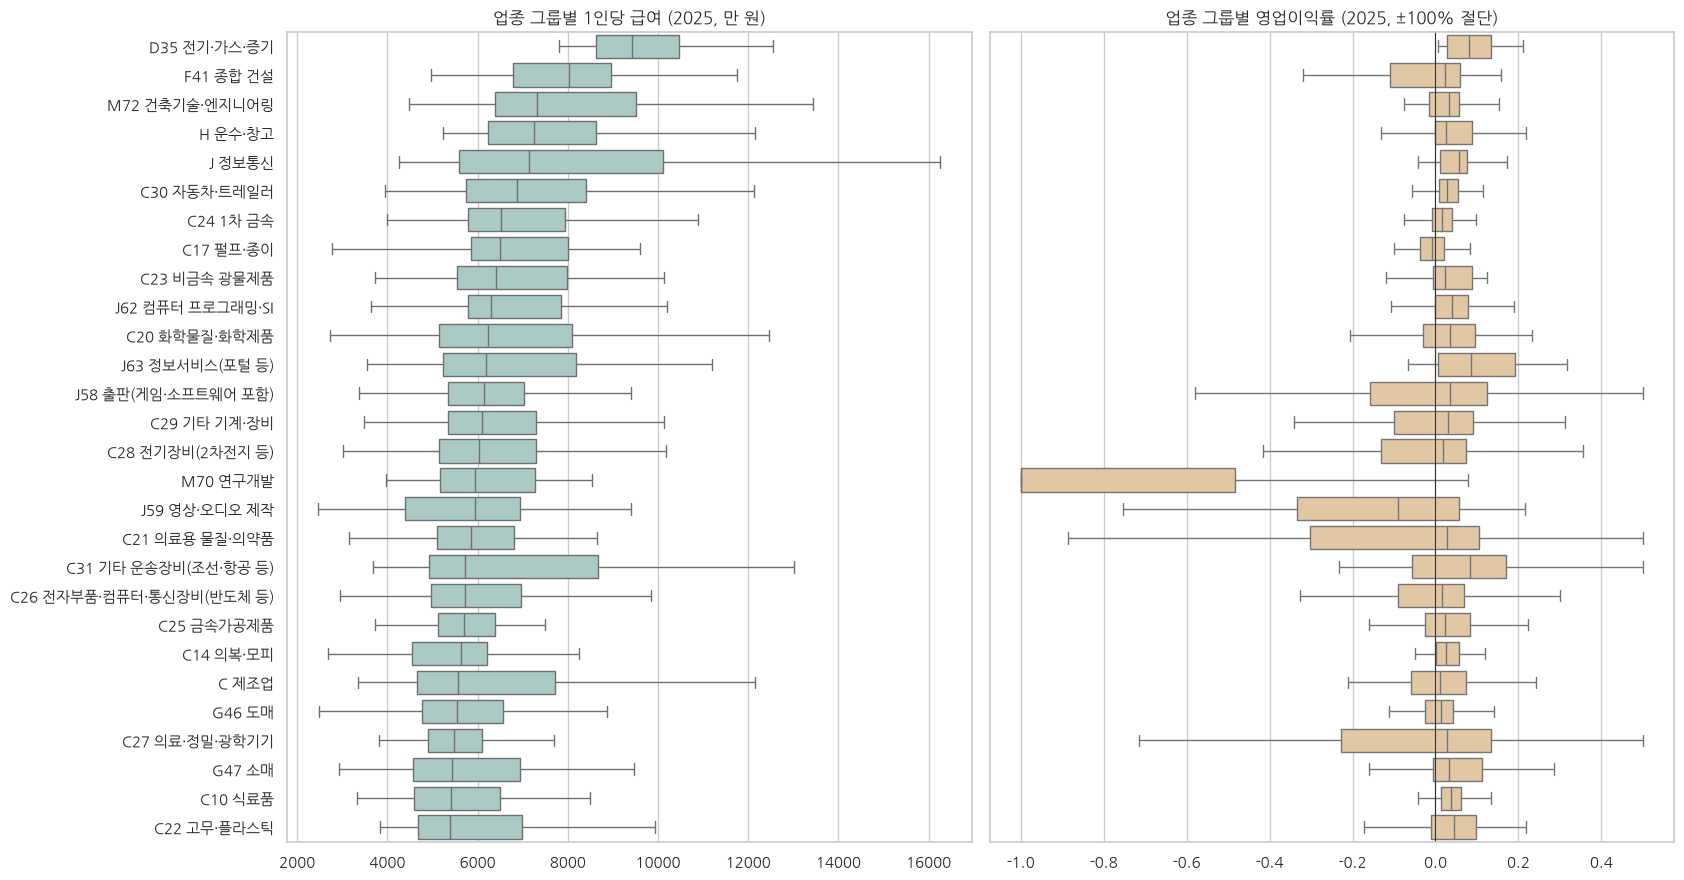

In [44]:
# [H2-③] 그림
order = h2.groupby('업종그룹')['1인당급여'].median().sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(17, max(5.5, 0.32 * len(order))))
sns.boxplot(data=h2, y='업종그룹', x=h2['1인당급여'] / 1e4, order=order, showfliers=False,
            color='#a5cec8', ax=axes[0])
axes[0].set(title=f'업종 그룹별 1인당 급여 ({H_YEAR}, 만 원)', xlabel='', ylabel='')
sns.boxplot(data=h2, y='업종그룹', x=h2['영업이익률'].clip(-1, .5), order=order, showfliers=False,
            color='#ecc89a', ax=axes[1])
axes[1].axvline(0, color='#333', lw=.8)
axes[1].set(title=f'업종 그룹별 영업이익률 ({H_YEAR}, ±100% 절단)', xlabel='', ylabel='')
axes[1].set_yticklabels([])
fig.tight_layout()
save_figure(fig, 'H2_group_box')
plt.show()

**H2 결론**: 업종 간 차이는 있지만 작습니다(1인당 급여 ε² 0.090). 그래서 "업종이 임금을 결정한다"가 아니라 **업종을 맞춰야 할 이유는 있지만 그것만으로는 부족하다**로 말하는 게 정확하고, 이 문장이 **H3로 넘어가는 연결 고리**가 됩니다.

업종을 어떻게 나눌지에 대해서는 결과가 **제조 4군을 버리고 중분류를 쓴 근거**가 됩니다. ① 같은 기업에 적용했을 때 중분류 우선 업종 그룹의 설명력이 가장 크고, ② 4군 사이 차이는 일부 쌍에만 있으며, 4군 모두 안쪽에 1인당 급여가 다른 중분류가 섞여 있었습니다.

### H3. 같은 업종 안에서도 매출과 1인당 자산이 1인당 급여를 설명한다
- **H3-①** 회귀: ln 1인당 급여 = 업종 그룹 + ln 매출 + ln 1인당 자산
- **H3-②** 예측 오차: **산술식 비교군 20곳**(5-2와 같은 규칙: 같은 중분류 먼저 → 같은 대분류에서 채움) vs **업종 기준 중앙값**(5-3과 같은 규칙: 같은 중분류, 11곳 미만이면 같은 대분류). 참고로 옛 규칙(제조 4군 묶음 안 가까운 20곳)의 오차와 같은 중분류 비율도 함께 계산합니다.
- 표본: 2025년, 매출·자산이 있고 **대분류가 21곳 이상**인 기업 (산술식에서 비교군을 만들 수 있는 기업과 같은 조건)

In [45]:
# [H3-①] 회귀: ln 1인당 급여 = 업종 그룹 + ln 매출 + ln 1인당 자산
h3 = hp.loc[hp['사업연도'].eq(H_YEAR) & hp['매출액(원)'].gt(0) & hp['자산총계(원)'].gt(0)
            & hp['영업이익(원)'].notna()].copy()
maj_n = h3['업종_대분류'].value_counts()
h3 = h3.loc[h3['업종_대분류'].map(maj_n).ge(MIN_GROUP)].copy()      # 대분류 21곳 이상 = 산술식 비교 가능 조건
h3['ln_1인당급여'] = np.log(h3['1인당급여'])
h3['ln_매출'] = np.log(h3['매출액(원)'])
h3['ln_1인당자산'] = np.log(h3['자산총계(원)'] / h3['직원수'])
print(f"H3 표본: {len(h3):,}곳 (제외된 대분류: {maj_n[maj_n < MIN_GROUP].to_dict()})")

base = smf.ols('ln_1인당급여 ~ C(업종그룹)', h3).fit(cov_type='HC1')
full = smf.ols('ln_1인당급여 ~ C(업종그룹) + ln_매출 + ln_1인당자산', h3).fit(cov_type='HC1')
wald = full.wald_test('ln_매출 = 0, ln_1인당자산 = 0', scalar=True)
h3_reg = pd.DataFrame({
    '계수': full.params[['ln_매출', 'ln_1인당자산']],
    'p': full.pvalues[['ln_매출', 'ln_1인당자산']],
})
display(h3_reg.round(4))
print(f'R²: 업종만 {base.rsquared:.3f} → +규모 {full.rsquared:.3f} (증분 {full.rsquared - base.rsquared:.3f})')
print(f'Wald 검정 (두 계수 = 0): stat = {float(wald.statistic):.1f}, p = {float(wald.pvalue):.2e}')

H3 표본: 2,405곳 (제외된 대분류: {'R 예술·여가': 13, 'P 교육': 10, 'L 부동산': 10, 'I 숙박·음식': 7, 'A 농림어업': 5, 'E 수도·환경': 4, 'S 기타 서비스': 3})


,계수,p
ln_매출,0.069,0.000
ln_1인당자산,0.092,0.000


R²: 업종만 0.096 → +규모 0.356 (증분 0.260)
Wald 검정 (두 계수 = 0): stat = 223.8, p = 2.58e-49


**결과**: 산술식에서 비교군을 만들 수 있는 조건(대분류 21곳 이상)의 2,405곳을 봤습니다. R²는 업종 그룹만 넣었을 때 **0.096이고, 규모를 더하면 0.356으로 늘어납니다**(증분 0.260). Wald 검정 p = 2.6e-49이고, 두 계수 모두 양수입니다(ln 매출 0.069, ln 1인당 자산 0.092). 같은 업종 안에서도 1인당 급여는 업종보다 규모로 약 2.7배 더 많이 설명됩니다.

In [46]:
# [H3-②] 예측 오차 비교: 산술식 비교군 20곳 vs 업종 기준 중앙값 (+ 참고: 옛 제조 4군 비교군)
def peer_std(X):
    sd = X.std(0)
    sd[sd == 0] = 1
    return (X - X.mean(0)) / sd                                   # 5-2와 같은 표준화(모집단 표준편차)

err_rows = []
for major, g in h3.groupby('업종_대분류'):
    Z = peer_std(g[['ln_매출', 'ln_1인당자산']].to_numpy())          # 대분류 안에서 표준화
    iv, w = g['업종코드_중분류'].to_numpy(), g['1인당급여'].to_numpy()
    n_mid = pd.Series(iv).map(pd.Series(iv).value_counts()).to_numpy()
    for i in range(len(g)):
        d = ((Z - Z[i]) ** 2).sum(axis=1)
        nn = F.select_peers(d, iv, iv[i], exclude=i)                   # 같은 중분류 먼저 → 대분류에서 채움 (formula.py)
        if n_mid[i] >= IND_MED_MIN:                                 # 업종 기준: 같은 중분류(자기 제외)
            same = iv == iv[i]; same[i] = False; ref, unit = np.median(w[same]), '중분류'
        else:                                                       # 11곳 미만이면 같은 대분류(자기 제외)
            ref, unit = np.median(np.delete(w, i)), '대분류'
        err_rows.append({'row': g.index[i], '업종그룹': g['업종그룹'].iat[i], '업종기준단위': unit,
                         '오차_비교군20': abs(w[i] / np.median(w[nn]) - 1),
                         '오차_업종기준': abs(w[i] / ref - 1),
                         '같은중분류_비율': (iv[nn] == iv[i]).mean()})
h3_err = pd.DataFrame(err_rows).set_index('row')

# 참고: 옛 규칙 — 제조 4군 + 대분류 묶음 안에서 가까운 20곳 (중분류 우선 없음)
old_err, old_same = {}, {}
for b, g in h3.groupby('업종묶음_옛'):
    if len(g) < MIN_GROUP:
        continue
    Z = peer_std(g[['ln_매출', 'ln_1인당자산']].to_numpy())
    iv, w = g['업종코드_중분류'].to_numpy(), g['1인당급여'].to_numpy()
    for i in range(len(g)):
        d = ((Z - Z[i]) ** 2).sum(axis=1); d[i] = np.inf
        nn = np.argsort(d)[:PEER_K]
        old_err[g.index[i]] = abs(w[i] / np.median(w[nn]) - 1)
        old_same[g.index[i]] = (iv[nn] == iv[i]).mean()
h3_err['오차_옛비교군'] = pd.Series(old_err)
h3_err['같은중분류_비율_옛'] = pd.Series(old_same)

diff = h3_err['오차_업종기준'] - h3_err['오차_비교군20']
wil = stats.wilcoxon(h3_err['오차_비교군20'], h3_err['오차_업종기준'])
display(pd.Series({'기업 수': len(h3_err),
                   '중앙 오차: 비교군 20곳 (새 규칙)': h3_err['오차_비교군20'].median(),
                   '중앙 오차: 업종 기준 중앙값': h3_err['오차_업종기준'].median(),
                   '비교군이 더 정확한 기업 비율': (diff > 0).mean(),
                   'Wilcoxon p': wil.pvalue,
                   '참고: 중앙 오차 옛 규칙(4군) 비교군': h3_err['오차_옛비교군'].median(),
                   '비교군 중 같은 중분류: 새 규칙': h3_err['같은중분류_비율'].mean(),
                   '비교군 중 같은 중분류: 옛 규칙': h3_err['같은중분류_비율_옛'].mean()}, name='값').to_frame())
display(h3_err['업종기준단위'].value_counts().to_frame('업종 기준 단위'))
display(h3_err.groupby('업종그룹')[['오차_비교군20', '오차_업종기준']].median().round(3))
save_table(h3_err, 'H3_peer_error')
PRIMARY.append(('H3', '산술식 비교군 20곳 vs 업종 기준 중앙값 예측 오차 (Wilcoxon)', wil.pvalue,
                '비교군이 더 정확한 비율', (diff > 0).mean()))

,값
기업 수,"2,405.000"
중앙 오차: 비교군 20곳 (새 규칙),0.140
중앙 오차: 업종 기준 중앙값,0.168
비교군이 더 정확한 기업 비율,0.608
Wilcoxon p,0.000
참고: 중앙 오차 옛 규칙(4군) 비교군,0.137
비교군 중 같은 중분류: 새 규칙,0.964
비교군 중 같은 중분류: 옛 규칙,0.421


,업종 기준 단위
업종기준단위,
중분류,2359
대분류,46


,오차_비교군20,오차_업종기준
업종그룹,,
C 제조업,0.172,0.154
C10 식료품,0.105,0.192
C14 의복·모피,0.181,0.200
C17 펄프·종이,0.156,0.134
C20 화학물질·화학제품,0.146,0.238
C21 의료용 물질·의약품,0.117,0.153
C22 고무·플라스틱,0.118,0.155
C23 비금속 광물제품,0.158,0.216
C24 1차 금속,0.131,0.162


**결과**: 1인당 급여를 맞히는 중앙 오차가 산술식 비교군 20곳 기준 14.0%, 업종 기준 중앙값 16.8%입니다(Wilcoxon p < 0.001). 기업의 60.8%는 비교군 쪽이 더 정확했습니다. 업종 기준 중앙값은 2,359곳이 같은 중분류, 46곳이 같은 대분류로 계산됐습니다.

- 34개 업종 그룹 중 28개에서 비교군이 더 정확하거나 같았습니다. 차이가 큰 곳은 화학물질(14.6% vs 23.8%), 자동차(12.5% vs 20.2%), 식료품(10.5% vs 19.2%)입니다.
- 업종 기준이 조금 더 정확했던 곳은 6개입니다(제조업 소형 중분류 묶음, 펄프·종이, 금속가공, 의료·정밀, 컴퓨터 프로그래밍, 건축기술).

**옛 규칙과 비교**: 옛 제조 4군 비교군의 중앙 오차는 13.7%로 새 규칙(14.0%)보다 0.3%p 작습니다. 대신 비교군 중 같은 중분류 비율이 **42%에서 96%로** 올라갑니다. 산술식 문서(3년 합산, 13.5% → 14.5%, 42% → 96%)와 같은 방향이고, 1년 값으로 계산한 여기서는 정확도 손실이 더 작습니다.

>**H3 결론**: **같은 중분류를 먼저, 모자라면 같은 대분류에서 매출·1인당 자산이 가까운 20곳과 비교한다**는 산술식 1장(2026-11-20 수정판)의 결정을 직접 뒷받침합니다. 비교군 20곳이 업종 기준 중앙값보다 정확하고(14.0% vs 16.8%), 옛 제조 4군 비교군과 비교하면 정확도를 0.3%p만 내주고 비교 상대의 96%를 같은 업종으로 맞춥니다.

### H4. 영업이익은 3년 합산해야 판정이 안정적이다 (K=3)

In [47]:
# [H4-①] 구간별 판정: 3년 합산 판정 vs 끝 연도 1년 판정
def judge_window(start):
    years = list(range(start, start + 3))
    cur = hp.loc[hp['사업연도'].isin(years), ['기업고유코드', '사업연도', '영업이익(원)', '매출액(원)', '이자비용(원)']]
    cur = cur.dropna(subset=['영업이익(원)', '매출액(원)'])
    cur = cur.loc[cur['매출액(원)'].gt(0)]
    full_ids = cur.groupby('기업고유코드')['사업연도'].nunique().loc[lambda s: s.eq(3)].index
    cur = cur.loc[cur['기업고유코드'].isin(full_ids)].sort_values(KEY_COLS)
    # 해마다 '이자 못 냄': 이자비용 > 0이면 OP/INT < 1, 이자비용이 없으면 영업적자
    has_int = cur['이자비용(원)'].gt(0)
    cur['못냄'] = np.where(has_int, cur['영업이익(원)'] / cur['이자비용(원)'].where(has_int) < 1,
                         cur['영업이익(원)'] < 0)
    g = cur.groupby('기업고유코드')
    last = cur.loc[cur['사업연도'].eq(years[-1])].set_index('기업고유코드')
    return pd.DataFrame({
        'm3': g['영업이익(원)'].sum() / g['매출액(원)'].sum(),
        '제약3': (g['영업이익(원)'].sum() < 0) | g['못냄'].all(),
        'm1': last['영업이익(원)'] / last['매출액(원)'],
        '제약1': last['못냄'].astype(bool),
    })

def pair_label(start):
    return f'{start}~{(start + 2) % 100:02d} → {start + 3}~{(start + 5) % 100:02d}'

H4_STARTS = range(YEAR_MIN, YEAR_MAX - 4)     # 2015~2020 시작 → 겹치지 않는 구간 쌍 6개
MAIN_START = YEAR_MAX - 5                      # 주분석: 2020~22 → 2023~25

In [48]:
# [H4-②] 대표 검정 — 안정성: 다음 3년 구간에서도 같은 판정·순위가 유지되는가
def stability(start):
    j = judge_window(start).join(judge_window(start + 3), rsuffix='_다음', how='inner')
    keep3 = (j['제약3'] == j['제약3_다음']).values
    keep1 = (j['제약1'] == j['제약1_다음']).values
    table = [[np.sum(keep3 & keep1), np.sum(keep3 & ~keep1)], [np.sum(~keep3 & keep1), np.sum(~keep3 & ~keep1)]]
    return j, keep3, keep1, mcnemar(table, exact=False, correction=True).pvalue

stab_rows = []
for start in H4_STARTS:
    j, keep3, keep1, p = stability(start)
    stab_rows.append({'구간 쌍': pair_label(start), '기업': len(j),
                      '판정 유지_3년': keep3.mean(), '판정 유지_1년': keep1.mean(), 'McNemar_p': p,
                      'ρ 영업이익률_3년': stats.spearmanr(j['m3'], j['m3_다음'])[0],
                      'ρ 영업이익률_1년': stats.spearmanr(j['m1'], j['m1_다음'])[0]})
h4_stab = pd.DataFrame(stab_rows).set_index('구간 쌍')
display(h4_stab.round(4))
save_table(h4_stab, 'H4_stability')

# 주분석: 순위상관 차이의 부트스트랩 95% CI
j, keep3, keep1, p_main = stability(MAIN_START)
ids = np.arange(len(j))
boot = []
for _ in range(N_BOOT):
    b = j.iloc[rng.choice(ids, len(ids))]
    boot.append(stats.spearmanr(b['m3'], b['m3_다음'])[0] - stats.spearmanr(b['m1'], b['m1_다음'])[0])
print(f'주분석 {pair_label(MAIN_START)}: 판정 유지 3년 {keep3.mean():.1%} vs 1년 {keep1.mean():.1%} '
      f'(McNemar p = {p_main:.2e}) | 순위상관 차이(3년−1년) 95% CI '
      f'[{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]')
PRIMARY.append(('H4', '3년 합산 vs 1년 판정 유지 (McNemar)', p_main,
                '판정 유지율 차이', keep3.mean() - keep1.mean()))

,기업,판정 유지_3년,판정 유지_1년,McNemar_p,ρ 영업이익률_3년,ρ 영업이익률_1년
구간 쌍,,,,,,
2015~17 → 2018~20,1053,0.774,0.712,0.000,0.649,0.504
2016~18 → 2019~21,1139,0.787,0.729,0.000,0.654,0.521
2017~19 → 2020~22,1243,0.786,0.731,0.000,0.636,0.493
2018~20 → 2021~23,1369,0.785,0.685,0.000,0.646,0.461
2019~21 → 2022~24,1479,0.775,0.703,0.000,0.640,0.509
2020~22 → 2023~25,1589,0.770,0.726,0.000,0.624,0.549


주분석 2020~22 → 2023~25: 판정 유지 3년 77.0% vs 1년 72.6% (McNemar p = 2.62e-04) | 순위상관 차이(3년−1년) 95% CI [0.038, 0.109]


결과: 겹치지 않는 구간 쌍 6개 **모두에서** 3년 합산이 더 안정적입니다.

| 지표 | 3년 합산 | 끝 연도 1년 |
|---|---:|---:|
| 지급 여력 제약 판정 유지율 | 77~79% | 69~73% |
| 영업이익률 순위상관 | 0.62~0.65 | 0.46~0.55 |

McNemar p는 6쌍 모두 0.001 이하입니다. 주분석(2020-22 → 2023-25)에서 순위상관 차이의 95% 신뢰구간은 0.038~0.109로, 0을 포함하지 않습니다.

In [49]:
# [H4-③] 보조 검정 — 예고력: 다음 3년 합산 적자를 얼마나 맞히나
def window_table(start):
    out = judge_window(start)
    nxt = list(range(start + 3, start + 6))
    fut = hp.loc[hp['사업연도'].isin(nxt)].dropna(subset=['영업이익(원)'])
    fut_n = fut.groupby('기업고유코드')['사업연도'].nunique()
    fut_op = fut.groupby('기업고유코드')['영업이익(원)'].sum()
    out['이후적자'] = (fut_op.loc[fut_n.eq(3)] < 0)
    out = out.dropna(subset=['이후적자'])
    out['이후적자'] = out['이후적자'].astype(bool)
    out['구간'] = pair_label(start)
    return out

def h4_compare(t):
    y = t['이후적자'].values
    hit3, hit1 = (t['제약3'].values == y), (t['제약1'].values == y)
    table = [[np.sum(hit3 & hit1), np.sum(hit3 & ~hit1)], [np.sum(~hit3 & hit1), np.sum(~hit3 & ~hit1)]]
    return {'기업': len(t), '이후적자 비율': y.mean(),
            '적중률_3년': hit3.mean(), '적중률_1년': hit1.mean(),
            '제약→이후적자_3년': y[t['제약3'].values].mean(), '제약→이후적자_1년': y[t['제약1'].values].mean(),
            'McNemar_p': mcnemar(table, exact=False, correction=True).pvalue,
            'AUC_3년': roc_auc_score(y, -t['m3']), 'AUC_1년': roc_auc_score(y, -t['m1'])}

h4_all = pd.concat([window_table(s) for s in H4_STARTS])
h4_pairs = pd.DataFrame({k: h4_compare(g) for k, g in h4_all.groupby('구간')}).T.astype(float)
display(h4_pairs.round(3))
save_table(h4_pairs, 'H4_prediction')

,기업,이후적자 비율,적중률_3년,적중률_1년,제약→이후적자_3년,제약→이후적자_1년,McNemar_p,AUC_3년,AUC_1년
2015~17 → 2018~20,"1,062.000",0.278,0.784,0.786,0.638,0.616,0.934,0.794,0.809
2016~18 → 2019~21,"1,146.000",0.279,0.787,0.768,0.630,0.573,0.124,0.791,0.805
2017~19 → 2020~22,"1,248.000",0.271,0.784,0.764,0.608,0.559,0.079,0.783,0.770
2018~20 → 2021~23,"1,376.000",0.274,0.783,0.748,0.599,0.532,0.002,0.797,0.783
2019~21 → 2022~24,"1,484.000",0.299,0.780,0.772,0.640,0.622,0.434,0.790,0.796
2020~22 → 2023~25,"1,596.000",0.322,0.771,0.762,0.661,0.641,0.363,0.781,0.784


**결과**: AUC는 3년 합산 0.78-0.80, 1년 0.77-0.81로 차이가 없습니다. McNemar(맥니마 검정)는 6쌍 중 1쌍만 유의합니다. 다만 "제약 판정 → 이후 적자" 적중 비율은 3년 합산이 6쌍 모두에서 2~7%p 높습니다.

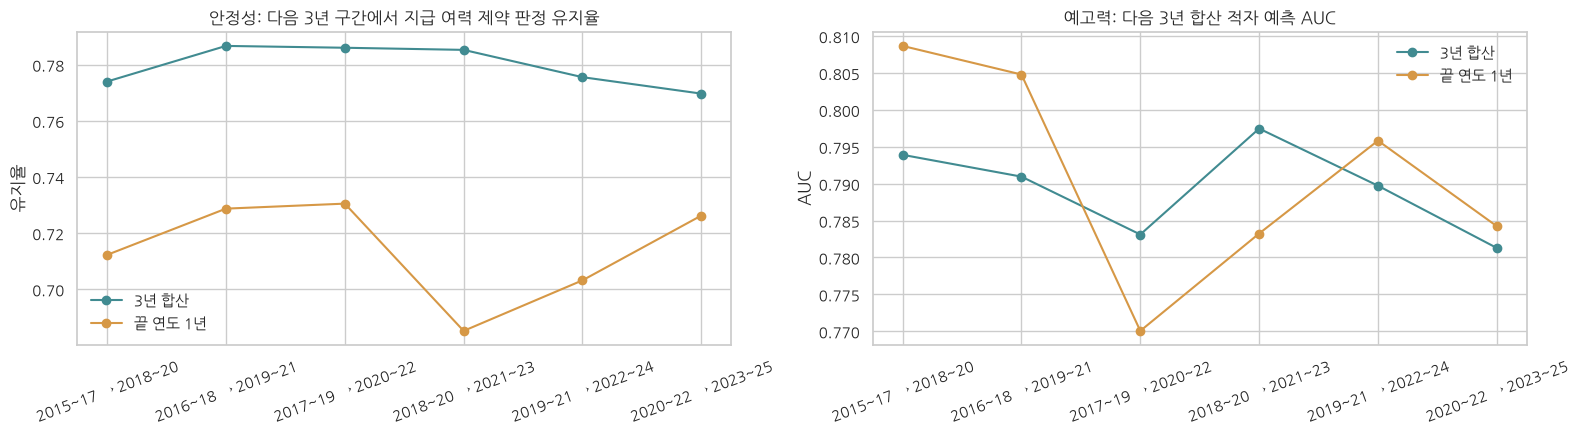

In [50]:
# [H4-④] 그림: 안정성(왼쪽)과 예고력(오른쪽)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
x = np.arange(len(h4_stab))
axes[0].plot(x, h4_stab['판정 유지_3년'], marker='o', color=MAIN_COLOR, label='3년 합산')
axes[0].plot(x, h4_stab['판정 유지_1년'], marker='o', color=SUB_COLOR, label='끝 연도 1년')
axes[0].set_xticks(x, h4_stab.index, rotation=20)
axes[0].set(title='안정성: 다음 3년 구간에서 지급 여력 제약 판정 유지율', ylabel='유지율')
axes[0].legend(frameon=False)
axes[1].plot(x, h4_pairs['AUC_3년'], marker='o', color=MAIN_COLOR, label='3년 합산')
axes[1].plot(x, h4_pairs['AUC_1년'], marker='o', color=SUB_COLOR, label='끝 연도 1년')
axes[1].set_xticks(x, h4_pairs.index, rotation=20)
axes[1].set(title='예고력: 다음 3년 합산 적자 예측 AUC', ylabel='AUC')
axes[1].legend(frameon=False)
fig.tight_layout()
save_figure(fig, 'H4_stability_prediction')
plt.show()

> H4 결론: K=3을 고른 근거는 "더 잘 맞힌다"가 아니라 **판정이 덜 흔들린다**입니다. 노트북 1-11에 있는 문장(“K=3 합산이 가장 필요한 컬럼이 영업이익”)도 이 표현으로 맞춰 두면 일관됩니다.

### H5. 같은 "급여 5% 인상"이라도 회사에 미치는 무게가 다르다

In [51]:
# [H5-①] 부담 지표 만들기
h5 = hp.loc[hp['사업연도'].eq(H_YEAR) & hp['영업이익(원)'].gt(0) & hp['업종그룹'].isin(GROUPS)].copy()
h5['비용_영업이익(%)'] = RAISE * (1 + OVERHEAD) * h5['급여총액(원)'] / h5['영업이익(원)'] * 100
h5['규모'] = pd.cut(h5['직원수'], [0, 299, 999, np.inf], labels=['299명 이하', '300~999명', '1,000명 이상'])

hist = hp.loc[hp['사업연도'].le(H_YEAR)].dropna(subset=['영업이익(원)'])
hist_g = hist.groupby('기업고유코드')
alpha = pd.DataFrame({'연수': hist_g['사업연도'].nunique(),
                      'S합': hist_g['급여총액(원)'].sum(),
                      '흑자OP합': hist_g['영업이익(원)'].apply(lambda s: s.clip(lower=0).sum())})
alpha = alpha.loc[alpha['연수'].ge(5) & alpha['흑자OP합'].gt(0)]
alpha['α(%)'] = RAISE * alpha['S합'] / alpha['흑자OP합'] * 100
h5 = h5.merge(alpha[['α(%)']], left_on='기업고유코드', right_index=True, how='left')
print(f'비용÷영업이익 계산 기업 {len(h5):,}곳, α 계산 기업 {h5["α(%)"].notna().sum():,}곳')

비용÷영업이익 계산 기업 1,500곳, α 계산 기업 1,238곳


In [52]:
# [H5-②] 업종 그룹·규모별 차이 (Kruskal + ε²) + 분포 폭
h5_rows = []
for col in ['비용_영업이익(%)', 'α(%)']:
    for grp in ['업종그룹', '규모']:
        d = h5.dropna(subset=[col])
        h, p, eps = kruskal_eps([g[col] for _, g in d.groupby(grp, observed=True)])
        h5_rows.append({'지표': col, '집단': grp, 'H': h, 'p': p, 'ε²': eps})
h5_table = pd.DataFrame(h5_rows).set_index(['지표', '집단'])
display(h5_table)

spread = h5.groupby('업종그룹').agg(
    기업=('비용_영업이익(%)', 'size'),
    비용영업이익_중앙=('비용_영업이익(%)', 'median'),
    비용영업이익_Q1=('비용_영업이익(%)', lambda s: s.quantile(.25)),
    비용영업이익_Q3=('비용_영업이익(%)', lambda s: s.quantile(.75)),
    영업이익의_20퍼센트_초과=('비용_영업이익(%)', lambda s: s.gt(20).mean()),
    α_중앙=('α(%)', 'median'),
).sort_values('비용영업이익_중앙')
display(spread.round(2))
save_table(spread, 'H5_burden_by_group')
print('전체: 비용÷영업이익 중앙 {:.1f}%, 사분위 {:.1f}~{:.1f}% | α 중앙 {:.1f}%'.format(
    h5['비용_영업이익(%)'].median(), *h5['비용_영업이익(%)'].quantile([.25, .75]), h5['α(%)'].median()))
PRIMARY.append(('H5', '업종 그룹 → 비용÷영업이익 (Kruskal)', h5_table.loc[('비용_영업이익(%)', '업종그룹'), 'p'],
                'ε²', h5_table.loc[('비용_영업이익(%)', '업종그룹'), 'ε²']))

H     p     ε²
지표         집단                       
비용_영업이익(%) 업종그룹 102.158 0.000  0.051
           규모     2.772 0.250  0.001
α(%)       업종그룹 114.340 0.000  0.072
           규모     0.984 0.611 -0.001

,기업,비용영업이익_중앙,비용영업이익_Q1,비용영업이익_Q3,영업이익의_20퍼센트_초과,α_중앙
업종그룹,,,,,,
D35 전기·가스·증기,26,1.450,0.450,4.650,0.040,4.870
C31 기타 운송장비(조선·항공 등),23,3.770,2.060,9.410,0.090,9.080
J59 영상·오디오 제작,16,6.190,2.440,15.210,0.250,4.700
F41 종합 건설,29,6.280,4.710,13.160,0.070,7.770
C14 의복·모피,24,6.400,3.780,20.790,0.290,4.730
G46 도매,79,6.550,2.760,16.220,0.230,7.380
J 정보통신,22,6.870,4.950,24.040,0.270,5.950
C20 화학물질·화학제품,111,6.910,4.380,13.770,0.180,5.740
G47 소매,33,6.920,4.600,16.590,0.180,6.110


전체: 비용÷영업이익 중앙 9.1%, 사분위 4.5~20.7% | α 중앙 8.2%


In [53]:
# [H5-②-b] 점검: 업종 그룹 차이가 전기·가스 한 그룹 때문인가
is_gas = h5['업종그룹'].str.startswith('D')                       # 대분류 D (전기·가스)
chk_rows = []
for name, d in [('전체', h5), ('전기·가스 제외', h5[~is_gas])]:
    d = d.dropna(subset=['비용_영업이익(%)'])
    h, p, eps = kruskal_eps([g['비용_영업이익(%)'] for _, g in d.groupby('업종그룹')])
    chk_rows.append({'표본': name, '기업': len(d), '그룹 수': d['업종그룹'].nunique(), 'H': h, 'p': p, 'ε²': eps})
display(pd.DataFrame(chk_rows).set_index('표본').round(4))
iqr = (spread['비용영업이익_Q3'] - spread['비용영업이익_Q1'])
iqr = iqr[~iqr.index.str.startswith('D')]
print(f"전기·가스 제외 그룹 안 사분위 폭: {iqr.min():.1f}-{iqr.max():.1f}%p")

,기업,그룹 수,H,p,ε²
표본,,,,,
전체,1500,28,102.158,0.000,0.051
전기·가스 제외,1474,27,65.148,0.000,0.027


전기·가스 제외 그룹 안 사분위 폭: 7.4-86.9%p


**결과**: 21곳 이상 업종 그룹에 속한 2025년 흑자 기업 1,500곳을 봤습니다.

- **비용 ÷ 영업이익**: 중앙값 9.1%, 사분위 범위 **4.5-20.7%**입니다. 4곳 중 1곳은 급여 5% 인상이 영업이익의 20.7% 이상을 가져갑니다.
- **α**: 중앙값 8.2%(1,238곳)입니다. 여기 α는 5-6과 같은 **발표 슬라이드 정의 Σmax(관측 영업이익, 0)**입니다. 5-6(10.2%)과 다른 것은 표본(여기는 2025년 흑자 기업)과 기간 차이 때문입니다.
- **업종 그룹 간 차이**: p < 0.001이지만 **ε² = 0.051**, 즉 업종 그룹이 설명하는 부분은 5% 정도입니다. 직원 규모 구간 간 차이는 유의하지 않습니다(p = 0.25).
- **전기·가스 한 그룹 때문만은 아닙니다**: 전기·가스·증기(26곳, 중앙 1.5%)를 빼도 p < 0.001, ε² = 0.027로 유의합니다. 다만 효과 크기는 절반으로 줄어듭니다.
- **업종 안 차이가 더 큽니다**: 50곳 이상인 업종 그룹 11개만 보면, 업종별 중앙값은 6.6-13.3%로 약 7%p 범위 안에 있습니다. 반면 **업종 안 사분위 폭은 9.4-25.0%p**입니다. 코드가 출력한 사분위 폭 7.4-86.9%p에는 기업이 8-15곳뿐인 작은 그룹(펄프·종이, 건축기술 등)이 들어 있어서, 큰 그룹 기준으로 보고합니다.

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


... (4 outputs left out)

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


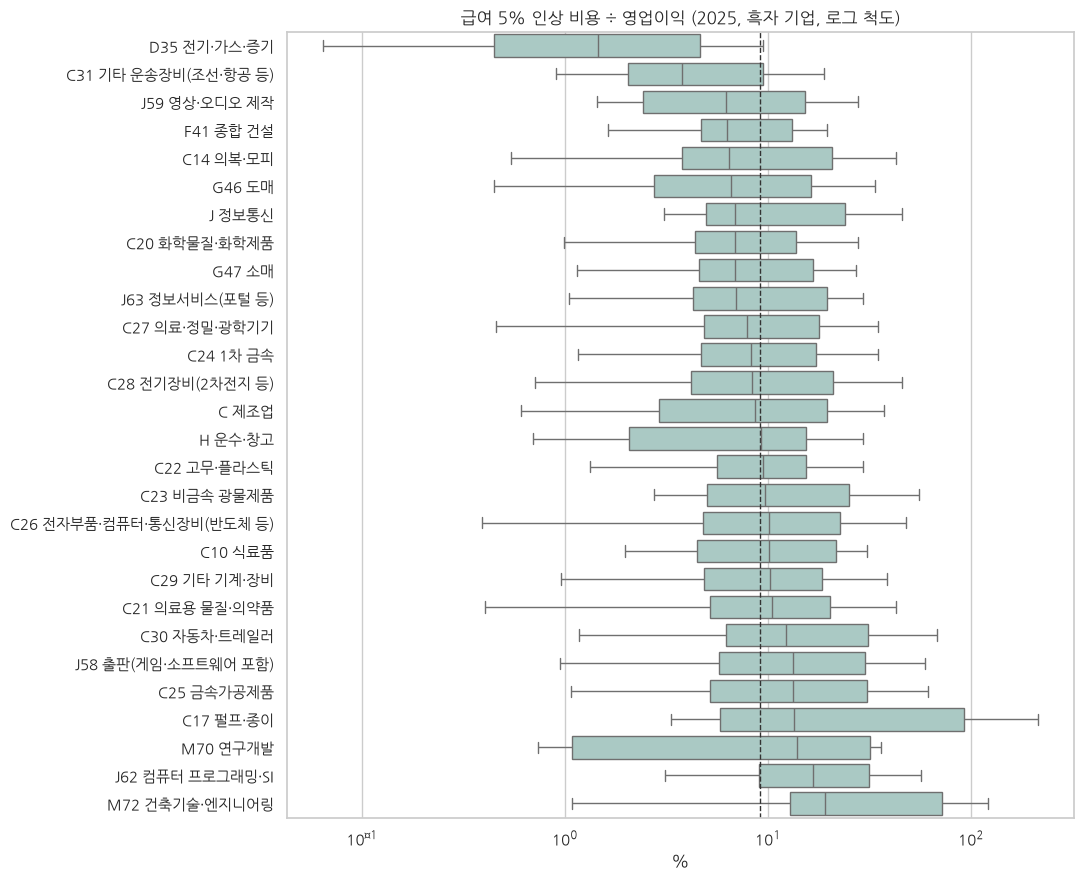

In [54]:
# [H5-③] 그림
fig, ax = plt.subplots(figsize=(11, max(5, 0.32 * len(spread))))
sns.boxplot(data=h5, y='업종그룹', x='비용_영업이익(%)', order=spread.index, showfliers=False,
            color='#a5cec8', ax=ax)
ax.set_xscale('log')
ax.axvline(h5['비용_영업이익(%)'].median(), color='#333', ls='--', lw=1)
ax.set(title=f'급여 5% 인상 비용 ÷ 영업이익 ({H_YEAR}, 흑자 기업, 로그 척도)', xlabel='%', ylabel='')
fig.tight_layout()
save_figure(fig, 'H5_burden_box')
plt.show()

> **H5 결론**: 처음 설계는 "업종마다 무게가 다르다"였습니다. 업종 간 차이는 통계적으로 있지만 작고(ε² 0.051, 전기·가스를 빼면 0.027), **같은 업종 안 회사 사이의 차이가 훨씬 큽니다.** 이 결과가 오히려 문제정의에 더 잘 맞습니다. "하이닉스가 10%니까 우리도"라는 업종 평균 비교는 통하지 않으니 **회사별로 계산**해야 한다는 근거가 되고, 산술식 2-5 비용 계산을 중심 결과로 둔 이유가 됩니다. 발표에서는 업종 간 p값 대신 "업종 안 사분위 폭"을 보여 주세요.

### H6. 성과급이나 임금을 더 주면 이익이 오르는가

산술식 문서는 "성과급을 올리면 이익이 오른다고 예측하지 않는다"고 정했습니다. H6은 그 결정의 근거를 데이터로 확인합니다. 방향이 반대인 두 질문으로 나눕니다.

| | 질문 | 방향 | 방법 |
|---|---|---|---|
| **H6-①** 성과 공유 | 이익이 늘면 급여도 늘어나는가 | 이익 → 급여 | 기업 고정효과 + 업종 그룹×연도 고정효과 회귀, 직원 규모별 기울기 |
| **H6-②** 이익 회수 | 급여를 더 올린 회사는 이후 이익이 나아지는가 | 급여 → 이익 | Δ영업이익률 회귀 + **동등성 검정(TOST)** |

**H6-②에서 TOST를 쓰는 이유.** "유의하지 않다"는 "못 찾았다"일 수도 있습니다. 그래서 효과가 있다면 최대 얼마인지 90% 신뢰구간으로 묶고, 그 크기가 **미리 정한 경계(±0.6%p)** 안에 있는지 확인합니다.
- 경계 근거: 1인당 급여 증가율을 10%p 더 올리는 비용은 영업이익률 약 1.2~1.4%p입니다(산술식 5% 인상 비용 0.59%p의 약 2배, 아래 셀에서 데이터로 다시 계산하면 1.40%p). 그 **절반(±0.6%p)도 회수하지 못하면** "이익을 올리려고 인상한다"는 논리는 성립하지 않습니다.

**표본:** 4-1 가설검정 표본(`hp` = 산술식 분석 자격 2,840곳), 2015~2025년. 관찰 자료의 관계이므로 인과 효과를 증명하지는 않습니다.

In [55]:
# [H6-0] 공통: 연속 연도 패널과 고정효과 흡수 함수
import statsmodels.api as sm
H6_SIZE_BINS = [0, 299, 999, np.inf]
H6_SIZE_LABELS = ['~299명', '300~999명', '1,000명~']
H6_BOUND = 0.6          # H6-② 동등성 경계(%p, 급여 증가율 10%p당) — 미리 정함

h6 = hp[['기업고유코드', '사업연도', '업종그룹', '직원수', '급여총액(원)', '영업이익(원)', '매출액(원)']].copy()
h6 = h6.sort_values(KEY_COLS).reset_index(drop=True)
h6['w'] = h6['급여총액(원)'] / h6['직원수']                      # 1인당 급여(원)
h6['pi'] = h6['영업이익(원)'] / h6['직원수']                     # 1인당 영업이익(원)
h6['margin'] = (h6['영업이익(원)'] / h6['매출액(원)'] * 100).where(h6['매출액(원)'].gt(0))   # 영업이익률(%)
h6['규모'] = pd.cut(h6['직원수'], H6_SIZE_BINS, labels=H6_SIZE_LABELS).astype(str)
h6['업종연도'] = h6['업종그룹'] + '_' + h6['사업연도'].astype(str)

g6 = h6.groupby('기업고유코드')
consec = g6['사업연도'].diff().eq(1)                              # 바로 전 해가 있는 행
for col in ['w', 'pi', 'margin', '직원수']:
    h6[f'{col}_lag'] = g6[col].shift().where(consec)

def absorb(frame, cols, fe_cols, tol=1e-8, max_iter=200):
    # 여러 고정효과를 번갈아 빼서 흡수 (alternating projections)
    out = frame[cols].astype(float).copy()
    for _ in range(max_iter):
        prev = out.copy()
        for fe in fe_cols:
            out = out - out.groupby(frame[fe]).transform('mean')
        if (out - prev).abs().to_numpy().max() < tol:
            break
    return out

def winsor(s, lo=.01, hi=.99):
    a, b = s.quantile([lo, hi])
    return s.clip(a, b)
print(f"H6 패널: {len(h6):,}행 · {h6['기업고유코드'].nunique():,}곳 · 바로 전 해가 있는 행 {consec.sum():,}")

H6 패널: 21,761행 · 2,840곳 · 바로 전 해가 있는 행 18,271


#### H6-① 이익이 늘면 급여도 늘어나는가 (성과 공유도)
```
1인당 급여_it = Σ_규모 β_규모 × (1인당 영업이익_it × 1[규모]) + 기업 고정효과 + 업종 그룹×연도 고정효과
```
- **β_규모:** 같은 기업 안에서, 같은 업종·연도 평균을 뺀 뒤 1인당 영업이익이 1원 늘 때 1인당 급여가 몇 원 늘어나는가
- **주 검정:** 1,000명 이상의 추가분 β(1,000명~) − β(~299명) = 0 (기업 클러스터 표준오차, Wald 검정)
- **보조 검정(하방 경직성):** 전년 대비 변화로 Δ급여 = β⁺·Δ이익⁺ + β⁻·Δ이익⁻ + 업종 그룹×연도 고정효과. "급여는 오르기만 하고 내려가지 않는다"면 β⁺ > β⁻
- 1인당 급여·영업이익은 위아래 1%를 잘라 극단값 영향을 줄입니다.

,기울기(원/원),95% 하한,95% 상한,p,관측,"1인당 이익 1,000만 원↑ → 급여(만 원)"
~299명,0.005,0.001,0.008,0.011,14166,4.705
300~999명,0.024,0.016,0.033,0.000,5313,24.349
"1,000명~",0.030,0.021,0.040,0.000,2282,30.360


관측 21,761개 · 2,840곳 / 주 검정 β(1,000명~) − β(~299명) = 0.0257원/원, p = 3.57e-07
하방 경직성: 이익이 늘 때 β⁺ = 0.0071, 줄 때 β⁻ = 0.0039, 같은가 p = 0.18 (관측 18,271개)


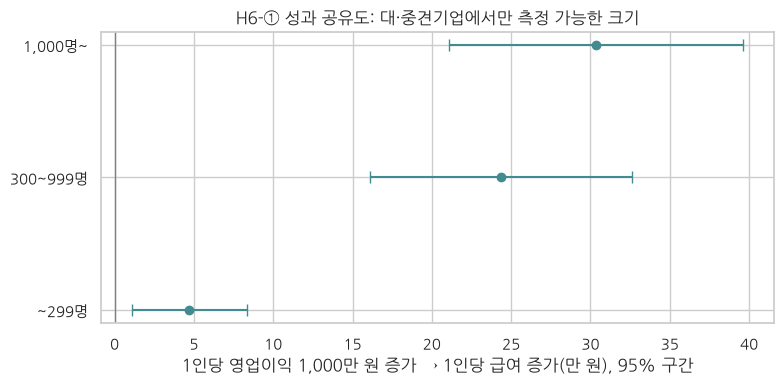

In [56]:
# [H6-①] 성과 공유도: 직원 규모별 기울기
d1 = h6.dropna(subset=['w', 'pi']).copy()
d1['w'], d1['pi'] = winsor(d1['w']), winsor(d1['pi'])
for lab in H6_SIZE_LABELS:
    d1[f'pi×{lab}'] = d1['pi'] * d1['규모'].eq(lab)
    d1[f'size_{lab}'] = d1['규모'].eq(lab).astype(float)
X_COLS = [f'pi×{lab}' for lab in H6_SIZE_LABELS] + [f'size_{lab}' for lab in H6_SIZE_LABELS[1:]]
dm = absorb(d1, ['w'] + X_COLS, ['기업고유코드', '업종연도'])
fit1 = sm.OLS(dm['w'], dm[X_COLS]).fit(cov_type='cluster', cov_kwds={'groups': d1['기업고유코드']})
pass_tab = pd.DataFrame({'기울기(원/원)': fit1.params[X_COLS[:3]].to_numpy(),
                         '95% 하한': fit1.conf_int().loc[X_COLS[:3], 0].to_numpy(),
                         '95% 상한': fit1.conf_int().loc[X_COLS[:3], 1].to_numpy(),
                         'p': fit1.pvalues[X_COLS[:3]].to_numpy(),
                         '관측': [int(d1['규모'].eq(l).sum()) for l in H6_SIZE_LABELS]}, index=H6_SIZE_LABELS)
pass_tab['1인당 이익 1,000만 원↑ → 급여(만 원)'] = pass_tab['기울기(원/원)'] * 1000
display(pass_tab.round(4))
R = np.zeros(len(X_COLS)); R[X_COLS.index('pi×1,000명~')], R[X_COLS.index('pi×~299명')] = 1, -1
wald = fit1.t_test(R)
p_h6a = float(wald.pvalue)
diff_h6a = float(np.squeeze(wald.effect))
print(f"관측 {len(d1):,}개 · {d1['기업고유코드'].nunique():,}곳 / 주 검정 β(1,000명~) − β(~299명) = {diff_h6a:.4f}원/원, p = {p_h6a:.3g}")

# 보조: 하방 경직성 (전년 대비 변화, 바로 전 해가 있는 행만)
d2 = h6.dropna(subset=['w', 'pi', 'w_lag', 'pi_lag']).copy()
d2['dw'] = winsor(d2['w'] - d2['w_lag']); d2['dpi'] = winsor(d2['pi'] - d2['pi_lag'])
d2['dpi_up'], d2['dpi_down'] = d2['dpi'].clip(lower=0), d2['dpi'].clip(upper=0)
dm2 = absorb(d2, ['dw', 'dpi_up', 'dpi_down'], ['업종연도'])
fit2 = sm.OLS(dm2['dw'], dm2[['dpi_up', 'dpi_down']]).fit(cov_type='cluster', cov_kwds={'groups': d2['기업고유코드']})
p_asym = float(fit2.t_test(np.array([1., -1.])).pvalue)
print(f"하방 경직성: 이익이 늘 때 β⁺ = {fit2.params['dpi_up']:.4f}, 줄 때 β⁻ = {fit2.params['dpi_down']:.4f}, 같은가 p = {p_asym:.2f} "
      f"(관측 {len(d2):,}개)")

fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(pass_tab))
ax.errorbar(pass_tab['1인당 이익 1,000만 원↑ → 급여(만 원)'], y,
            xerr=[(pass_tab['기울기(원/원)'] - pass_tab['95% 하한']) * 1000, (pass_tab['95% 상한'] - pass_tab['기울기(원/원)']) * 1000],
            fmt='o', color=MAIN_COLOR, capsize=4)
ax.axvline(0, color='grey', lw=1)
ax.set(yticks=y, yticklabels=pass_tab.index, xlabel='1인당 영업이익 1,000만 원 증가 → 1인당 급여 증가(만 원), 95% 구간',
       title='H6-① 성과 공유도: 대·중견기업에서만 측정 가능한 크기')
plt.tight_layout(); save_figure(fig, 'H6_1_passthrough'); plt.show()
PRIMARY.append(('H6', '① 성과 공유 β(1,000명~)−β(~299명), FE·클러스터', p_h6a, '추가 기울기(원/원)', diff_h6a))

**결과**: 관측 21,761개(2,840곳). 같은 기업 안에서 1인당 영업이익이 1,000만 원 늘 때 1인당 급여는 **299명 이하 약 5만 원, 300-999명 약 24만 원, 1,000명 이상 약 30만 원** 늘었습니다(원/원 기울기 0.005 · 0.024 · 0.030). 주 검정인 1,000명 이상의 추가분(0.026원/원)은 p < 0.001로 유의합니다. 하방 경직성 보조 검정에서는 이익이 늘 때(0.007)와 줄 때(0.004) 따라가는 정도가 통계적으로 다르지 않았습니다(p = 0.18). 고정효과를 업종 그룹 × 연도로 바꿔도 결과는 거의 같습니다.
- 해석: 이익이 급여로 돌아오는 정도는 **대·중견기업에서만 측정 가능한 크기**이고, 그마저 이익 1원당 약 0.03원(3%)입니다. "급여는 오르기만 한다"는 하방 경직성은 보이지 않습니다.
- 팀원 분석(관측 18,379개·2,714곳)과 비교: 규모별 순서와 결론은 같습니다. 299명 이하 기울기는 팀원 0.001(유의하지 않음), 여기 0.005(p = 0.011)로 둘 다 매우 작습니다. 남은 차이는 극단값 처리(여기는 상하 1% 자르기)와 연속 연도 조건 차이로 보이며, 팀원 코드로 확인하지는 않았습니다.

#### H6-② 급여를 더 올린 회사는 이후 이익이 나아지는가 (동등성 검정)
```
Δ영업이익률(t → t+h, %p) = β × 1인당 급여 증가율(t−1 → t, 10%p 단위)
                          + 영업이익률_t + 직원수 증가율_t + 직전 해 급여 증가율 + 업종 그룹×연도 고정효과
```
- h = 1, 2, 3년. **주 검정은 h = 1**, 기업 클러스터 표준오차
- 급여 증가율 ±50%, 영업이익률 ±100%를 넘는 값은 제외 (단위 오류·특수 사례)
- **TOST:** H₀₁: β ≤ −0.6, H₀₂: β ≥ +0.6을 둘 다 기각하면(= 90% 구간이 ±0.6 안) "효과가 있어도 경계보다 작다"

급여 증가율 10%p의 비용(영업이익률 하락) 중앙값: 1.40%p → 경계는 그 절반 수준인 ±0.6%p로 미리 고정


,관측,기업,"효과(%p, 급여 10%p당)",90% 하한,90% 상한,일반 검정 p(β=0),TOST p
기간,,,,,,,
1년 뒤,11288,2079,0.104,-0.122,0.330,0.448,0.000
2년 뒤,9203,1913,0.044,-0.232,0.320,0.794,0.000
3년 뒤,7384,1750,0.189,-0.179,0.557,0.399,0.033


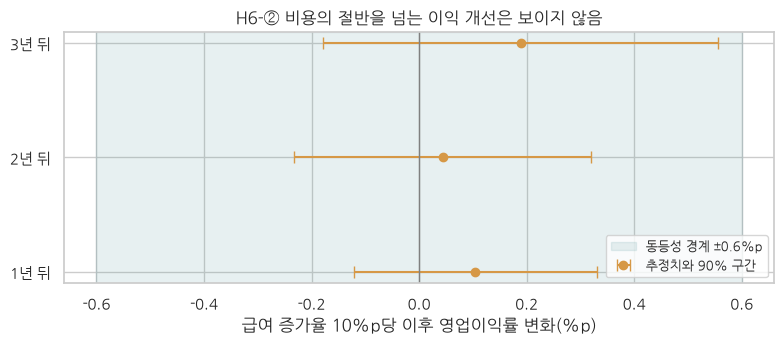

In [57]:
# [H6-②] 급여 증가 → 이후 영업이익률 변화, TOST
# 경계 근거: 급여 증가율 10%p를 더 주는 비용 = 0.10 × (1 + c) × 급여 ÷ 매출 (영업이익률 %p)
cost10 = (0.10 * (1 + OVERHEAD) * h6['급여총액(원)'] / h6['매출액(원)'] * 100).where(h6['매출액(원)'].gt(0))
print(f"급여 증가율 10%p의 비용(영업이익률 하락) 중앙값: {cost10[h6['사업연도'].eq(H_YEAR)].median():.2f}%p → 경계는 그 절반 수준인 ±{H6_BOUND}%p로 미리 고정")

h6['wg'] = (h6['w'] / h6['w_lag'] - 1)                 # 1인당 급여 증가율
h6['wg_lag'] = h6.groupby('기업고유코드')['wg'].shift().where(consec)
h6['ng'] = h6['직원수'] / h6['직원수_lag'] - 1
tost_rows = []
for h in (1, 2, 3):
    fut = h6.groupby('기업고유코드')['margin'].shift(-h)
    ok_year = h6.groupby('기업고유코드')['사업연도'].shift(-h).eq(h6['사업연도'] + h)
    d = h6.assign(dmargin=(fut - h6['margin']).where(ok_year)).dropna(subset=['dmargin', 'wg', 'wg_lag', 'margin', 'ng'])
    d = d.loc[d['wg'].abs().le(.5) & d['wg_lag'].abs().le(.5) & d['margin'].abs().le(100) & fut.loc[d.index].abs().le(100) & d['ng'].abs().le(1)]
    d = d.assign(wg10=d['wg'] / 0.10)
    fit = smf.ols('dmargin ~ wg10 + margin + ng + wg_lag + C(업종연도)', data=d).fit(
        cov_type='cluster', cov_kwds={'groups': d['기업고유코드']})
    b, se = fit.params['wg10'], fit.bse['wg10']
    lo90, hi90 = fit.conf_int(alpha=0.10).loc['wg10']
    dfree = d['기업고유코드'].nunique() - 1
    p_low = stats.t.sf((b + H6_BOUND) / se, dfree)          # H0: β ≤ −0.6
    p_high = stats.t.cdf((b - H6_BOUND) / se, dfree)        # H0: β ≥ +0.6
    tost_rows.append({'기간': f'{h}년 뒤', '관측': len(d), '기업': d['기업고유코드'].nunique(),
                      '효과(%p, 급여 10%p당)': b, '90% 하한': lo90, '90% 상한': hi90,
                      '일반 검정 p(β=0)': fit.pvalues['wg10'], 'TOST p': max(p_low, p_high)})
tost_tab = pd.DataFrame(tost_rows).set_index('기간')
display(tost_tab.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axvspan(-H6_BOUND, H6_BOUND, color=MAIN_COLOR, alpha=.12, label=f'동등성 경계 ±{H6_BOUND}%p')
yy = np.arange(len(tost_tab))
ax.errorbar(tost_tab['효과(%p, 급여 10%p당)'], yy, xerr=[tost_tab['효과(%p, 급여 10%p당)'] - tost_tab['90% 하한'],
            tost_tab['90% 상한'] - tost_tab['효과(%p, 급여 10%p당)']], fmt='o', color=SUB_COLOR, capsize=4, label='추정치와 90% 구간')
ax.axvline(0, color='grey', lw=1)
ax.set(yticks=yy, yticklabels=tost_tab.index, xlabel='급여 증가율 10%p당 이후 영업이익률 변화(%p)',
       title='H6-② 비용의 절반을 넘는 이익 개선은 보이지 않음')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout(); save_figure(fig, 'H6_2_bounds'); plt.show()
PRIMARY.append(('H6', '② 급여→이익 TOST(h=1, 경계 ±0.6%p)', float(tost_tab.loc['1년 뒤', 'TOST p']),
                '효과(%p, 급여 10%p당)', float(tost_tab.loc['1년 뒤', '효과(%p, 급여 10%p당)'])))

**결과**: 급여 증가율 10%p의 비용은 이 표본에서 영업이익률 약 1.4%p였고, 경계는 그 절반 이하인 ±0.6%p로 미리 고정했습니다. 급여를 10%p 더 올린 회사의 이후 영업이익률 변화는 1년 뒤 +0.10%p(90% 구간 −0.12에서 +0.33), 2년 뒤 +0.04%p(−0.23에서 +0.32), 3년 뒤 +0.19%p(−0.18에서 +0.56)입니다. 세 기간 모두 일반 검정은 유의하지 않고(p = 0.40-0.79), **TOST는 모두 유의합니다(p = 0.000 / 0.000 / 0.033)**. 즉 "영향 없음"을 "있어도 비용 절반(±0.6%p)보다 작다"로 좁혀 말할 수 있습니다.
- 주의: 3년 뒤는 구간 상한(+0.56%p)이 경계에 가까워 근거가 약합니다. 주 검정은 1년 뒤입니다.
- 관찰 자료의 관계이므로 인과 효과를 증명한 것은 아니고, 급여총액은 성과급 총액이 아니라는 점도 한계입니다.

> **H6 결론**: 이익이 늘면 급여도 늘지만 대·중견기업에서 이익 1원당 약 0.03원(소기업은 약 0.005원)이고(①), 급여를 더 올린 회사의 이후 이익 개선은 **있어도 비용의 절반보다 작습니다**(②). 그래서 산술식과 모델링은 **"성과급·임금을 올리면 이익이 오른다"는 효과를 계산에 넣지 않고**, 비용·부담·위험만 계산합니다.

### H7·H8. 임금은 이직률과, 성과급은 생산성과 관계가 있는가 (WPS 사업체패널)
선배(현업 급여·노무 담당) 피드백: "성과급·임금 → 생산성·이직률"을 한 덩어리로 보지 말고, **임금 → 이직률**과 **성과급 → 생산성**을 별개의 독립변수로 나눠 확인하라. H1~H6은 DART 공시만 써서 이직률과 성과급을 따로 볼 수 없었기 때문에, 이 두 가설은 **WPS 2015·2017·2019·2021·2023**(민간 회사법인, 금융·공공 제외, 정규직 10명 이상, 약 1.1만 행·2,900곳)로 검정합니다. 경계값과 주 검정은 **결과를 보기 전에** 정했습니다(결정표 13장).

| | 질문 | 주 검정 | 사전에 정한 "의미 있는 크기"(TOST 경계) |
|---|---|---|---|
| **H7** | 임금이 높은 회사는 정규직 **자발적** 이직률이 낮은가 | 횡단: 이직률 ~ ln 1인당 급여 + 규모·정규직 비중·노조 + 중분류×연도 고정효과, 사업체 클러스터 | 임금 10%당 ±0.5%p |
| **H8** | 성과배분을 실시한 회사는 이후 생산성이 오르는가 | 시차: Δln 1인당 부가가치(t→t+2) ~ 성과배분 실시_t + ln 1인당 부가가치_t + 통제 + 중분류×연도 FE | ±1.4% (성과배분 비용 약 2.8%의 절반) |

- 변수: 자발적 이직률 = 정규직 자발적 이직자 ÷ 연말 정규직(EPQ8041 ÷ EPQ4008). 1인당 급여 = (판관비 급여 + 제조원가 급여) ÷ 평균 근로자 수, 2023년 가격. 1인당 부가가치 = 영업이익 + 인건비·임차료·세금과공과·감가상각비 합계 ÷ 근로자 수. 성과배분 실시 = CQ3001·CQ3002.
- 임금 효과는 수준의 효과라 횡단이 맞고, 성과배분은 "이익이 나서 준다"는 역방향 인과가 강해서 시차로 봅니다. 두 주 검정은 Holm 보정. 보조로 기업 고정효과, 사전 추세(위약) 검정, 신규 도입 비교, 교차(성과배분→이직률, 임금→생산성)를 함께 봅니다.
- **관찰 자료이므로 인과 효과를 증명하지는 않습니다.** WPS 원자료는 이용 조건상 공유하지 않고, 이 노트북은 집계표만 저장합니다. 코드는 `wps_hypothesis.py`(formula.py와 같은 폴더).

In [58]:
# [H7-0] WPS로 H7·H8 전부 계산 (본문: wps_hypothesis.py)
import wps_hypothesis as WH
WPS_HYP_PATH = os.environ.get('WPS_FILE')     # WPS_통합.csv 경로 (이용 조건상 공유 금지). Colab에서는 직접 적어 주세요
WH_TABLES = None
if WPS_HYP_PATH:
    try:
        WH_TABLES = WH.main(WPS_HYP_PATH, quiet=True, dart=False)
    except FileNotFoundError:
        print('WPS 파일을 찾지 못했습니다:', WPS_HYP_PATH)
if WH_TABLES is None:
    print('WPS 파일이 없어 H7·H8 계산은 건너뜁니다. 결과 해석은 아래 글과 가설검정_추가/결과_요약.md를 보세요.')
else:
    flow = WH_TABLES['0_표본흐름.csv']
    display(flow)
    save_table(flow, 'H7_0_표본흐름', index=False)
    save_table(WH_TABLES['0_기술통계.csv'], 'H7_0_기술통계', index=False)

,단계,행,사업체
0,WPS 2015~2023 전체,14039,3576
1,"민간 회사법인, 금융·공공 제외",11349,2938
2,연말 정규직 10명 이상,10939,2901


,모형,관측,사업체,효과,SE,95% 하한,95% 상한,p(효과=0),90% 하한,90% 상한,TOST p
0,★주 검정: 횡단 (ln 급여 + 통제 | 중분류×연도),8264,2518,-0.455,0.064,-0.579,-0.330,0.000,-0.559,-0.350,0.237
1,횡단 + 성과배분 동시 투입,8264,2518,-0.443,0.064,-0.568,-0.318,0.000,-0.548,-0.338,0.185
2,"횡단, 통제 없음",8264,2518,-0.618,0.062,-0.740,-0.495,0.000,-0.721,-0.515,0.970
3,기업 고정효과 (같은 회사의 임금 변화),7842,2096,0.103,0.084,-0.061,0.268,0.217,-0.035,0.241,0.000
4,시차: 2년 뒤 이직률 (현재 이직률 통제),5629,2143,-0.438,0.063,-0.562,-0.314,0.000,-0.542,-0.333,0.163
5,견고성: 단독사업장,4379,1426,-0.348,0.102,-0.547,-0.149,0.001,-0.515,-0.181,0.068
6,견고성: 제조원가 급여 결측 없음,7875,2488,-0.544,0.074,-0.690,-0.399,0.000,-0.666,-0.423,0.726
7,견고성: 상하 1% 절단,8264,2518,-0.474,0.062,-0.596,-0.354,0.000,-0.576,-0.373,0.340
8,견고성: 근속 20년 이상·여성 비중 통제 (호봉 역방향 점검),8264,2518,-0.369,0.064,-0.494,-0.243,0.000,-0.474,-0.263,0.020
9,대체 결과: 정규직 전체 이직률,8252,2517,-0.458,0.067,-0.588,-0.327,0.000,-0.568,-0.348,0.264


,분위,관측,임금위치_중앙,이직률_평균,이직률_중앙,이직률_업종연도조정
0,1 (가장 낮음),1653,-45.300,18.110,11.250,17.758
1,2,1653,-15.187,17.507,12.000,17.119
2,3,1652,0.000,14.895,9.329,14.979
3,4,1653,14.576,13.620,8.163,14.054
4,5 (가장 높음),1653,40.176,12.455,6.522,12.676


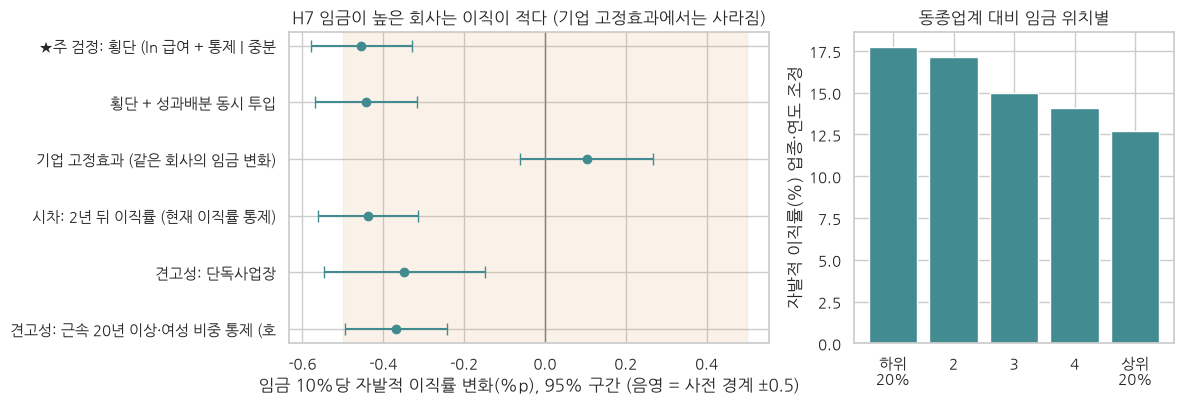

In [59]:
# [H7] 임금 → 자발적 이직률
if WH_TABLES is not None:
    t7 = WH_TABLES['H7_임금_이직률.csv']
    q7 = WH_TABLES['H7_임금위치_5분위.csv']
    display(t7)
    display(q7)
    save_table(t7, 'H7_임금_이직률', index=False)
    save_table(q7, 'H7_임금위치_5분위', index=False)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.5, 1]})
    d_ = t7[t7['모형'].str.startswith(('★', '횡단 + 성과', '기업 고정', '시차', '견고성: 단독', '견고성: 근속'))].iloc[::-1]
    yy = np.arange(len(d_))
    axes[0].errorbar(d_['효과'], yy, xerr=[d_['효과'] - d_['95% 하한'], d_['95% 상한'] - d_['효과']], fmt='o', color=MAIN_COLOR, capsize=4)
    axes[0].axvline(0, color='grey', lw=1)
    axes[0].axvspan(-WH.BOUND_H7, WH.BOUND_H7, color=SUB_COLOR, alpha=.12)
    axes[0].set(yticks=yy, yticklabels=[m[:26] for m in d_['모형']], xlabel='임금 10%당 자발적 이직률 변화(%p), 95% 구간 (음영 = 사전 경계 ±0.5)',
                title='H7 임금이 높은 회사는 이직이 적다 (기업 고정효과에서는 사라짐)')
    axes[1].bar(range(5), q7['이직률_업종연도조정'], color=MAIN_COLOR)
    axes[1].set(xticks=range(5), xticklabels=['하위\n20%', '2', '3', '4', '상위\n20%'], ylabel='자발적 이직률(%) 업종·연도 조정',
                title='동종업계 대비 임금 위치별')
    plt.tight_layout(); save_figure(fig, 'H7_wage_turnover'); plt.show()
    PRIMARY.append(('H7', '임금 → 자발적 이직률 횡단 (WPS, 통제+중분류×연도 FE)', float(t7.iloc[0]['p(효과=0)']),
                    '임금 10%당 이직률(%p)', float(t7.iloc[0]['효과'])))

**H7 결과** (WPS, 8,264행·2,518곳): 같은 업종·연도에서 **임금이 10% 높은 회사는 정규직 자발적 이직률이 0.45%p 낮습니다**(95% 구간 −0.58~−0.33, p < 0.001). 단독사업장(−0.35), 근속 20년 이상·여성 비중 통제(−0.37, 호봉제로 거꾸로 생기는 관계 점검), 2년 뒤 이직률(−0.44), 정규직 전체 이직률(−0.46)에서도 방향과 크기가 같습니다. **동종업계 대비 임금 위치 하위 20% 회사의 이직률은 17.8%, 상위 20%는 12.7%**(업종·연도 조정)로 약 5%p 차이입니다.
- **크기는 사전 경계(±0.5%p) 근처**라서 "관계가 분명하다"까지이고 "크다"고는 말하기 어렵습니다(평균 이직률 16% 기준 탄력성 약 −0.3).
- **기업 고정효과에서는 사라집니다**(+0.10%p, p = 0.22): 임금이 높은 회사가 이직이 적다는 것은 분명하지만, 한 회사가 임금을 올린 만큼 이직이 줄어드는지는 이 데이터로 확인되지 않습니다. 2년 사이 임금 변화가 작고 측정 오차가 크기 때문일 수 있습니다.
- 해석: **임금을 맞춰야 하는 근거는 생산성이 아니라 인력 유지**입니다. 진단 기능의 임금 위치 축에 이 관계를 근거로 붙입니다.

,모형,관측,사업체,효과,SE,95% 하한,95% 상한,p(효과=0),90% 하한,90% 상한,TOST p
0,★주 검정: 시차 (성과배분_t → Δln 부가가치 t→t+2),5308,2009,5.331,1.619,2.157,8.505,0.001,2.666,7.996,0.992
1,시차 + 임금 동시 투입,5133,1973,4.620,1.636,1.413,7.826,0.005,1.927,7.312,0.975
2,"시차, 통제 없음",5308,2009,7.293,1.642,4.075,10.510,0.000,4.591,9.994,1.000
3,견고성: 단독사업장,2710,1072,6.447,2.277,1.985,10.909,0.005,2.699,10.195,0.987
4,견고성: 제조원가 급여 결측 없음,4958,1962,3.561,1.641,0.345,6.777,0.030,0.861,6.261,0.906
5,견고성: 상하 1% 절단,5308,2009,4.063,1.383,1.353,6.773,0.003,1.788,6.339,0.973
6,대체 원인: 성과배분 수준 1개월분당,5235,2003,4.520,1.092,2.379,6.661,0.000,NaN,NaN,NaN
7,대체 결과: Δln 1인당 매출(%),5552,2036,2.110,1.236,-0.312,4.533,0.088,NaN,NaN,NaN
8,대체 결과: Δ영업이익률(%p),5521,2031,0.713,0.304,0.116,1.310,0.019,NaN,NaN,NaN
9,"참고: 같은 해 횡단 (ln 부가가치 수준 차이, 로그×100 아님)",8506,2545,22.004,2.163,17.765,26.244,0.000,NaN,NaN,NaN


,모형,관측,사업체,효과,SE,95% 하한,95% 상한,p(효과=0)
0,사전 추세: 성과배분_t ~ Δln 부가가치 t−2→t (위약 검정),5308,2009,12.155,1.577,9.064,15.245,0.000
1,신규 도입: 2년 전 미실시 중 올해 실시 vs 계속 미실시,2887,1449,1.638,2.501,-3.264,6.541,0.512
2,신규 도입의 사전 추세 (t−2→t),4024,1748,14.723,2.338,10.139,19.306,0.000
3,2년 뒤 실시 여부 통제,5308,2009,-2.776,2.033,-6.760,1.208,0.172
4,분해: 부가가치 변화 중 인건비 부분(t년 부가가치 대비 %),5308,2009,1.317,0.606,0.129,2.505,0.030
5,"분해: 인건비를 뺀 나머지 부분(영업이익·감가 등, %)",5308,2009,4.953,1.675,1.671,8.235,0.003


,모형,관측,사업체,효과,SE,95% 하한,95% 상한,p(효과=0)
0,"H7b 성과배분 → 이직률(%p), 횡단",8850,2604,-1.346,0.524,-2.373,-0.318,0.010
1,"H7b 성과배분 → 이직률, 임금 통제",8264,2518,-1.187,0.524,-2.215,-0.160,0.024
2,"H7b 성과배분 → 이직률, 기업 FE",8450,2204,0.482,0.641,-0.773,1.738,0.451
3,"H8b 임금 10%당 → Δln 부가가치(%), 시차",5133,1973,2.038,0.357,1.337,2.739,0.000
4,"H8b 임금 → Δln 부가가치, 성과배분 통제",5133,1973,2.035,0.355,1.339,2.732,0.000


,가설,단위,경계,관측,사업체,효과,SE,95% 하한,95% 상한,p(효과=0),90% 하한,90% 상한,TOST p,p_holm(효과=0),TOST p_holm
0,H7 임금 → 자발적 이직률,임금 10%당 %p,±0.5,8264,2518,-0.455,0.064,-0.579,-0.330,0.000,-0.559,-0.350,0.237,0.000,0.473
1,H8 성과배분 → 2년 뒤 생산성,%,±1.4,5308,2009,5.331,1.619,2.157,8.505,0.001,2.666,7.996,0.992,0.001,0.992


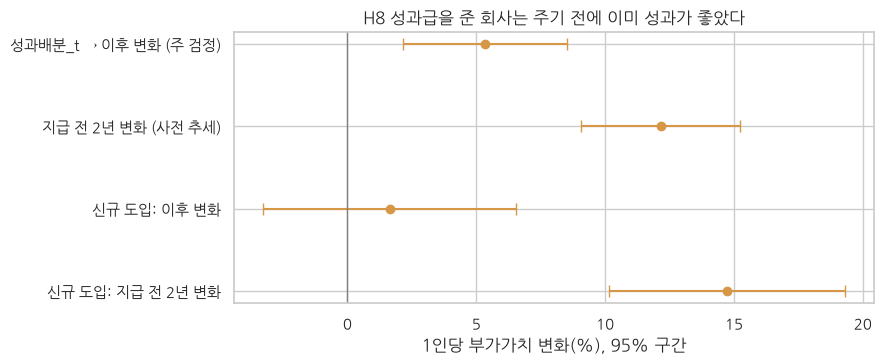

In [60]:
# [H8] 성과배분 → 이후 생산성, 그리고 사전 추세·신규 도입 점검
if WH_TABLES is not None:
    t8 = WH_TABLES['H8_성과배분_생산성.csv']
    c8 = WH_TABLES['H8_추가점검.csv']
    x7 = WH_TABLES['H7b_H8b_교차.csv']
    sm_ = WH_TABLES['H7_H8_주검정요약.csv']
    display(t8)
    display(c8)
    display(x7)
    display(sm_)
    for nm, t in [('H8_성과배분_생산성', t8), ('H8_추가점검', c8), ('H7b_H8b_교차', x7), ('H7_H8_주검정요약', sm_)]:
        save_table(t, nm, index=False)
    pick = [('성과배분_t → 이후 변화 (주 검정)', t8.iloc[0]),
            ('지급 전 2년 변화 (사전 추세)', c8[c8['모형'].str.startswith('사전 추세')].iloc[0]),
            ('신규 도입: 이후 변화', c8[c8['모형'].str.startswith('신규 도입:')].iloc[0]),
            ('신규 도입: 지급 전 2년 변화', c8[c8['모형'].str.startswith('신규 도입의')].iloc[0])][::-1]
    fig, ax = plt.subplots(figsize=(9, 3.8))
    yy = np.arange(len(pick))
    ax.errorbar([r['효과'] for _, r in pick], yy, xerr=[[r['효과'] - r['95% 하한'] for _, r in pick], [r['95% 상한'] - r['효과'] for _, r in pick]],
                fmt='o', color=SUB_COLOR, capsize=4)
    ax.axvline(0, color='grey', lw=1)
    ax.set(yticks=yy, yticklabels=[n for n, _ in pick], xlabel='1인당 부가가치 변화(%), 95% 구간',
           title='H8 성과급을 준 회사는 주기 전에 이미 성과가 좋았다')
    plt.tight_layout(); save_figure(fig, 'H8_bonus_productivity'); plt.show()
    PRIMARY.append(('H8', '성과배분 → 2년 뒤 1인당 부가가치 (WPS, 시차) ※ 사전 추세 점검 통과 못함', float(t8.iloc[0]['p(효과=0)']),
                    '1인당 부가가치 변화(%)', float(t8.iloc[0]['효과'])))

**H8 결과** (WPS, 5,308행·2,009곳): 주 검정만 보면 성과배분을 한 회사의 **2년 뒤 1인당 부가가치가 5.3% 더 늘어**(95% 구간 +2.2~+8.5, p = 0.001) 성과급이 생산성을 올리는 것처럼 보입니다. 그런데 점검하면 이 해석이 무너집니다.

| 점검 | 효과(%) | 의미 |
|---|---|---|
| **사전 추세** (지급 전 2년) | **+12.2** (p < 0.001) | 성과급을 준 회사는 주기 전에 이미 생산성이 더 늘어 있었음 → 성과급은 성과에 대한 **보상** |
| 신규 도입 회사의 사전 추세 | +14.7 (p < 0.001) | 새로 도입한 회사도 직전에 성과가 좋았음 |
| **신규 도입 회사의 이후 변화** | **+1.6** (−3.3~+6.5, p = 0.51) | 도입 뒤 생산성 상승은 확인되지 않음 |
| 2년 뒤 실시 여부 통제 | −2.8 (p = 0.17) | 주 검정의 +5.3은 "계속 성과가 좋아 또 준 회사"가 만든 것 |

- **판정:** 주 검정은 유의하지만 사전 추세 점검을 통과하지 못하므로 **"성과급이 생산성을 올린다"는 인과 해석은 지지되지 않습니다.** 가장 깨끗한 비교(신규 도입)의 구간(−3.3~+6.5%)은 0과 성과배분 비용(약 2.8%)을 모두 포함해 "효과가 없다"고 단정할 수도 없습니다. **"올린다는 근거가 이 데이터에는 없다"**가 정직한 결론입니다.
- 교차(탐색): 성과배분 → 이직률은 횡단 −1.3%p(p = 0.01)이나 기업 고정효과에서는 +0.5%p(p = 0.45). 임금 → 이후 생산성(+2.0%/10%)은 사전 추세 점검을 하지 않아 해석하지 않습니다.
- H6-①(이익이 늘면 급여도 는다)과 같은 그림입니다. **성과급은 생산성의 원인이라기보다 성과를 나누는 결과**입니다.

> **H7·H8 결론**: 임금을 맞춰야 하는 근거는 **인력 유지**(동종 대비 임금 위치가 낮을수록 자발적 이직이 많음, 단 같은 회사 안의 변화에서는 미확인)이고, 성과급은 **생산성을 끌어올리는 수단이 아니라 이익을 나누는 비용**입니다. 그래서 고정 성과급보다 이익연동(기능 3)이 회사의 위험을 줄이는 방식이라는 논리가 성립합니다.

### 4-3. 요약

In [61]:
# [4-6] 대표 검정 요약
summary = pd.DataFrame(PRIMARY, columns=['가설', '대표 검정', 'p', '효과크기 지표', '효과크기'])
summary['p_holm'] = holm(summary['p'])
summary['유의(α=0.05)'] = summary['p_holm'].lt(ALPHA)
summary['산술식 연결'] = summary['가설'].map({
    'H1': '2-1 인건비 = 급여총액 S (유의하지 않아야 지지)',
    'H2': '1장 업종 = 중분류(모자라면 대분류), 2-3 업종 기준',
    'H3': '1장 같은 중분류 먼저 → 대분류에서 채운 매출·1인당 자산이 가까운 20곳',
    'H4': '0장 K = 3, 2-3 3년 합산',
    'H5': '2-5 비용 계산·2-6 이익연동 전환이 중심 결과',
    'H6': "'이익 효과를 예측하지 않는다'(산술식 서두) → 모델링에서 효과를 자동 가산하지 않음",
    'H7': '진단의 임금 위치 축: 위치가 낮을수록 자발적 이직이 많다는 근거 (같은 회사 안의 변화에서는 미확인)',
    'H8': '유의하나 사전 추세(+12%)를 통과하지 못해 인과 해석 안 함 → 성과급은 "성과 공유", 이익연동(2-6)의 근거'})
summary.loc[summary['대표 검정'].str.startswith('②'), '유의(α=0.05)'] = summary['p_holm'].lt(ALPHA)   # TOST: 유의 = 효과가 ±0.6%p 안
display(summary)
save_table(summary, 'H_summary', index=False)

,가설,대표 검정,p,효과크기 지표,효과크기,p_holm,유의(α=0.05),산술식 연결
0,H1,W공시 → 1인당 급여 (통제 회귀),0.730,Cliff's δ,-0.016,0.730,False,2-1 인건비 = 급여총액 S (유의하지 않아야 지지)
1,H2,업종 그룹(중분류 우선) → 1인당 급여 (Kruskal),0.000,ε²,0.090,0.000,True,"1장 업종 = 중분류(모자라면 대분류), 2-3 업종 기준"
2,H3,산술식 비교군 20곳 vs 업종 기준 중앙값 예측 오차 (Wilcoxon),0.000,비교군이 더 정확한 비율,0.608,0.000,True,1장 같은 중분류 먼저 → 대분류에서 채운 매출·1인당 자산이 가까운 20곳
3,H4,3년 합산 vs 1년 판정 유지 (McNemar),0.000,판정 유지율 차이,0.043,0.001,True,"0장 K = 3, 2-3 3년 합산"
4,H5,업종 그룹 → 비용÷영업이익 (Kruskal),0.000,ε²,0.051,0.000,True,2-5 비용 계산·2-6 이익연동 전환이 중심 결과
5,H6,"① 성과 공유 β(1,000명~)−β(~299명), FE·클러스터",0.000,추가 기울기(원/원),0.026,0.000,True,'이익 효과를 예측하지 않는다'(산술식 서두) → 모델링에서 효과를 자동 가산하지 않음
6,H6,"② 급여→이익 TOST(h=1, 경계 ±0.6%p)",0.000,"효과(%p, 급여 10%p당)",0.104,0.001,True,'이익 효과를 예측하지 않는다'(산술식 서두) → 모델링에서 효과를 자동 가산하지 않음
7,H7,"임금 → 자발적 이직률 횡단 (WPS, 통제+중분류×연도 FE)",0.000,임금 10%당 이직률(%p),-0.455,0.000,True,진단의 임금 위치 축: 위치가 낮을수록 자발적 이직이 많다는 근거 (같은 회사 안의...
8,H8,"성과배분 → 2년 뒤 1인당 부가가치 (WPS, 시차) ※ 사전 추세 점검 통과 못함",0.001,1인당 부가가치 변화(%),5.331,0.002,True,"유의하나 사전 추세(+12%)를 통과하지 못해 인과 해석 안 함 → 성과급은 ""성과..."


**결과**: Holm 보정 후 **H1만 유의하지 않고(지지 방향: 인건비 = S로 충분), H2-H6은 모두 유의**합니다. H2(ε² 0.090)와 H5(ε² 0.051)는 통계적으로 유의하지만 효과 크기가 작아, 발표에서는 "업종보다 회사 차이가 크다"로 해석합니다. H6-②의 '유의'는 효과가 ±0.6%p 경계 **안에 있다**(동등성)는 뜻입니다.
- **H7·H8(WPS)**은 표본이 달라 위 Holm 보정에 같이 넣었지만 주 검정 표본·경계는 따로 정했습니다. H7(임금 → 자발적 이직률)은 유의하고, H8(성과배분 → 생산성)은 유의하지만 사전 추세 점검을 통과하지 못해 **"성과급이 생산성을 올린다"는 해석은 하지 않습니다**(H8 결과 참고). WPS 파일이 없으면 이 두 행은 요약표에서 빠집니다.


## 5️⃣ 산술식 적용 (산술식 최종본 v3 · `formula.py`)

이 장의 계산은 모두 `formula.compute()` 한 번으로 합니다. 아래 셀은 결과를 이 노트북의 열 이름으로 바꿔 보여 주기만 합니다. 규칙·상수를 바꿀 때는 `formula.py`와 `결정표.md`를 고칩니다.

가설검정(4장)에서 확인한 근거를 바탕으로, 팀 산술식 최종본(v3, **2026-11-20 업종 규칙 수정판**)을 이 노트북의 데이터에 적용합니다.

**이번 수정에서 바뀐 두 가지**
1. **업종:** 제조 4군(업종 묶음)을 버리고 한국표준산업분류 **중분류**를 씁니다. 비교군은 같은 중분류에서 먼저 고르고, 20곳이 안 되면 같은 대분류에서 채웁니다. 지급 여력의 업종 기준도 중분류 → 대분류 → 전체 순서입니다.
2. **2-6 과거 적용 → 이익연동 전환:** 과거 연도에 비율을 적용해 보는 계산은 하지 않습니다(11-21 결정). 시작값은 3년 합산 기준으로 급여 5%와 같은 금액이 되는 영업이익 비율이고, 비율·상한·하한을 넣으면 3년 연평균 기준 지급액을 계산합니다(`formula.profit_link_plan`).

| 산술식 장 | 이 노트북 | 가설검정 근거 |
|---|---|---|
| 1장 비교군 (같은 중분류 먼저 → 모자라면 같은 대분류에서, 매출·1인당 자산이 가까운 20곳) | 5-2 | H3 |
| 2-2 임금 위치 / 2-3 지급 여력 | 5-2, 5-3 | H1(인건비 = S), H4(K = 3), H7(임금 위치가 낮을수록 자발적 이직이 많음) |
| 2-5 비용 계산 / 2-6 이익연동 전환 | 5-5, 5-6 | H5, H6·H8(성과급은 생산성의 원인이 아니라 성과 공유) |

- 표본은 4장과 같은 **산술식 분석 자격(v3)**이고, 3년 판정 구간(2023~2025년)에서는 **2,205곳**입니다. `formula.py`와 같은 규칙으로 만들어 문서 숫자와 그대로 맞춥니다(5-8).
- 이익연동 전환의 시작값 α\*는 진단과 같은 **3년 합산**(5% × ΣS ÷ ΣOP)이라 5-8에서 산술식 문서 숫자(8.13%)와 그대로 맞습니다.
- 이 패널에 없는 영업활동현금흐름 표시, 공시 1인 평균급여 대조, WPS 기준값은 계산하지 않고, 산술식 결과 파일이 있으면 6-8에서 붙입니다.

### 5-0. 산술식 설정값

In [62]:
# [5-0] 산술식 설정값 — 숫자는 모두 formula.py [상수] 블록에서 옴 (결정표.md 10장)
F_START, F_END = 2023, 2025      # 분석 구간 (2015~2025 중 어느 구간이든 가능)
K_YEARS = F_END - F_START + 1    # 합산 연수 (기본 F.YEARS_IN_WINDOW = 3)
print(f'비교군 {F.PEER_COUNT}곳 · 임금 높음/낮음 경계 {F.HIGH_P}/{F.LOW_P} · 업종 기준 최소 {F.INDUSTRY_MIN_FIRMS}곳')
print(f'비용 예시: 급여의 {F.PAY_RATE:.0%} × (1 + c {F.OVERHEAD_C}) · 기본급 c′ {F.OVERHEAD_C_BASE:.3f} · g* 표시 한도 {F.GSTAR_LIMIT:.0%}')

CFO_DIR = None    # 선택: DART 정형재무 '연도별_소형내보내기' 폴더 → 현금흐름 표시
WPS_PATH = None   # 선택: WPS 원자료 CSV (이용 조건상 공유 금지) → WPS 참고값

# 분석 자격(core): formula.build_core. 감가상각비는 2장에서 이미 비웠으므로 clean_dep=False
PANEL_F = panel_raw.rename(columns=F.RENAME)
CORE = F.build_core(PANEL_F, cfo=F.load_cfo(CFO_DIR) if CFO_DIR else None, clean_dep=False)
WPS_RAW = F.load_wps(WPS_PATH) if WPS_PATH else None
v3p = panel_raw.loc[F.mark_sample(PANEL_F)['core']]
print(f'산술식 분석 자격(core): {len(CORE):,}행 · {CORE["id"].nunique():,}곳')
assert set(v3p.index) == set(hp.index), '4장 가설검정 표본(hp)과 산술식 표본이 다릅니다.'
print('4장 가설검정 표본(hp)과 같은 표본입니다.')


비교군 20곳 · 임금 높음/낮음 경계 0.75/0.25 · 업종 기준 최소 11곳
비용 예시: 급여의 5% × (1 + c 0.1) · 기본급 c′ 0.183 · g* 표시 한도 10%
산술식 분석 자격(core): 21,761행 · 2,840곳
4장 가설검정 표본(hp)과 같은 표본입니다.


### 5-1. 구간 계산
`formula.compute(CORE, 시작, 끝)` 한 번으로 구간 자료 → 비교군·임금 위치 → 지급 여력 → 비용 → 이익연동 전환 → 진단문장까지 계산합니다. 구간 안 **모든 해에** 분석 자격인 기업만 계산하고(빈칸은 0으로 채우지 않음), 위치 진단은 3년 합산(Σ), 비용 계산은 마지막 해(\_T) 값을 씁니다.


In [63]:
# [5-1] 구간 계산 — formula.compute
def nb_view(res):
    """formula 결과를 이 노트북의 열 이름으로 바꾼다 (5-4 이후 셀과 6-8이 쓰는 이름)."""
    v = pd.DataFrame(index=res.index)
    v['기업명'], v['상장시장'] = res['name'], res['mkt']
    v['업종_중분류'] = res['ind2']
    v['업종_대분류'] = res['ind2'].map(ksic_major)
    for a, b in [('S', 'ΣS'), ('N', 'ΣN'), ('OP', 'ΣOP'), ('REV', 'ΣREV'), ('AST', 'ΣAST')]:
        v[b] = res[a]
    v['한계기업'], v['적자연수'] = res['한계'], res['lossyrs']
    v['w'], v['비교기준'], v['순위P'] = res['w'], res['ref'], res['P']
    v['임금차이'] = res['임금 차이(%)'] / 100
    v['참고구간_하'], v['참고구간_상'], v['같은중분류_수'] = res['ref25'], res['ref75'], res['n_same']
    v['임금위치'] = res['임금 위치']
    n_same = res['n_same'].fillna(0).astype(int)
    v['비교군구성'] = np.where(res['n_same'].notna(), '같은 중분류 ' + n_same.astype(str) + '곳 + 같은 대분류 '
                          + (F.PEER_COUNT - n_same).astype(str) + '곳', '')
    v['규모다름표시'] = res['비교군 주의'].eq('비교 기업의 매출 규모가 크게 다름')
    v['대분류부족'] = res['비교군 주의'].eq('대분류 기업 수 부족(21곳 미만)')
    v['m'], v['업종기준_m'], v['업종기준단위'] = res['opm'], res['opm_ind'], res['업종기준단위']
    v['지급여력'], v['여력사유'], v['현금흐름표시'] = res['지급 여력'], res['여력 사유'], res['현금흐름 표시']
    v['ΔW'], v['이익률하락_pp'], v['비용_영업이익(%)'] = res['dW'], res['하락'], res['비용÷영업이익']
    v['D_방식'], v['부가가치_T'] = res['D상태'], res['A_T']
    v['g*'], v['g*_표시'] = res['g*'] / 100, res['g*표시']
    v['평소변동_pp'], v['평소변동대비'] = res['opm_sd'] * 100, res['평소변동대비']
    v['α'] = res['전환_같은 금액이 되는 영업이익 비율(%)'] / 100
    v['진단문장'] = res['진단문장']
    return v

RES = F.compute(CORE, F_START, F_END, wps=WPS_RAW)
fw, PEERS = nb_view(RES), RES.attrs['peers']
print(f'{F_START}~{F_END} 구간: {len(fw):,}곳 (3년 모두 분석 자격)')
display(fw.head(3).T)


2023~2025 구간: 2,205곳 (3년 모두 분석 자격)


id,100601,100814,100939
기업명,강원에너지,포스코이앤씨,강남제비스코
상장시장,코스닥,기타,코스피
업종_중분류,28,41,20
업종_대분류,C 제조업,F 건설업,C 제조업
ΣS,"17,898,308,521.000","1,820,251,000,000.000","116,830,844,000.000"
ΣN,299.000,"18,022.000","1,908.000"
ΣOP,"12,019,021,726.000","-199,228,368,162.000","-48,062,933,475.000"
ΣREV,"306,037,900,984.000","25,396,006,647,702.000","905,261,937,292.000"
ΣAST,"265,413,384,542.000","23,292,407,444,485.000","1,321,886,679,061.000"
한계기업,False,False,True


### 5-2. 비교군과 임금 위치 (산술식 1장, 2-2 · 2026-11-20 업종 규칙 수정판)
```
업종 = 한국표준산업분류 중분류(업종코드 앞 2자리). 대분류는 그 상위 구분
거리 = (ln 매출 차이)² + (ln 1인당 자산 차이)²   ← 두 값은 대분류 안에서 표준화, 3년 합산
후보 = 같은 대분류의 다른 기업. 같은 중분류 기업을 먼저 고르고, 그다음 다른 중분류 기업을 거리 순으로 고름
비교군 = 거리가 가까운 순 20곳 (자기 제외) → 같은 중분류가 20곳 미만이면 모자란 만큼 같은 대분류에서 채움
대분류의 기업이 21곳 미만이면 → 임금 위치 '비교 불가'
1인당 급여 w = ΣS ÷ ΣN,  임금 차이 = w ÷ 비교군 중앙값 − 1
순위 P = (나보다 낮은 곳 + 0.5 × 같은 곳) ÷ 20 → P ≥ 0.75 높음 / P ≤ 0.25 낮음 / 그 외 보통
```
"같은 중분류 먼저"는 `formula.select_peers`가 두 단계로 고릅니다: ① 같은 중분류 후보를 거리 가까운 순으로 → ② 20곳이 안 되면 같은 대분류의 다른 중분류 후보를 거리 가까운 순으로 채움. 예전에는 다른 중분류 기업의 거리에 1000을 더하는 방식으로 구현했고, 두 방식이 같은 20곳을 고른다는 것을 `formula/tests`에서 확인합니다.

In [64]:
# [5-2] 비교군 20곳과 임금 위치 — formula.wage_position (같은 중분류 먼저 → 모자라면 같은 대분류에서 채움)
display(fw['임금위치'].value_counts().to_frame('기업 수'))
print('비교 불가 사유 — 매출·자산 없음:', int(RES['비교군 주의'].eq('매출·자산 없음').sum()),
      '/ 대분류 21곳 미만:', int(fw['대분류부족'].sum()))
print('비교군 매출 규모가 크게 다름(1/3배 미만 또는 3배 초과):', int(fw['규모다름표시'].sum()), '곳')
judged_peer = fw['같은중분류_수'].notna()
PEER_SAME_SHARE = (fw.loc[judged_peer, '같은중분류_수'] / F.PEER_COUNT).mean()
N_FILLED = int(fw.loc[judged_peer, '같은중분류_수'].lt(F.PEER_COUNT).sum())
print(f'비교군 중 같은 중분류 비율 평균: {PEER_SAME_SHARE:.0%} (산술식 문서 96%, 옛 제조 4군 42%)')
print(f'같은 중분류만으로 20곳: {int(judged_peer.sum()) - N_FILLED:,}곳 / 같은 대분류에서 보충: {N_FILLED:,}곳 (문서 1,883 / 208)')
_hy = fw.index[fw['기업명'].eq('현대자동차')]
if len(_hy):
    print('비교군 목록 예: 현대자동차')
    display(PEERS[PEERS['id'].eq(_hy[0])].assign(기업명=lambda d: d['peer_id'].map(fw['기업명']),
                                                급여_만원=lambda d: d['peer_id'].map(fw['w']) / 1e4).round(1))


,기업 수
임금위치,
임금 보통,884
임금 높음,653
임금 낮음,554
비교 불가,114


비교 불가 사유 — 매출·자산 없음: 70 / 대분류 21곳 미만: 44
비교군 매출 규모가 크게 다름(1/3배 미만 또는 3배 초과): 292 곳
비교군 중 같은 중분류 비율 평균: 96% (산술식 문서 96%, 옛 제조 4군 42%)
같은 중분류만으로 20곳: 1,883곳 / 같은 대분류에서 보충: 208곳 (문서 1,883 / 208)
비교군 목록 예: 현대자동차


,id,순번,peer_id,같은 중분류,거리,기업명,급여_만원
7880,164742,1,106641,True,0.100,기아,"13,226.100"
7881,164742,2,164788,True,1.600,현대모비스,"12,863.600"
7882,164742,3,302634,True,1.800,현대트랜시스,"10,886.100"
7883,164742,4,106623,True,2.300,현대위아,"12,479.300"
7884,164742,5,138242,True,3.700,KG모빌리티,"9,239.500"
7885,164742,6,1042775,True,3.900,HL만도,"10,399.500"
7886,164742,7,152455,True,4.100,현대케피코,"11,875.700"
7887,164742,8,132992,True,5.000,성우하이텍,"7,680.000"
7888,164742,9,125521,True,5.500,에스엘,"8,427.100"
7889,164742,10,114154,True,5.800,디와이덕양,"8,735.500"


### 5-3. 지급 여력 (산술식 2-3 · 2026-11-20 업종 규칙 수정판)
```
영업이익률 m = ΣOP ÷ ΣREV
업종 기준 = 같은 중분류의 m 중앙값 (11곳 미만이면 같은 대분류, 그것도 11곳 미만이면 전체 중앙값)
여력 제약: ΣOP < 0 (3년 합산 영업적자) 또는 3년 모두 이자보상비율 < 1 (한계기업, KPC 기준)
여력 있음: 제약이 아니고 m ≥ 업종 기준 / 여력 보통: 그 외 / 판정 불가: 제약이 아닌데 매출이 없음
```

In [65]:
# [5-3] 지급 여력 — formula.pay_capacity
display(fw['지급여력'].value_counts().to_frame('기업 수'))
display(fw.loc[fw['지급여력'].eq('여력 제약'), '여력사유'].value_counts().to_frame('여력 제약 사유'))
display(fw['업종기준단위'].value_counts().to_frame('업종 기준 단위'))   # 문서: 중분류 2,080 · 대분류 79 · 전체 46


,기업 수
지급여력,
여력 있음,1043
여력 제약,827
여력 보통,309
판정 불가,26


,여력 제약 사유
여력사유,
"3년 합산 영업적자, 이자보상비율 3년 연속 1 미만",516
3년 합산 영업적자,278
이자보상비율 3년 연속 1 미만,33


,업종 기준 단위
업종기준단위,
중분류,2080
대분류,79
전체,46


### 5-4. 두 축 결과 (산술식 4장)

In [66]:
# [5-4] 임금 위치 × 지급 여력
POS_ORDER = ['임금 높음', '임금 보통', '임금 낮음']
CAP_ORDER = ['여력 있음', '여력 보통', '여력 제약']
judged = fw.loc[fw['임금위치'].isin(POS_ORDER) & fw['지급여력'].isin(CAP_ORDER)]
display(pd.crosstab(judged['임금위치'], judged['지급여력']).reindex(index=POS_ORDER, columns=CAP_ORDER))
print(f'두 축 모두 판정: {len(judged):,}곳 / {len(fw):,}곳 ({len(judged) / len(fw):.0%})')
rho = stats.spearmanr(judged['순위P'], judged['m'], nan_policy='omit')[0]
print(f'두 축의 독립성: 임금 순위 P와 영업이익률 m의 순위상관 = {rho:.3f} (산술식 문서 0.09)')

지급여력,여력 있음,여력 보통,여력 제약
임금위치,,,
임금 높음,358,91,204
임금 보통,411,138,335
임금 낮음,246,74,234


두 축 모두 판정: 2,091곳 / 2,205곳 (95%)
두 축의 독립성: 임금 순위 P와 영업이익률 m의 순위상관 = 0.085 (산술식 문서 0.09)


**결과**: 2,205곳 중 2,091곳(95%)이 두 축 모두 판정됐습니다.
- 임금 위치: 높음 653 · 보통 884 · 낮음 554 · 비교 불가 114(매출·자산 없음 70 + 대분류 21곳 미만 44)
- 지급 여력: 있음 1,043 · 보통 309 · 제약 827(38%) · 판정 불가 26
- 업종 기준 단위: 중분류 2,080곳 · 대분류 79곳 · 전체 46곳
- 비교군 중 같은 중분류 평균 96%(옛 제조 4군 42%). 같은 중분류만으로 20곳을 채운 기업 1,883곳, 같은 대분류에서 보충한 기업 208곳
- 두 축의 순위상관 0.085로 서로 거의 독립입니다.

임금 위치 × 지급 여력 표와 위 숫자가 모두 **산술식 최종본(업종 규칙 수정판) 4장과 같습니다.** 옛 제조 4군과 비교하면 임금 높음 623 → 653, 임금 낮음 566 → 554, 여력 있음 1,064 → 1,043으로 바뀌었습니다. 여력 제약 827곳은 업종과 무관해서 그대로입니다.

### 5-5. 비용 계산 — 중심 결과 (산술식 2-5)
예시는 산술식 문서와 같은 **급여 5% 인상, c = 0.1**입니다. 금액은 모두 마지막 해(2025년) 값입니다.
```
ΔW = 인상액 × (1 + c)
영업이익률 하락(%p) = ΔW ÷ REV_T × 100        비용 ÷ 영업이익(%) = ΔW ÷ OP_T × 100 (OP_T > 0)
g* = ΔW ÷ (S_T + OP_T + D_T)   D = 감가 + 세금과공과 + 대손 (정식 / 보완: 빈 항목 0 / 간이: 감가 없으면 D = 0)
평소 변동 대비 = 영업이익률 하락 ÷ 영업이익률 평소 변동(연간 변화의 표준편차, 5년 이상)
```

In [67]:
# [5-5] 비용 계산 — formula.cost (급여 5%, c = 0.1, 마지막 해 값)
ok = fw['지급여력'].ne('여력 제약')
cost_summary = pd.Series({
    '대상(여력 제약 아님)': int(ok.sum()),
    '영업이익률 하락 중앙(%p)': fw.loc[ok, '이익률하락_pp'].median(),
    '비용÷영업이익 중앙(%)': fw.loc[ok, '비용_영업이익(%)'].median(),
    'g* 중앙(%)': fw.loc[ok, 'g*'].median() * 100,
    'g* 계산 불가(곳)': int(fw.loc[ok, 'g*_표시'].str.startswith('계산 불가').sum()),
    'g* 10% 초과(곳)': int(fw.loc[ok, 'g*_표시'].str.startswith('10% 초과').sum()),
    '평소 변동 대비 중앙': fw.loc[ok, '평소변동대비'].median(),
}, name='값')
display(cost_summary.to_frame().round(2))
display(fw['D_방식'].value_counts().to_frame('D 계산 방식'))


,값
대상(여력 제약 아님),"1,378.000"
영업이익률 하락 중앙(%p),0.590
비용÷영업이익 중앙(%),8.120
g* 중앙(%),2.850
g* 계산 불가(곳),7.000
g* 10% 초과(곳),8.000
평소 변동 대비 중앙,0.130


,D 계산 방식
D_방식,
정식,1466
보완,445
간이,294


### 5-6. 이익연동 전환 — 중심 결과 (산술식 2-6)
"급여의 5%를 고정으로 주던 성과급을 영업이익의 α로 바꾸면" 어떻게 되는지 진단과 같은 3년 연평균으로 봅니다. **과거 연도에 비율을 적용해 보는 계산은 하지 않습니다**(11-21 결정).
```
시작값 α* = 5% × ΣS ÷ ΣOP              (진단과 같은 3년 합산, 3년 합산 영업이익이 0 이하면 계산하지 않음)
연동 지급 = α × max(연평균 영업이익, 0)     (선택: 상한·하한 = 급여의 몇 %). 시작값이면 고정 지급과 같음
회사 부담 ÷ 영업이익 = α × (1 + c)          → 흑자인 해에는 어느 회사나 같음
급여 대비 지급률 = 연동 지급 ÷ 급여총액      → 회사마다 다른 것은 직원 몫
```
- `formula.profit_link_plan(ctx, 기업, alpha=…, cap=…, floor=…)`로 비율·상한·하한을 바꿔 다시 계산합니다(MVP 슬라이더).
- 앞으로 3년의 흔들림(0원인 해가 생길 확률, 수령액 변동)은 6-5 모델 E의 예측으로, 불황이 오면 어떻게 되는지는 기능 4의 업계 불황 대비 점검(`formula.stress_test`, 산술식 2-11)로 봅니다.


In [68]:
# [5-6] 이익연동 전환 — formula.profit_share_rate (compute 안) + profit_link_plan (기업별)
a_ = fw['α'].dropna()
display(pd.Series({'계산 기업(3년 합산 흑자)': len(a_), 'α* 중앙(%)': a_.median() * 100,
                   'α* 25%(%)': a_.quantile(.25) * 100, 'α* 75%(%)': a_.quantile(.75) * 100}, name='값').to_frame().round(2))
CTX = F.sim_context(RES, CORE)
for firm in ['SK하이닉스', '현대자동차', '오뚜기']:
    _i = fw.index[fw['기업명'].eq(firm)]
    if len(_i):
        p_ = F.profit_link_plan(CTX, _i[0], alpha=0.10)
        print(f"{firm}: 영업이익의 10%를 주면 급여의 {p_['급여 대비 지급률(%)']:.1f}% (고정 5%의 {p_['연동 ÷ 고정']:.1f}배), "
              f"회사 부담은 영업이익의 {p_['연동 부담 ÷ 영업이익(%)']:.0f}% / 시작값 α* {fw.loc[_i[0], 'α'] * 100:.1f}%")
save_table(F.to_table(RES), f'5_산술식결과_{F_START}_{F_END}', index=False)


,값
계산 기업(3년 합산 흑자),"1,411.000"
α* 중앙(%),8.130
α* 25%(%),4.210
α* 75%(%),17.290


SK하이닉스: 영업이익의 10%를 주면 급여의 44.4% (고정 5%의 8.9배), 회사 부담은 영업이익의 11% / 시작값 α* 1.1%
현대자동차: 영업이익의 10%를 주면 급여의 6.1% (고정 5%의 1.2배), 회사 부담은 영업이익의 11% / 시작값 α* 8.2%
오뚜기: 영업이익의 10%를 주면 급여의 7.4% (고정 5%의 1.5배), 회사 부담은 영업이익의 11% / 시작값 α* 6.7%


### 5-6-b. 인상안 협상 구간 — 기능 2의 첫 화면 (산술식 2-10 ⓪, 결정표 14장)
```
하한 = 비교군 인상률 g                                   (업계만큼 올리기, 노측 근거)
상한 = g × (우리 이익÷급여) ÷ (비교군 이익÷급여 중앙값)   (업계만큼만 부담하기, 사측 근거)
       = 비용÷영업이익(5-5)을 비교군과 같게 만드는 인상률, 마지막 해 이익을 다 쓰는 인상에서 제한
```
- 새 계산 체계가 아니라 기존 결과(비교군 인상률, 비용÷영업이익)를 앞으로 꺼낸 것입니다. 평상시 기준이고 불황은 6장·기능 4(업계 불황 대비 점검)에서만 봅니다.
- 상한이 10%를 넘으면 "10% 초과", 비교군 이익÷급여 중앙값이 0 이하면 **"업계 적자로 인한 상한 산출 보류"**(하한만 제시)로 표시합니다.
- 상한 < 하한이면 "업계만큼 주면 우리 부담이 업계보다 크다" → 이익연동 전환(5-6) 검토 신호입니다.

In [69]:
# [5-6-b] 인상안 협상 구간 (formula.negotiation_range와 같은 값이 sim_context에 열로 들어 있음)
rng_ = CTX.firms
state_ = rng_['상한 상태'].value_counts().rename('기업 수').to_frame()
display(state_)
ok_ = rng_['상한'].notna() & rng_['하한'].notna()
print(f"상한이 계산된 {ok_.sum():,}곳 중 상한 ≥ 하한 {int((rng_.loc[ok_, '상한'] >= rng_.loc[ok_, '하한']).sum()):,}곳 "
      f"({(rng_.loc[ok_, '상한'] >= rng_.loc[ok_, '하한']).mean():.0%}) · 하한 중앙 {rng_['하한'].median():.2%} · 상한 중앙 {rng_.loc[ok_, '상한'].median():.2%}")
by_cap = rng_[ok_].assign(위=lambda d: d['상한'] >= d['하한']).groupby('지급 여력')['위'].mean().rename('상한 ≥ 하한 비율')
display(by_cap.to_frame().round(2))
ex_ = rng_[rng_['name'].isin(['현대자동차', '삼성전자', '기아', 'LG전자', 'LG유플러스', '오뚜기', 'HD현대중공업'])]
display(ex_[['name', '지급 여력', '하한', '상한 표시', '상한 상태', '구간 해석']].assign(하한=lambda d: (d['하한'] * 100).round(1)))
save_table(rng_.rename_axis('id').reset_index()[['id', 'name', '하한', '상한', '상한 원값', '상한 표시', '상한 상태', '구간 해석']],
           '5_6b_협상구간', index=False)

,기업 수
상한 상태,
계산,1065
업계 적자로 인한 상한 산출 보류,446
3년 합산 영업적자,436
적자 전환 직전에서 제한,144
비교군 인상률 없음,114


상한이 계산된 1,645곳 중 상한 ≥ 하한 767곳 (47%) · 하한 중앙 3.76% · 상한 중앙 2.78%


,상한 ≥ 하한 비율
지급 여력,
여력 보통,0.180
여력 있음,0.790
여력 제약,0.020


,name,지급 여력,하한,상한 표시,상한 상태,구간 해석
id,,,,,,
106641,기아,여력 있음,6.600,10% 초과,계산,업계 수준 이상도 업계만큼의 부담으로 감당 가능
126380,삼성전자,여력 있음,3.500,2.2%,계산,업계만큼 주면 우리 부담이 업계보다 큼. 이익연동 전환 검토
141529,오뚜기,여력 있음,6.500,7.1%,계산,업계 수준 이상도 업계만큼의 부담으로 감당 가능
164742,현대자동차,여력 있음,5.600,7.9%,계산,업계 수준 이상도 업계만큼의 부담으로 감당 가능
231363,LG유플러스,여력 있음,3.200,2.8%,계산,업계만큼 주면 우리 부담이 업계보다 큼. 이익연동 전환 검토
401731,LG전자,여력 보통,3.100,0.0%,적자 전환 직전에서 제한,업계만큼 주면 우리 부담이 업계보다 큼. 이익연동 전환 검토
1390344,HD현대중공업,여력 보통,8.600,9.5%,계산,업계 수준 이상도 업계만큼의 부담으로 감당 가능


### 5-7. 진단문장과 상식 점검 (산술식 2-8, 5장)

In [70]:
# [5-7] 진단문장 — formula.sentence (compute 안에서 만듦)
CHECK_FIRMS = ['SK하이닉스', '삼성전자', 'LG전자', '현대모비스', '기아', 'NAVER', '현대자동차', '삼성SDI',
               '포스코퓨처엠', '카카오', 'LG유플러스', '한미반도체', '셀트리온', 'HD현대중공업', '에코프로비엠', '한화오션', '오뚜기']
check = fw.loc[fw['기업명'].isin(CHECK_FIRMS)].set_index('기업명').reindex(CHECK_FIRMS)
display(check[['업종_중분류', '비교군구성', '임금차이', '임금위치', '지급여력', '여력사유', '이익률하락_pp', '비용_영업이익(%)', 'g*', 'α']].round(3))
for firm in ['SK하이닉스', '현대자동차', '오뚜기']:
    if firm in check.index and pd.notna(check.loc[firm, '진단문장']):
        print('·', check.loc[firm, '진단문장'], '\n')


,업종_중분류,비교군구성,임금차이,임금위치,지급여력,여력사유,이익률하락_pp,비용_영업이익(%),g*,α
기업명,,,,,,,,,,
SK하이닉스,26,같은 중분류 20곳 + 같은 대분류 0곳,0.753,임금 높음,여력 있음,,0.389,0.768,0.006,0.011
삼성전자,26,같은 중분류 20곳 + 같은 대분류 0곳,0.613,임금 높음,여력 있음,,0.457,4.614,0.013,0.103
LG전자,26,같은 중분류 20곳 + 같은 대분류 0곳,0.405,임금 높음,여력 보통,,0.770,NaN,0.068,1.728
현대모비스,30,같은 중분류 20곳 + 같은 대분류 0곳,0.383,임금 높음,여력 있음,,0.253,5.284,0.027,0.051
기아,30,같은 중분류 20곳 + 같은 대분류 0곳,0.422,임금 높음,여력 있음,,0.413,4.517,0.021,0.034
NAVER,63,같은 중분류 20곳 + 같은 대분류 0곳,0.918,임금 높음,여력 있음,,0.557,2.011,0.014,0.016
현대자동차,30,같은 중분류 20곳 + 같은 대분류 0곳,0.343,임금 높음,여력 있음,,0.665,14.896,0.033,0.082
삼성SDI,28,같은 중분류 20곳 + 같은 대분류 0곳,0.358,임금 높음,여력 제약,3년 합산 영업적자,0.580,NaN,NaN,NaN
포스코퓨처엠,28,같은 중분류 20곳 + 같은 대분류 0곳,0.185,임금 보통,여력 제약,이자보상비율 3년 연속 1 미만,0.537,60.910,0.032,0.430


· SK하이닉스의 1인당 급여는 13,787만 원으로, 같은 업종(전자부품·컴퓨터·통신장비(반도체 등)) 중심으로 매출·자산이 비슷한 20곳(같은 중분류 20곳 + 같은 대분류 0곳)의 중앙값보다 +75.3%입니다(순위 100%, 비교 20곳의 가운데 절반은 6,328~9,831만 원) → 임금 높음. 주의: 비교 기업의 매출 규모가 크게 다름. 지급 여력은 '여력 있음'입니다(3년 영업이익률 35.6%, 같은 업종 중앙값 0.9%). 급여를 5% 올리면 회사 부담이 연 3,381억 원 늘어 영업이익률이 0.39%p 낮아집니다(마지막 해 영업이익의 1%). 본전을 찾으려면 급여+영업이익+감가상각비 등이 0.6% 늘어야 합니다. 

· 현대자동차의 1인당 급여는 12,410만 원으로, 같은 업종(자동차·트레일러) 중심으로 매출·자산이 비슷한 20곳(같은 중분류 20곳 + 같은 대분류 0곳)의 중앙값보다 +34.3%입니다(순위 85%, 비교 20곳의 가운데 절반은 8,370~10,521만 원) → 임금 높음. 주의: 비교 기업의 매출 규모가 크게 다름. 지급 여력은 '여력 있음'입니다(3년 영업이익률 7.1%, 같은 업종 중앙값 3.5%). 급여를 5% 올리면 회사 부담이 연 5,236억 원 늘어 영업이익률이 0.66%p 낮아집니다(마지막 해 영업이익의 15%). 본전을 찾으려면 급여+영업이익+감가상각비 등이 3.3% 늘어야 합니다. 

· 오뚜기의 1인당 급여는 4,921만 원으로, 같은 업종(식료품) 중심으로 매출·자산이 비슷한 20곳(같은 중분류 20곳 + 같은 대분류 0곳)의 중앙값보다 -19.0%입니다(순위 10%, 비교 20곳의 가운데 절반은 5,330~6,625만 원) → 임금 낮음. 지급 여력은 '여력 있음'입니다(3년 영업이익률 4.2%, 같은 업종 중앙값 3.3%). 급여를 5% 올리면 회사 부담이 연 96억 원 늘어 영업이익률이 0.32%p 낮아집니다(마지막 해 영업이익의 11%). 본전을 찾으려면 급여+영업이익+감가상각비 등이 2.8% 늘어야

### 5-8. 산술식 문서 숫자와 비교

In [71]:
# [5-8] 산술식 기준값(formula.py, 2,205곳)과 이 노트북 결과 비교 — formula/tests의 회귀 테스트와 같은 숫자
pos_n = fw['임금위치'].value_counts()
doc_vs = pd.DataFrame({
    '산술식 문서': ['2,205', '95%', '653 / 884 / 554', '114', '96%', '208', '0.09', '827 (38%)',
                '0.59', '8.1', '2.85', '8.13 (3년 합산)'],
    '이 노트북': [f'{len(fw):,}', f'{len(judged) / len(fw):.0%}',
               f"{pos_n.get('임금 높음', 0):,} / {pos_n.get('임금 보통', 0):,} / {pos_n.get('임금 낮음', 0):,}",
               f"{pos_n.get('비교 불가', 0):,}", f'{PEER_SAME_SHARE:.0%}', f'{N_FILLED:,}', f'{rho:.2f}',
               f"{fw['지급여력'].eq('여력 제약').sum():,} ({fw['지급여력'].eq('여력 제약').mean():.0%})",
               f"{cost_summary['영업이익률 하락 중앙(%p)']:.2f}", f"{cost_summary['비용÷영업이익 중앙(%)']:.1f}",
               f"{cost_summary['g* 중앙(%)']:.2f}", f"{fw['α'].median() * 100:.2f} (3년 합산)"],
}, index=['기업 수', '두 축 판정 비율', '임금 높음 / 보통 / 낮음', '임금 비교 불가', '비교군 중 같은 중분류',
          '대분류에서 보충한 기업', '두 축 순위상관', '여력 제약', '영업이익률 하락 중앙(%p)',
          '비용÷영업이익 중앙(%)', 'g* 중앙(%)', 'α* 중앙(%)'])
display(doc_vs)

,산술식 문서,이 노트북
기업 수,"2,205","2,205"
두 축 판정 비율,95%,95%
임금 높음 / 보통 / 낮음,653 / 884 / 554,653 / 884 / 554
임금 비교 불가,114,114
비교군 중 같은 중분류,96%,96%
대분류에서 보충한 기업,208,208
두 축 순위상관,0.09,0.09
여력 제약,827 (38%),827 (38%)
영업이익률 하락 중앙(%p),0.59,0.59
비용÷영업이익 중앙(%),8.1,8.1


**결과**: 업종과 관련된 줄(임금 위치 분포, 비교 불가 114곳, 같은 중분류 96%, 보충 208곳, 순위상관 0.09), 비용 3종(0.59%p · 8.1% · 2.85%), 여력 제약 827곳(38%), 이익연동 전환의 시작값 α\*(중앙 8.13%)가 **`formula.py` 기준값과 모두 같습니다.**

α\*는 진단과 같은 3년 합산으로 계산합니다. 예전에는 5년 이상 과거 연도에 비율을 적용해 보는 "과거 적용"(α 9.3~10.2%, 지급 0인 해 24~26%)을 했지만, 11-21 결정으로 과거에 적용해 보는 계산은 모두 뺐습니다. 진단문장에는 "예측 오차 ±14%" 대신 비교 20곳의 가운데 절반 구간을 보여 줍니다.


### 5-9. 산술식 판정의 예고력 (산술식 4장, 6개 구간 쌍)
앞 3년 구간의 지급 여력 판정이 **뒤 3년 구간의 실제 결과**를 얼마나 미리 알려 주는지 봅니다. 6장 모델과 비교하는 기준선입니다.

In [72]:
# [5-9] 구간 쌍별: 앞 구간 판정 → 뒤 구간 3년 합산 적자 비율, 판정 유지율
pair_rows, WIN = [], {}
for a in range(2015, 2021):
    for st in (a, a + 3):
        if st not in WIN:
            w_ = nb_view(F.compute(CORE, st, st + 2))
            WIN[st] = w_
    A_, B_ = WIN[a], WIN[a + 3]
    j_ = A_.index.intersection(B_.index)
    loss_after = B_.loc[j_, 'ΣOP'].lt(0)
    capA = A_.loc[j_, '지급여력']
    keep = lambda c: (lambda x, y: (x[(~x.isin(['비교 불가', '판정 불가'])) & (~y.isin(['비교 불가', '판정 불가']))] ==
                                    y[(~x.isin(['비교 불가', '판정 불가'])) & (~y.isin(['비교 불가', '판정 불가']))]).mean())(A_.loc[j_, c], B_.loc[j_, c])
    pair_rows.append({'구간 쌍': f'{a}~{a + 2} → {a + 3}~{a + 5}', '공통 기업': len(j_),
                      '임금 위치 유지(%)': keep('임금위치') * 100, '지급 여력 유지(%)': keep('지급여력') * 100,
                      '"여력 제약" → 이후 합산 적자(%)': loss_after[capA.eq('여력 제약')].mean() * 100,
                      '"여력 보통" → 이후 합산 적자(%)': loss_after[capA.eq('여력 보통')].mean() * 100,
                      '"여력 있음" → 이후 합산 적자(%)': loss_after[capA.eq('여력 있음')].mean() * 100})
formula_pred = pd.DataFrame(pair_rows).set_index('구간 쌍')
display(formula_pred.round(0))
save_table(formula_pred, '5_9_산술식_예고력')

,공통 기업,임금 위치 유지(%),지급 여력 유지(%),"""여력 제약"" → 이후 합산 적자(%)","""여력 보통"" → 이후 합산 적자(%)","""여력 있음"" → 이후 합산 적자(%)"
구간 쌍,,,,,,
2015~2017 → 2018~2020,1085,67.000,63.000,64.000,29.000,12.000
2016~2018 → 2019~2021,1171,66.000,65.000,63.000,19.000,14.000
2017~2019 → 2020~2022,1275,67.000,65.000,61.000,22.000,13.000
2018~2020 → 2021~2023,1401,67.000,65.000,61.000,22.000,11.000
2019~2021 → 2022~2024,1512,67.000,65.000,65.000,24.000,13.000
2020~2022 → 2023~2025,1628,68.000,64.000,67.000,27.000,15.000


**결과**: 6개 구간 쌍 모두에서 앞 구간 여력 제약이었던 기업의 61-67%가 뒤 3년을 합산 적자로 마쳤습니다. **"여력 있음"은 11-15%**, "여력 보통"은 19-29%였습니다. 제약과 있음의 차이는 구간마다 약 4.5-5.5배입니다. 3년 뒤 판정 유지율은 임금 위치 66-68%, 지급 여력 63-65%입니다.

마지막 구간 쌍(2020-2022 → 2023-2025)의 값(유지율 68% · 64%, 이후 합산 적자 67% · 27% · 15%)은 산술식 최종본 4장과 같습니다. 산술식 판정만으로도 미래 위험을 꽤 알려 준다는 뜻이고, 6장 모델은 이 기준선보다 얼마나 더 세밀한지를 봅니다.

## 6️⃣ 통합 모델링 — 1년 예측(검증) + 3년 시나리오

두 팀원의 모델링을 합친 장입니다. 산술식의 식은 바꾸지 않고, **산술식이 답하지 못하는 미래 쪽**만 모델로 보완합니다.

| 출처 | 가져온 것 | 이유 |
|---|---|---|
| 팀원 패키지(`모델링_전체코드`) | 분석 자격(2,205곳), 급여 기준 모델, 다음 해 적자 모델, 지급 후 상태 모델, 1년 범위 모델 | 2023~2025년을 학습·선택에서 완전히 잠근 엄격한 검증 |
| 이전 6장 | 3년 경로 엔진(중앙 예측 + 비슷한 회사의 실제 오차 재표집), 영업이익 10% 규칙, 산술식 판정과의 비교 | 연도별 경로가 필요하고, 문제정의(하이닉스식 요구)와 바로 연결됨 |

**업종 (2026-11-20 산술식 수정판에 맞춤)**: 제조 4군을 폐기했습니다. 모델의 업종 그룹(`grp`)은 **분석 자격 기업이 21곳 이상인 중분류는 중분류 그대로, 나머지는 대분류**로 둡니다("같은 중분류 먼저, 모자라면 대분류"와 같은 방향). 6-1의 산술식 비교군 기준선(`PeerMedian`)은 5-2와 같은 규칙(같은 중분류 먼저 → 같은 대분류에서 채움)입니다.

**원칙**
1. **성과급 효과는 예측하지 않습니다.** 공시에 성과급 총액이 없고, 급여 증가와 이후 수익성의 관계도 확인되지 않았습니다.
2. **검증 기간을 잠급니다.** 모델 고르기는 2022년까지 결과로 하고, 2023~2025년 결과는 마지막 평가에만 씁니다.
3. **1년은 '검증된 예측', 3년은 '스트레스 시나리오'**로 구분해 표시합니다.

| 절 | 내용 | 대상 |
|---|---|---|
| 6-0 | 설정, 분석 자격(v3 규칙), 시점별 특성 | 2,205곳 |
| 6-1 | 모델 A 급여 비교 기준 | 2,135곳 |
| 6-2 | 모델 B 다음 해 적자 위험 | 2,205곳 |
| 6-3 | 모델 C 추가 지급 후 상태(3분류) | 2,205곳 |
| 6-4 | 모델 D 다음 해 이익률·성장률 범위 | 여력 제약 아닌 기업 |
| 6-5 | 모델 E 3년 스트레스 시나리오 (방법 비교 → 현재 기업 적용) | 여력 제약 아닌 기업 |
| 6-7 | 산술식 판정의 예고력(5-9) vs 모델 | — |
| 6-8 | 회사별 통합 결과표 | 상식 점검 기업 |

### 6-0. 설정과 분석 자격
**분석 자격 (산술식 v3 규칙, 팀원 `v3_rules.py`와 같음)**
- 기본 조건: 직원수·급여총액 관측, 직원수 ≥ 10, 지주회사·급여이상·직원10명미만·공시접수검토 플래그 모두 0, 직원수·급여총액 단위 이상 없음
- 재무 조건: 영업이익 관측, 영업이익·자산·매출 단위 이상 없음 (`|영업이익| > 3 × 자산`도 이상)
- 비금융: 업종 중분류 64~66 제외
- 단위 이상: 같은 기업 중앙값(관측 3년 이상) 대비 직원수·급여·자산 30배, 매출 100배 초과 또는 그 역수 미만

**시점 규칙:** 기준 연도 T의 특성을 만들 때는 **T년까지의 자료만으로** 단위 이상 판정을 다시 계산합니다(미래 정보 차단). 5장은 산술식 문서와 같게 2015-2025년 전체 중앙값으로 판정하므로, 과거 구간의 기업 수가 0~2곳 다를 수 있습니다(2023-2025년은 둘 다 2,205곳). 감가상각비는 2장에서 비운 값을 그대로 쓰며, 감가는 예측 모델의 입력이 아닙니다.

**업종 그룹(`grp`):** 2015-2025년 분석 자격(core) 기업이 `MODEL_IND_MIN`(21)곳 이상인 중분류는 `C30`처럼 대분류 글자 + 중분류 번호, 나머지는 대분류 글자(`C`, `H` 등)입니다. 기업 수만 세고 결과값은 쓰지 않으므로 미래 정보가 섞이지 않습니다.

**근속연수(선택):** 팀원 패키지는 산술식 폴더의 `s5_직원현황지표_기업별.csv`(컬럼 `id`, `yr`, `ten`)를 붙였습니다. 파일이 있으면 `TENURE_PATH`에 경로를 넣고, 없으면 근속연수 없이 진행합니다.

In [73]:
# [6-0-a] 설정과 공통 함수
import warnings
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, GroupKFold, cross_val_predict
from sklearn.linear_model import Ridge, LogisticRegression, QuantileRegressor
from sklearn.ensemble import (ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestClassifier,
                              HistGradientBoostingClassifier)
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             mean_pinball_loss)

M_SEED = 20261118                 # 팀원 패키지와 같은 시드 (재현용)
QS = [0.1, 0.5, 0.9]
TENURE_PATH = None                # 예: '/content/drive/MyDrive/.../s5_직원현황지표_기업별.csv'
ADD_RATE, ADD_COST = F.PAY_RATE, F.OVERHEAD_C   # 추가 지급 시나리오: 급여총액 5%, 부대비용 c (formula.py)

REN = F.RENAME
V3_FLAGS = F.FLAGS

MODEL_IND_MIN = 21                # 모델 업종 그룹: 이 수 이상의 기업이 있는 중분류만 따로 둠
BIG_IND2 = set()                  # 6-0-b에서 채움

ksic_section = F.ksic_section   # 중분류 → 대분류 글자 (formula.py)

def industry_group(i):
    # 모델 업종 그룹 (2026-11-20 수정판): 큰 중분류는 중분류 그대로, 나머지는 대분류. 제조 4군 폐기
    i = int(i)
    sec = ksic_section(i)
    return f'{sec}{i:02d}' if i in BIG_IND2 else sec

def mark_final_rules(data):
    # 산술식 분석 자격: formula.mark_sample. 넘겨받은 자료 기간의 중앙값으로 단위 이상을 판정하므로,
    # T년까지 잘라서 넘기면 미래 정보가 섞이지 않는다 (결정표 9-②)
    return F.mark_sample(data)

def window_sum(d, start, end):
    # 구간 모든 해에 core인 기업만, 3년 합산
    z = d.loc[d.core & d.yr.between(start, end)]
    g = z.groupby('id')
    o = g[['S', 'N', 'OP', 'REV', 'AST', 'W', 'DEP', 'TAX', 'BAD']].sum(min_count=end - start + 1)
    o = o.loc[g.size().eq(end - start + 1)].copy()
    o['ind2'] = g.ind2.last().astype(int)
    o['sec'] = o['ind2'].map(ksic_section)
    o['grp'] = o['ind2'].map(industry_group)
    o['w'] = o.S / o.N
    return o

def pinball(y, P):
    return float(np.mean([mean_pinball_loss(y, P[:, j], alpha=q) for j, q in enumerate(QS)]))

def interval_scores(y, P):
    y, P = np.asarray(y), np.sort(np.asarray(P), axis=1)
    return {'n': len(y), 'pinball': pinball(y, P), 'P50_MAE': float(np.abs(y - P[:, 1]).mean()),
            'coverage80': float(((y >= P[:, 0]) & (y <= P[:, 2])).mean()), 'width80': float((P[:, 2] - P[:, 0]).mean())}

def cluster_boot(ids, values, iters=2000, seed=M_SEED):
    # 기업 단위 재표집: 같은 기업의 여러 해를 한 묶음으로 뽑아 평균 차이의 95% 구간
    f = pd.DataFrame({'id': np.asarray(ids), 'v': np.asarray(values, float)})
    ag = f.groupby('id').v.agg(['sum', 'count']).to_numpy()
    rng_b = np.random.default_rng(seed)
    bs = [ag[i, 0].sum() / ag[i, 1].sum() for i in (rng_b.integers(0, len(ag), len(ag)) for _ in range(iters))]
    return {'mean': float(f.v.mean()), 'ci_low': float(np.quantile(bs, .025)), 'ci_high': float(np.quantile(bs, .975))}

In [74]:
# [6-0-b] 원자료(2장 감가 처리 반영) → 분석 자격 단계표
raw6 = panel_raw.rename(columns=REN).copy()
raw6['id'] = raw6['id'].astype(str)
if TENURE_PATH and Path(TENURE_PATH).exists():
    ten = pd.read_csv(TENURE_PATH, dtype={'id': str})[['id', 'yr', 'ten']]
    raw6 = raw6.merge(ten, on=['id', 'yr'], how='left', validate='one_to_one')
else:
    raw6['ten'] = np.nan
HAS_TENURE = raw6['ten'].notna().any()

d_all = mark_final_rules(raw6)
# 모델 업종 그룹: 분석 자격(core) 기업이 MODEL_IND_MIN곳 이상인 중분류 (기업 수만 셈, 결과값은 쓰지 않음)
_ind_firms = d_all.loc[d_all.core].groupby('ind2')['id'].nunique()
BIG_IND2.clear(); BIG_IND2.update(int(i) for i in _ind_firms[_ind_firms.ge(MODEL_IND_MIN)].index)
raw6['grp'] = raw6['ind2'].map(industry_group); d_all['grp'] = raw6['grp']
print(f'모델 업종 그룹: 중분류 {len(BIG_IND2)}개 + 나머지는 대분류 → '
      f"{d_all.loc[d_all.core, 'grp'].nunique()}개 그룹")
print('4장 업종 그룹과 같은 중분류 집합:', BIG_IND2 == BIG_IND2_H)
steps = [('원자료', pd.Series(True, index=d_all.index)),
         ('직원수·급여 관측, 직원수 ≥ 10', d_all.N.notna() & d_all.S.notna() & d_all.N.ge(10)),
         ('기본 조건(플래그·단위 이상)', d_all.base),
         ('재무 조건', d_all.base & d_all.fin_ok),
         ('비금융 (core)', d_all.core)]
step_tab = pd.DataFrame([{'단계': n, '기업×연도': int(m.sum()), '기업': int(d_all.loc[m, 'id'].nunique())} for n, m in steps])
o_now = window_sum(d_all, 2023, 2025)
step_tab.loc[len(step_tab)] = ['최신 3년(2023~2025) 모두 core', len(o_now) * 3, len(o_now)]
display(step_tab)
print('근속연수 사용:', HAS_TENURE)

모델 업종 그룹: 중분류 28개 + 나머지는 대분류 → 42개 그룹
4장 업종 그룹과 같은 중분류 집합: True


,단계,기업×연도,기업
0,원자료,32501,4109
1,"직원수·급여 관측, 직원수 ≥ 10",30295,3722
2,기본 조건(플래그·단위 이상),27559,3573
3,재무 조건,21911,2880
4,비금융 (core),21761,2840
5,최신 3년(2023~2025) 모두 core,6615,2205


근속연수 사용: False


**결과**: 원자료 32,501행·4,109곳 → 분석 자격(core) 21,761행·2,840곳 → **2023-2025년 3년 모두 core인 기업 2,205곳**입니다. 산술식 최종본 문서와 팀원 패키지의 2,205곳과 정확히 같습니다. 5장과 같은 2,205곳이며, 6장은 과거 구간을 시점 기준으로 다시 판정합니다.

모델 업종 그룹은 분석 자격 기업이 21곳 이상인 중분류 28개와, 나머지를 묶은 대분류를 합쳐 **42개**입니다.

In [75]:
# [6-0-c] 기준 연도 T의 특성 (T년까지의 자료만 사용)
NUM_RISK = ['ln_rev', 'ln_capital', 'ln_n', 'ln_w', 'margin3', 'pay_ratio3', 'loss_count', 'constraint3',
            'margin_last', 'margin_trend', 'margin_vol', 'last_loss', 'icr_last', 'interest_missing',
            'pay_growth', 'sales_growth', 'head_growth']
NUM_FC = [c for c in NUM_RISK if c != 'constraint3'] + (['tenure'] if HAS_TENURE else [])

def features(end):
    d = mark_final_rules(raw6.loc[raw6.yr.le(end)])
    o = window_sum(d, end - 2, end)
    b = d.loc[d.core & d.yr.between(end - 2, end)]
    g = b.groupby('id')
    last = b.loc[b.yr.eq(end)].set_index('id')
    prev = b.loc[b.yr.eq(end - 1)].set_index('id')
    first = b.loc[b.yr.eq(end - 2)].set_index('id')
    f = pd.DataFrame(index=o.index)
    f['name'] = g.name.last(); f['grp'] = o.grp; f['ind2'] = o.ind2; f['sec'] = o.sec; f['origin'] = end
    f['ln_rev'] = np.log(o.REV.where(o.REV > 0))
    f['ln_capital'] = np.log((o.AST / o.N).where(o.AST > 0))
    f['ln_n'] = np.log(o.N)
    f['ln_w'] = np.log(o.S / o.N)
    f['margin3'] = (o.OP / o.REV).where(o.REV > 0)
    f['pay_ratio3'] = (o.S / o.REV).where(o.REV > 0)
    f['loss_count'] = g.OP.apply(lambda z: int(z.lt(0).sum()))
    low = pd.Series(F.weak_year(b.OP, b.INT), index=b.index)   # 연도별 한계 신호 (formula.py)
    f['constraint3'] = (o.OP.lt(0) | low.groupby(b.id).all()).astype(int)     # 산술식 '여력 제약'
    f['sum_profit_negative'] = o.OP.lt(0).astype(int)
    f['margin_last'] = (last.OP / last.REV).where(last.REV > 0)
    f['margin_trend'] = f.margin_last - (first.OP / first.REV).where(first.REV > 0)
    f['margin_vol'] = (b.OP / b.REV).where(b.REV > 0).groupby(b.id).std()
    f['last_loss'] = last.OP.lt(0).astype(int)
    f['icr_last'] = (last.OP / last.INT).where(last.INT > 0).clip(-10, 10)
    f['interest_missing'] = last.INT.isna().astype(int)
    f['pay_growth'] = np.log((last.S / last.N) / (prev.S / prev.N))
    f['sales_growth'] = np.log(last.REV / prev.REV).where(last.REV.gt(0) & prev.REV.gt(0))
    f['head_growth'] = np.log(last.N / prev.N)
    f['tenure'] = g.apply(lambda z: np.average(z.loc[z.ten.notna(), 'ten'], weights=z.loc[z.ten.notna(), 'N'])
                          if z.ten.notna().any() else np.nan, include_groups=False)
    for col in ['margin3', 'margin_last', 'margin_trend', 'margin_vol', 'pay_ratio3']:
        f[col] = f[col].clip(-3, 3)
    for c in ['S', 'N', 'OP', 'REV', 'AST', 'DEP', 'TAX', 'BAD']:
        f[c + '0'] = last[c]
    f['sumS'] = o.S
    f['sumOPpositive'] = g.OP.apply(lambda s: s.clip(lower=0).sum())
    return f.replace([np.inf, -np.inf], np.nan).reset_index()

def measured_year(year):
    # 결과 연도의 값: 그해까지의 자료로 단위 이상을 판정한 뒤 유효한 값만 정답으로 씀
    d = mark_final_rules(raw6.loc[raw6.yr.le(year)])
    t = d.loc[d.yr.eq(year)].set_index('id').copy()
    valid = t.OP.notna() & t.REV.gt(0) & t.AST.gt(0) & ~t.x_OP & ~t.x_AST & ~t.x_REV
    t['valid_fin'] = valid
    t['valid_pay'] = valid & t.S.gt(0) & t.N.ge(10) & t['플래그_급여이상'].eq(0) & ~t.x_N & ~t.x_S
    return t

FEAT = {T: features(T) for T in range(2017, 2026)}
MEAS = {Y: measured_year(Y) for Y in range(2018, 2026)}
display(pd.DataFrame({'기준연도 T': list(FEAT), '기업 수': [len(v) for v in FEAT.values()]}).set_index('기준연도 T').T)

def prep_pipe(est, nums, scale=True):
    num = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                    ('scale', StandardScaler() if scale else 'passthrough')])
    pre = ColumnTransformer([('num', num, nums), ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['grp'])])
    return Pipeline([('features', pre), ('model', est)])

기준연도 T,2017,2018,2019,2020,2021,2022,2023,2024,2025
기업 수,1264,1333,1435,1570,1658,1805,1906,2015,2205


### 6-1. 모델 A — 급여 비교 기준
**질문:** 업종·규모·1인당 자산이 비슷한 회사라면 1인당 급여가 얼마쯤인가? (산술식 비교군 20곳의 **보조값**)
- **정답:** 2023~2025년 3년 1인당 급여(log)
- **입력:** 업종 그룹(큰 중분류 / 나머지 대분류), ln 매출, ln 1인당 자산, ln 직원수 (+ 근속연수가 있으면 포함)
- **검증:** 기업을 80:20으로 나눠 20%는 끝까지 보지 않고, 80% 안에서 4분할 교차검증으로 모델을 고른 뒤 20%로 한 번만 평가
- **후보:** 업종 그룹 중앙값, 비교군 20곳 중앙값(산술식 5-2와 같은 규칙: 같은 중분류 먼저 → 같은 대분류에서 채움), Ridge, Extra Trees, HGB

In [76]:
# [6-1] 모델 A: 급여 비교 기준
class SectorMedian(RegressorMixin, BaseEstimator):
    def fit(self, X, y):
        z = pd.DataFrame({'grp': X['grp'].astype(str).to_numpy(), 'y': np.asarray(y)})
        self.med_ = z.groupby('grp').y.median().to_dict(); self.all_ = float(np.median(y)); return self
    def predict(self, X):
        return X['grp'].astype(str).map(self.med_).fillna(self.all_).to_numpy()

class PeerMedian(RegressorMixin, BaseEstimator):
    # 산술식 비교군 방식(5-2와 같은 규칙): 같은 대분류 안에서 표준화한 (ln 매출, ln 1인당 자산) 거리,
    # 같은 중분류를 먼저 고르고 모자라면 같은 대분류에서 채운 k곳의 중앙값
    def __init__(self, k=20): self.k = k
    def fit(self, X, y):
        self.all_ = float(np.median(y)); self.g_ = {}
        yy = pd.Series(np.asarray(y), index=X.index)
        for key, g in X.groupby('sec'):
            x = g[['ln_rev', 'ln_capital']].to_numpy(float); mu, sd = x.mean(0), x.std(0); sd[sd == 0] = 1
            self.g_[str(key)] = (mu, sd, (x - mu) / sd, g['ind2'].to_numpy(), yy.loc[g.index].to_numpy())
        return self
    def predict(self, X):
        out = np.empty(len(X))
        for j, (_, r) in enumerate(X.iterrows()):
            if str(r['sec']) not in self.g_: out[j] = self.all_; continue
            mu, sd, x, ind, y = self.g_[str(r['sec'])]
            if len(y) < self.k: out[j] = np.median(y); continue   # 대분류가 k곳 미만: 산술식은 '비교 불가', 비교용 예측은 대분류 중앙값
            z = (r[['ln_rev', 'ln_capital']].to_numpy(float) - mu) / sd
            d = ((x - z) ** 2).sum(1)
            out[j] = np.median(y[F.select_peers(d, ind, r['ind2'], k=self.k)])   # 같은 중분류 먼저 (formula.py)
        return out

wq = o_now.loc[o_now.REV.gt(0) & o_now.AST.gt(0)].copy()
g_now = d_all.loc[d_all.core & d_all.yr.between(2023, 2025)].groupby('id')
wq['name'] = g_now.name.last()
wq['tenure'] = FEAT[2025].set_index('id')['tenure'].reindex(wq.index)
wq['ln_rev'] = np.log(wq.REV); wq['ln_capital'] = np.log(wq.AST / wq.N); wq['ln_n'] = np.log(wq.N); wq['ln_w'] = np.log(wq.w)
W_NUMS = ['ln_rev', 'ln_capital', 'ln_n'] + (['tenure'] if HAS_TENURE else [])
Xw, yw = wq[['grp', 'sec', 'ind2'] + ['ln_rev', 'ln_capital', 'ln_n', 'tenure']], wq.ln_w.to_numpy()   # sec·ind2는 PeerMedian만 씀
strata = wq.grp.where(wq.grp.map(wq.grp.value_counts()).ge(10), '__rare__')
tr_i, te_i = train_test_split(np.arange(len(wq)), test_size=.2, random_state=M_SEED, stratify=strata)
folds = list(StratifiedKFold(4, shuffle=True, random_state=M_SEED).split(tr_i, strata.iloc[tr_i]))
W_MODELS = {
    '업종 그룹 중앙값': (SectorMedian(), {}),
    '비교군 20곳 중앙값': (PeerMedian(20), {}),
    'Ridge': (prep_pipe(Ridge(), W_NUMS), {'model__alpha': [.1, 1, 10, 100]}),
    'Extra Trees': (prep_pipe(ExtraTreesRegressor(n_estimators=180, random_state=M_SEED, n_jobs=-1), W_NUMS, False),
                    {'model__min_samples_leaf': [3, 10, 20]}),
    'HGB': (prep_pipe(HistGradientBoostingRegressor(max_iter=180, learning_rate=.05, random_state=M_SEED), W_NUMS, False),
            {'model__max_leaf_nodes': [7, 15, 31], 'model__l2_regularization': [1, 10]}),
}
cv_rows, fitted_w, pred_w = [], {}, {}
for name, (est, grid) in W_MODELS.items():
    s = GridSearchCV(est, grid, scoring='neg_mean_absolute_error', cv=folds, refit=True).fit(Xw.iloc[tr_i], yw[tr_i])
    fitted_w[name] = s.best_estimator_
    pred_w[name] = s.best_estimator_.predict(Xw.iloc[te_i])
    e = np.abs(pred_w[name] - yw[te_i]); ratio = np.exp(pred_w[name] - yw[te_i])
    cv_rows.append({'모델': name, '개발 CV 로그 MAE': -s.best_score_, '평가 로그 MAE': e.mean(),
                    '평가 MAPE(%)': np.mean(np.abs(ratio - 1)) * 100, '평가 ±20% 안 비율': np.mean(np.abs(ratio - 1) <= .2)})
wage_tab = pd.DataFrame(cv_rows).sort_values('개발 CV 로그 MAE')
W_CHOSEN = wage_tab.iloc[0]['모델']
display(wage_tab.round(4))
print(f'개발 CV로 고른 모델: {W_CHOSEN} (평가 기업 {len(te_i)}곳은 고를 때 쓰지 않음)')
print('비교군 20곳 대비 평가 로그 오차 감소:',
      cluster_boot(wq.index[te_i], np.abs(pred_w['비교군 20곳 중앙값'] - yw[te_i]) - np.abs(pred_w[W_CHOSEN] - yw[te_i])))

# 현재 기업 참고값: 교차 적합(자기 자신을 학습에 쓰지 않은 예측)
all_folds = list(StratifiedKFold(5, shuffle=True, random_state=M_SEED + 1).split(Xw, strata))
wq['급여기준_참고'] = np.exp(cross_val_predict(clone(fitted_w[W_CHOSEN]), Xw, yw, cv=all_folds))
wq['급여기준_차이(%)'] = (wq.w / wq['급여기준_참고'] - 1) * 100

,모델,개발 CV 로그 MAE,평가 로그 MAE,평가 MAPE(%),평가 ±20% 안 비율
4,HGB,0.163,0.157,15.836,0.712
3,Extra Trees,0.163,0.158,15.997,0.707
2,Ridge,0.168,0.163,16.325,0.717
1,비교군 20곳 중앙값,0.180,0.174,17.328,0.696
0,업종 그룹 중앙값,0.212,0.203,19.910,0.621


개발 CV로 고른 모델: HGB (평가 기업 427곳은 고를 때 쓰지 않음)
비교군 20곳 대비 평가 로그 오차 감소: {'mean': 0.017687778101807085, 'ci_low': 0.008337535616063091, 'ci_high': 0.02811791108082372}


**결과**: 개발 교차검증으로 **HGB**를 골랐고(로그 MAE 0.162), 끝까지 남겨 둔 427곳에서 평균 절대백분율오차 **15.8%**, ±20% 안에 든 비율 71%입니다. 산술식 비교군 20곳 방식(17.3%)과 업종 그룹 중앙값(19.9%)보다 작습니다. **비교군 20곳 대비 로그 오차 감소는 0.018이고, 기업 재표집 95% 구간 [0.009, 0.028]이 0을 포함하지 않아 통계적으로도 확인된 개선입니다.**

비교군 20곳 방식의 오차가 옛 제조 4군 때(15.9%)보다 커진 것은 비교 상대를 같은 중분류로 좁힌 대가입니다. 산술식 문서에서도 중앙 오차가 13.5%에서 14.5%로 늘었고, 대신 같은 업종 비율이 42%에서 96%로 올라갔습니다.

화면에는 **어떤 회사와 비교했는지 설명할 수 있는 비교군 20곳을 주 기준**으로 두고, HGB 값은 보조 참고값으로 씁니다. 정확도만 보면 HGB가 낫다는 점도 함께 밝힙니다. 회사 평균 급여의 참고값이지 개인별 적정 연봉이 아닙니다.

### 6-2. 모델 B — 다음 해 적자 위험
**질문:** 기준 연도 T까지의 3년 자료로 보면, T+1년에 별도 영업이익이 적자일 위험은?
- **정답:** T+1년 영업이익 < 0 (영업이익이 관측되고 `|영업이익| > 3 × 자산`이 아닌 경우만)
- **입력:** 3년 규모·급여·이익률·급여/매출·적자 횟수·여력 제약 + 최근 이익률·추세·변동성·마지막 해 적자·이자보상배율·급여/매출/직원 변화 (17개) + 업종
- **기간 분리:** 결과 연도 2018~2021 학습 → **2022년으로 모델 선택(Brier)** → 2022년까지 재학습 → **2023-2025 평가**
- **비교 대상:** 산술식 '여력 제약' 판정, '마지막 해 적자' 하나 (각 칸의 과거 적자 비율을 확률로 사용)

In [77]:
# [6-2] 모델 B: 다음 해 적자
rows = []
for T in range(2017, 2025 + 1):
    f = FEAT[T].copy(); f['outcome_year'] = T + 1
    if T < 2025:
        fut = raw6.loc[raw6.yr.eq(T + 1)].set_index('id')
        valid = fut.OP.notna() & ~(fut.OP.abs().gt(3 * fut.AST) & fut.AST.notna())
        f['y'] = f['id'].map(fut.OP.lt(0).where(valid))
    else:
        f['y'] = np.nan
    rows.append(f)
risk = pd.concat(rows, ignore_index=True)
ry = risk.dropna(subset=['y']).copy(); ry['y'] = ry.y.astype(int)
r_tr, r_va = ry[ry.outcome_year.le(2021)], ry[ry.outcome_year.eq(2022)]
r_known, r_te = ry[ry.outcome_year.le(2022)], ry[ry.outcome_year.between(2023, 2025)]
AGG = ['ln_rev', 'ln_capital', 'ln_n', 'ln_w', 'margin3', 'pay_ratio3', 'loss_count', 'constraint3']
R_SPECS = {'로지스틱(3년 합산만)': prep_pipe(LogisticRegression(C=.1, max_iter=3000), AGG),
           '로지스틱(최근 정보 포함)': prep_pipe(LogisticRegression(C=.1, max_iter=3000), NUM_RISK),
           'Random Forest': prep_pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=15, random_state=M_SEED, n_jobs=-1), NUM_RISK, False),
           'HGB': prep_pipe(HistGradientBoostingClassifier(max_iter=180, max_leaf_nodes=7, l2_regularization=1,
                                                           learning_rate=.05, random_state=M_SEED), NUM_RISK, False)}
val_rows = []
for name, m in R_SPECS.items():
    p = m.fit(r_tr, r_tr.y).predict_proba(r_va)[:, 1]
    val_rows.append({'모델': name, '2022 검증 Brier': brier_score_loss(r_va.y, p), '2022 검증 AUC': roc_auc_score(r_va.y, p)})
risk_val = pd.DataFrame(val_rows).sort_values('2022 검증 Brier')
R_CHOSEN = risk_val.iloc[0]['모델']
display(risk_val.round(4)); print('2022년 검증으로 고른 모델:', R_CHOSEN)

pred_r = pd.DataFrame({'id': r_te.id.to_numpy(), 'year': r_te.outcome_year.to_numpy(), 'y': r_te.y.to_numpy()})
for name in dict.fromkeys([R_CHOSEN, '로지스틱(3년 합산만)', '로지스틱(최근 정보 포함)']):
    pred_r[name] = clone(R_SPECS[name]).fit(r_known, r_known.y).predict_proba(r_te)[:, 1]
for key, label in [('constraint3', '산술식 여력 제약 판정'), ('last_loss', '마지막 해 적자 여부')]:
    rate = r_known.groupby(key).y.agg(['sum', 'count']); rate = (rate['sum'] + 1) / (rate['count'] + 2)
    pred_r[label] = r_te[key].map(rate).to_numpy()
risk_test = pd.DataFrame([{'방법': c, '평가 행': len(pred_r), '기업': pred_r.id.nunique(), 'AUC': roc_auc_score(pred_r.y, pred_r[c]),
                           'PR-AUC': average_precision_score(pred_r.y, pred_r[c]), 'Brier': brier_score_loss(pred_r.y, pred_r[c])}
                          for c in pred_r.columns[3:]]).sort_values('Brier')
display(risk_test.round(4))
print('산술식 판정 대비 Brier 개선(기업 재표집 95% 구간):',
      cluster_boot(pred_r.id, (pred_r['산술식 여력 제약 판정'] - pred_r.y) ** 2 - (pred_r[R_CHOSEN] - pred_r.y) ** 2))
RISK_MODEL = clone(R_SPECS[R_CHOSEN]).fit(ry, ry.y)   # 평가가 끝난 뒤 2025년까지 결과로 재학습
cur_risk = risk[risk.origin.eq(2025)].set_index('id')
cur_risk['다음해_적자확률'] = RISK_MODEL.predict_proba(cur_risk.reset_index())[:, 1]
save_table(risk_test, '6_2_적자위험_평가', index=False)

,모델,2022 검증 Brier,2022 검증 AUC
2,Random Forest,0.121,0.875
3,HGB,0.122,0.873
1,로지스틱(최근 정보 포함),0.125,0.859
0,로지스틱(3년 합산만),0.134,0.837


2022년 검증으로 고른 모델: Random Forest


,방법,평가 행,기업,AUC,PR-AUC,Brier
0,Random Forest,5671,2104,0.872,0.786,0.133
2,로지스틱(최근 정보 포함),5671,2104,0.854,0.775,0.139
1,로지스틱(3년 합산만),5671,2104,0.835,0.742,0.149
4,마지막 해 적자 여부,5671,2104,0.774,0.593,0.155
3,산술식 여력 제약 판정,5671,2104,0.757,0.564,0.164


산술식 판정 대비 Brier 개선(기업 재표집 95% 구간): {'mean': 0.030937191635029764, 'ci_low': 0.02716539538041656, 'ci_high': 0.03488466724587367}


**결과**: 2022년 검증 Brier(0.121)로 **Random Forest**를 골랐고, 잠가 둔 2023-2025년(5,671건·2,104곳)에서 **AUC 0.872, Brier 0.133**입니다. 산술식 여력 제약 판정(AUC 0.757, Brier 0.164)과 마지막 해 적자 하나(0.774, 0.155)보다 낫습니다. 산술식 판정 대비 Brier 개선은 0.031이고, 기업 재표집 95% 구간 [0.027, 0.035]가 0을 포함하지 않습니다. 업종 규칙을 바꾼 뒤에도 결과는 거의 같습니다(이전 Brier 0.132).

AUC 0.872는 정확도 87%가 아니라 "적자 기업에 더 높은 위험 점수를 줄 확률"입니다.

### 6-3. 모델 C — 급여총액 5% 추가 지급 후 상태 (3분류)
**질문:** 내년에 급여총액의 5%를 추가로 주면(부대비용 10%, 비용 = 급여 × 5.5%) 회사가 어느 상태에 놓일까?

| 상태 | 정의 (다음 해 실제값) |
|---|---|
| 0 원래 적자 | 영업이익 < 0 |
| 1 지급 때문에 적자 | 0 ≤ 영업이익 < 0.055 × 급여 |
| 2 지급 후에도 흑자 | 영업이익 ≥ 0.055 × 급여 |

세 상태는 겹치지 않으므로 **지급 후 적자 확률 = 원래 적자 확률 + 지급 때문에 적자 확률**입니다. 성과급이 이익을 바꾸는 효과는 넣지 않은 **비용 시나리오**이며, 다른 지급률에는 이 모델을 그대로 쓰면 안 됩니다.

In [78]:
# [6-3] 모델 C: 추가 지급 후 상태
ann = []
for T in range(2017, 2026):
    f = FEAT[T].copy(); f['year'] = T + 1
    if T < 2025:
        t = MEAS[T + 1]
        fin = f['id'].map(t.valid_fin).fillna(False).astype(bool); pay = f['id'].map(t.valid_pay).fillna(False).astype(bool)
        f['y_margin'] = (f['id'].map(t.OP) / f['id'].map(t.REV)).where(fin)
        f['y_rev_growth'] = np.log(f['id'].map(t.REV).where(fin) / f.REV0.where(f.REV0.gt(0)))
        f['y_pay_growth'] = np.log(f['id'].map(t.S).where(pay) / f.S0.where(f.S0.gt(0)))
        f['y_head_growth'] = np.log(f['id'].map(t.N).where(pay) / f.N0.where(f.N0.gt(0)))
    ann.append(f)
ann = pd.concat(ann, ignore_index=True).replace([np.inf, -np.inf], np.nan)

z = ann.dropna(subset=['y_margin', 'y_rev_growth', 'y_pay_growth']).copy()
fut_ratio = z.S0 / z.REV0 * np.exp(z.y_pay_growth - z.y_rev_growth)          # 다음 해 급여 ÷ 매출
z['state'] = np.where(z.y_margin < 0, 0, np.where(z.y_margin < ADD_RATE * (1 + ADD_COST) * fut_ratio, 1, 2))
c_tr, c_va = z[z.year.le(2021)], z[z.year.eq(2022)]
c_known, c_te = z[z.year.le(2022)], z[z.year.between(2023, 2025)]
C_SPECS = {'로지스틱': prep_pipe(LogisticRegression(C=.1, max_iter=3000), NUM_FC),
           'Random Forest': prep_pipe(RandomForestClassifier(n_estimators=240, min_samples_leaf=15, random_state=M_SEED, n_jobs=-1), NUM_FC),
           'HGB': prep_pipe(HistGradientBoostingClassifier(max_iter=180, max_leaf_nodes=7, l2_regularization=1, learning_rate=.05,
                                                           early_stopping=False, random_state=M_SEED), NUM_FC)}
cv_rows = [{'모델': n, '2022 검증 log loss': log_loss(c_va.state, m.fit(c_tr, c_tr.state).predict_proba(c_va), labels=[0, 1, 2])}
           for n, m in C_SPECS.items()]
state_val = pd.DataFrame(cv_rows).sort_values('2022 검증 log loss'); C_CHOSEN = state_val.iloc[0]['모델']
display(state_val.round(4)); print('2022년 검증으로 고른 모델:', C_CHOSEN)

base_freq = (c_known.state.value_counts().reindex([0, 1, 2], fill_value=0).to_numpy() + 1) / (len(c_known) + 3)
probs = {'빈도 기준선': np.tile(base_freq, (len(c_te), 1))}
for n in dict.fromkeys([C_CHOSEN, '로지스틱']):
    probs[n] = clone(C_SPECS[n]).fit(c_known, c_known.state).predict_proba(c_te)
after, new = (c_te.state != 2).astype(int), (c_te.state == 1).astype(int)
state_test = pd.DataFrame([{'방법': n, '평가 행': len(c_te), 'log loss': log_loss(c_te.state, p, labels=[0, 1, 2]),
                            '지급 후 적자 AUC': roc_auc_score(after, p[:, 0] + p[:, 1]), '지급 후 적자 Brier': brier_score_loss(after, p[:, 0] + p[:, 1]),
                            '새 적자 전환 AUC': roc_auc_score(new, p[:, 1]), '새 적자 전환 PR-AUC': average_precision_score(new, p[:, 1])}
                           for n, p in probs.items()])
display(state_test.round(4)); print(f'실제 새 적자 전환 비율: {new.mean():.2%} (드문 사건이라 PR-AUC가 낮게 나옴)')
STATE_MODEL = clone(C_SPECS[C_CHOSEN]).fit(z, z.state)
cur_state = ann[ann.origin.eq(2025)].set_index('id')
pp = STATE_MODEL.predict_proba(cur_state.reset_index())
cur_state['원래_적자확률'], cur_state['5%지급_새적자확률'] = pp[:, 0], pp[:, 1]
cur_state['5%지급후_적자확률'] = pp[:, 0] + pp[:, 1]
cur_state['적용범위_주의'] = ~cur_state.REV0.gt(0)    # 학습 표본은 마지막 해 매출 > 0
print('학습 조건(마지막 해 매출 > 0) 밖의 현재 기업:', int(cur_state['적용범위_주의'].sum()), '곳 → 결과표에 주의 표시')
save_table(state_test, '6_3_지급후상태_평가', index=False)

,모델,2022 검증 log loss
1,Random Forest,0.478
2,HGB,0.484
0,로지스틱,0.501


2022년 검증으로 고른 모델: Random Forest


,방법,평가 행,log loss,지급 후 적자 AUC,지급 후 적자 Brier,새 적자 전환 AUC,새 적자 전환 PR-AUC
0,빈도 기준선,5499,0.755,0.500,0.230,0.500,0.029
1,Random Forest,5499,0.522,0.862,0.142,0.804,0.121
2,로지스틱,5499,0.553,0.838,0.152,0.732,0.136


실제 새 적자 전환 비율: 2.89% (드문 사건이라 PR-AUC가 낮게 나옴)


학습 조건(마지막 해 매출 > 0) 밖의 현재 기업: 37 곳 → 결과표에 주의 표시


**결과**: 2022년 검증 log loss(0.478)로 **Random Forest**가 선택됐습니다. 2023-2025년에서 지급 후 적자 **AUC 0.862, Brier 0.142**로 빈도 기준선(0.500, 0.230)과 로지스틱(0.838, 0.152)보다 낫습니다.

'지급 때문에 새로 적자'는 실제 비율이 2.89%뿐인 드문 사건이라 PR-AUC가 0.121에 그칩니다. 이 지표에서는 로지스틱(0.136)이 조금 더 높습니다. AUC는 Random Forest 0.804, 로지스틱 0.732입니다. 그래서 화면에서는 '지급 후 적자 확률' 위주로 보여 주고, 새 적자 전환은 참고로만 둡니다. 현재 기업 중 37곳은 학습 조건(마지막 해 매출 > 0) 밖이라 결과표에 주의 표시를 붙였습니다.

### 6-4. 모델 D — 다음 해 이익률·성장률 범위 (P10·P50·P90)
**대상:** 기준 연도에 **여력 제약이 아니고** 마지막 해 매출 > 0인 기업 (미래에 적자가 된 기업은 빼지 않음)
- **목표 4개:** 다음 해 영업이익률, 매출 로그성장, 급여총액 로그성장, 직원수 로그성장
- **후보:** 업종 분포, 지금 수준 유지(직전 값 + 업종별 오차), 선형 분위수 회귀, HGB 분위수 회귀
- **기간 분리:** 결과 2018~2021 학습 → **2022 선택(분위 손실)** → 2022까지 재학습 → **2024-2025 평가** (2023년은 쓰지 않음. 팀원 패키지는 2023년을 구간 보정 실험에 썼지만, 이 노트북에는 보정 단계를 넣지 않았습니다)

In [79]:
# [6-4] 모델 D: 다음 해 범위
class RefQuantile(RegressorMixin, BaseEstimator):
    # 업종 분포(anchor=None) 또는 지금 수준 유지(anchor=직전 값) + 업종별 오차 분위수
    def __init__(self, q=.5, anchor=None): self.q, self.anchor = q, anchor
    def fit(self, X, y):
        a = 0 if self.anchor is None else X[self.anchor].fillna(0).to_numpy()
        r = pd.DataFrame({'grp': X.grp.astype(str).to_numpy(), 'r': np.asarray(y) - a})
        self.all_ = float(r.r.quantile(self.q)); self.g_ = r.groupby('grp').r.quantile(self.q).to_dict(); return self
    def predict(self, X):
        a = 0 if self.anchor is None else X[self.anchor].fillna(0).to_numpy()
        return a + X.grp.astype(str).map(self.g_).fillna(self.all_).to_numpy()

def q_model(name, q, anchor):
    if name == '업종 분포': return RefQuantile(q)
    if name == '지금 수준 유지': return RefQuantile(q, anchor)
    if name == '선형 분위수 회귀': return prep_pipe(QuantileRegressor(quantile=q, alpha=.001, solver='highs'), NUM_FC)
    return prep_pipe(HistGradientBoostingRegressor(loss='quantile', quantile=q, max_iter=180, max_leaf_nodes=7, l2_regularization=1,
                                                   learning_rate=.05, min_samples_leaf=30, early_stopping=False, random_state=M_SEED), NUM_FC, False)

def fit_q(name, data, col, anchor):
    return [q_model(name, q, anchor).fit(data, data[col]) for q in QS]
def pred_q(models, X):
    return np.sort(np.column_stack([m.predict(X) for m in models]), axis=1)

ann['payroll_growth'] = ann.pay_growth + ann.head_growth
ann['y_payroll_growth'] = ann.y_pay_growth + ann.y_head_growth
elig = ann[ann.constraint3.eq(0) & ann.REV0.gt(0)].copy()
TARGETS = {'영업이익률': ('y_margin', 'margin_last'), '매출 성장': ('y_rev_growth', 'sales_growth'),
           '급여총액 성장': ('y_payroll_growth', 'payroll_growth'), '직원수 성장': ('y_head_growth', 'head_growth')}
Q_NAMES = ['업종 분포', '지금 수준 유지', '선형 분위수 회귀', 'HGB 분위수 회귀']
dist_rows, Q_FINAL = [], {}
for label, (col, anchor) in TARGETS.items():
    zz = elig.dropna(subset=[col])
    tr, va, known, te = zz[zz.year.le(2021)], zz[zz.year.eq(2022)], zz[zz.year.le(2022)], zz[zz.year.isin([2024, 2025])]
    val = {n: pinball(va[col], pred_q(fit_q(n, tr, col, anchor), va)) for n in Q_NAMES}
    chosen = min(val, key=val.get)
    for n in dict.fromkeys(['업종 분포', '지금 수준 유지', chosen]):
        sc = interval_scores(te[col], pred_q(fit_q(n, known, col, anchor), te))
        dist_rows.append({'목표': label, '방법': n, '2022 선택': n == chosen, '2022 검증 분위손실': val[n], **sc})
    Q_FINAL[label] = (chosen, fit_q(chosen, zz, col, anchor))     # 평가 후 2025년까지 결과로 재학습
dist_tab = pd.DataFrame(dist_rows)
display(dist_tab.round(4))
cur_q = ann[ann.origin.eq(2025)].set_index('id')
for label, (chosen, models) in Q_FINAL.items():
    P = pred_q(models, cur_q.reset_index())
    for j, q in enumerate(QS):
        cur_q[f'{label}_P{int(q * 100)}'] = P[:, j]
cur_q.loc[~(cur_q.constraint3.eq(0) & cur_q.REV0.gt(0)), [c for c in cur_q if c.endswith(('_P10', '_P50', '_P90'))]] = np.nan
save_table(dist_tab, '6_4_다음해범위_평가', index=False)

,목표,방법,2022 선택,2022 검증 분위손실,n,pinball,P50_MAE,coverage80,width80
0,영업이익률,업종 분포,False,0.029,2574,0.030,0.083,0.760,0.208
1,영업이익률,지금 수준 유지,False,0.022,2574,0.020,0.053,0.787,0.133
2,영업이익률,선형 분위수 회귀,True,0.019,2574,0.018,0.052,0.828,0.164
3,매출 성장,업종 분포,False,0.061,2574,0.052,0.147,0.817,0.470
4,매출 성장,지금 수준 유지,False,0.078,2574,0.076,0.214,0.816,0.662
5,매출 성장,HGB 분위수 회귀,True,0.058,2574,0.050,0.145,0.833,0.466
6,급여총액 성장,업종 분포,False,0.067,2562,0.059,0.165,0.825,0.530
7,급여총액 성장,지금 수준 유지,False,0.075,2562,0.069,0.192,0.824,0.607
8,급여총액 성장,HGB 분위수 회귀,True,0.060,2562,0.054,0.154,0.819,0.458
9,직원수 성장,업종 분포,False,0.032,2562,0.029,0.079,0.815,0.240


**결과**: 2022년 검증으로 영업이익률은 **선형 분위수 회귀**, 매출·급여총액·직원수 성장은 **HGB 분위수 회귀**가 선택됐습니다. 2024-2025년 평가에서 P10-P90 구간의 실제 포함률은 82.8% · 83.3% · 81.8% · 79.7%로 목표 80% 근처입니다.

분위 손실은 영업이익률에서 '지금 수준 유지'보다 약 10% 작습니다(0.018 vs 0.020). 성장률 3개에서는 더 강한 기준선인 '업종 분포'보다 약 4-9% 작습니다(매출 0.050 vs 0.052, 급여총액 0.054 vs 0.059, 직원수 0.027 vs 0.029). 포함률은 예측 정확도가 아니라 "80% 범위에 실제 값이 들어온 비율"입니다.

### 6-5. 모델 E — 3년 스트레스 시나리오
3년 결과에는 설명 3년 + 결과 3년 = 6년이 필요합니다. 2023-2025년 평가를 잠그면 학습 기준 연도는 2017-2019년(결과가 2022년 이하)뿐이고, **평가는 2022년 기준 → 2023-2025년 한 번**입니다. 그래서 3년 결과는 "검증된 확률"이 아니라 **과거 비슷한 회사에 실제로 일어난 일을 현재 회사 규모에 적용한 스트레스 시나리오**로 표시합니다.

**비교한 방법 (같은 대상·같은 평가):**

| 방법 | 작동 방식 | 경로 생성 |
|---|---|---|
| 업종 경로 | 같은 업종 그룹(큰 중분류 / 나머지 대분류) 기업의 실제 3년 경로를 그대로 뽑음 | ○ |
| 유사경로 (팀원) | 같은 업종 그룹 안에서 특성이 가까운 k곳의 실제 3년 경로를 뽑음 (k는 개발 CV로 30·80·150 중 선택) | ○ |
| 선형 분위수 회귀 (팀원) | 3년 합산 영업이익률의 P10·P50·P90을 직접 예측 | × (합산값만) |
| 중앙 + 실제 오차 (이전 6장) | 해마다의 중앙 예측(HGB 분위수 0.5)에, 비슷한 50곳의 교차 적합 오차 3년치를 통째로 더함 | ○ |

**주의:** 오차 폭 배수는 겹치지 않는 기간으로 고를 수 없어 **1.0으로 고정**하고, 1.5는 민감도로만 보여 줍니다.

In [80]:
# [6-5-a] 3년 경로 자료
paths = []
for T in range(2017, 2023):
    f = FEAT[T].set_index('id').copy()
    ok = f.REV0.gt(0) & f.S0.gt(0) & f.N0.gt(0)
    for h in (1, 2, 3):
        t = MEAS[T + h]
        v = t.valid_pay.reindex(f.index).fillna(False).astype(bool); ok &= v
        f[f'm{h}'] = (t.OP / t.REV).reindex(f.index).where(v)
        for key, c in [('r', 'REV'), ('s', 'S'), ('n', 'N')]:
            f[f'{key}{h}'] = t[c].reindex(f.index) / f[c + '0']
    f = f.loc[ok].copy()
    f['y_margin3'] = sum(f[f'm{h}'] * f[f'r{h}'] for h in (1, 2, 3)) / sum(f[f'r{h}'] for h in (1, 2, 3))
    f['y_any_loss'] = f[['m1', 'm2', 'm3']].lt(0).any(axis=1).astype(int)
    f['y_sum_loss'] = f.y_margin3.lt(0).astype(int)
    paths.append(f.reset_index())
paths = pd.concat(paths, ignore_index=True).replace([np.inf, -np.inf], np.nan)
paths = paths[paths.constraint3.eq(0) & paths.REV0.gt(0)].copy()          # 여력 제약 아닌 기업
p_dev, p_test = paths[paths.origin.le(2019)].copy(), paths[paths.origin.eq(2022)].copy()
print(f'개발: 기준연도 2017~2019, {len(p_dev):,}행·{p_dev.id.nunique():,}곳 / 평가: 2022 → 2023~2025, {len(p_test):,}곳')
PATH_FEATS = ['ln_rev', 'ln_capital', 'ln_n', 'margin3', 'margin_last', 'margin_trend', 'margin_vol', 'pay_ratio3']

개발: 기준연도 2017~2019, 2,728행·1,151곳 / 평가: 2022 → 2023~2025, 1,186곳


In [81]:
# [6-5-b] 경로 엔진 두 가지
class AnalogPaths:
    # 팀원 방식: 같은 업종 안에서 특성이 가까운 k곳의 '실제 3년 경로'
    def __init__(self, k=30, condition=True): self.k, self.condition = k, condition
    def fit(self, d):
        self.d = d.reset_index(drop=True)
        self.pre = Pipeline([('i', SimpleImputer(strategy='median')), ('s', StandardScaler())]).fit(self.d[PATH_FEATS])
        self.x = self.pre.transform(self.d[PATH_FEATS]); return self
    def donors(self, X):
        x = self.pre.transform(X[PATH_FEATS]); out = []
        for j, (_, r) in enumerate(X.iterrows()):
            c = np.flatnonzero((self.d.grp.to_numpy() == r['grp']) & (self.d.id.to_numpy() != r['id']))
            if len(c) < 20: c = np.flatnonzero(self.d.id.to_numpy() != r['id'])
            if self.condition: c = c[np.argsort(((self.x[c] - x[j]) ** 2).sum(1))[:self.k]]
            out.append(c)
        return out
    def paths(self, X, n_sim=1000, seed=M_SEED):
        rng_p = np.random.default_rng(seed); res = {}
        for (_, r), c in zip(X.iterrows(), self.donors(X)):
            s = self.d.iloc[rng_p.choice(c, n_sim)]
            rev = s[['r1', 'r2', 'r3']].to_numpy() * r.REV0
            res[r['id']] = {'m': s[['m1', 'm2', 'm3']].to_numpy(), 'REV': rev, 'S': s[['s1', 's2', 's3']].to_numpy() * r.S0,
                            'N': s[['n1', 'n2', 'n3']].to_numpy() * r.N0}
        return res

class CenterResidualPaths:
    # 이전 6장 방식: 해마다 중앙 예측 + 비슷한 50곳의 교차 적합 오차 3년치
    def __init__(self, n_donor=50, scale=1.0): self.n_donor, self.scale = n_donor, scale
    def _stack(self, d):
        Xs = []
        for h in (1, 2, 3):
            X = d[['grp'] + PATH_FEATS].copy(); X['h'] = h; Xs.append(X)
        return pd.concat(Xs)
    def _center_model(self, d):
        y = pd.concat([d[f'm{h}'] for h in (1, 2, 3)]).clip(-1, .6)
        m = prep_pipe(HistGradientBoostingRegressor(loss='quantile', quantile=.5, max_iter=300, learning_rate=.05,
                                                    max_leaf_nodes=15, min_samples_leaf=40, random_state=M_SEED), PATH_FEATS + ['h'], False)
        return m.fit(self._stack(d), y)
    def _center(self, m, d):
        p = m.predict(self._stack(d)); n = len(d)
        return np.column_stack([p[k * n:(k + 1) * n] for k in range(3)])
    def fit(self, d):
        self.d = d.reset_index(drop=True); oof = np.full((len(self.d), 3), np.nan)
        for tr, va in GroupKFold(5).split(self.d, groups=self.d.id):
            oof[va] = self._center(self._center_model(self.d.iloc[tr]), self.d.iloc[va])
        self.resid = self.d[['m1', 'm2', 'm3']].clip(-1, .6).to_numpy() - oof
        self.model = self._center_model(self.d)
        self.pre = Pipeline([('i', SimpleImputer(strategy='median')), ('s', StandardScaler())]).fit(self.d[PATH_FEATS])
        self.x = self.pre.transform(self.d[PATH_FEATS]); return self
    def paths(self, X, n_sim=1000, seed=M_SEED, scale=None):
        scale = self.scale if scale is None else scale
        rng_p = np.random.default_rng(seed); cen = self._center(self.model, X.reset_index(drop=True))
        x = self.pre.transform(X[PATH_FEATS]); res = {}
        for j, (_, r) in enumerate(X.iterrows()):
            c = np.flatnonzero((self.d.grp.to_numpy() == r['grp']) & (self.d.id.to_numpy() != r['id']))
            if len(c) < self.n_donor: c = np.flatnonzero(self.d.id.to_numpy() != r['id'])
            c = c[np.argsort(((self.x[c] - x[j]) ** 2).sum(1))[:self.n_donor]]
            pick = rng_p.choice(c, n_sim); s = self.d.iloc[pick]
            res[r['id']] = {'m': np.clip(cen[j] + scale * self.resid[pick], -1, .6),
                            'REV': s[['r1', 'r2', 'r3']].to_numpy() * r.REV0, 'S': s[['s1', 's2', 's3']].to_numpy() * r.S0,
                            'N': s[['n1', 'n2', 'n3']].to_numpy() * r.N0}
        return res

def path_eval(res, X):
    q = np.array([np.quantile((res[i]['m'] * res[i]['REV']).sum(1) / res[i]['REV'].sum(1), QS) for i in X.id])
    p_any = np.array([(res[i]['m'] < 0).any(1).mean() for i in X.id])
    return q, p_any

In [82]:
# [6-5-c] 같은 평가로 방법 비교 (개발 2017~2019 → 평가 2022 → 2023~2025)
folds3 = list(GroupKFold(3).split(p_dev, groups=p_dev.id))
k_cv = {}
for k in [30, 80, 150]:
    k_cv[k] = np.mean([pinball(p_dev.iloc[va].y_margin3, path_eval(AnalogPaths(k).fit(p_dev.iloc[tr]).paths(p_dev.iloc[va], 300), p_dev.iloc[va])[0])
                       for tr, va in folds3])
K_CHOSEN = min(k_cv, key=k_cv.get); print('유사경로 k (개발 CV):', k_cv, '→', K_CHOSEN)

engines = {'업종 경로': AnalogPaths(80, condition=False).fit(p_dev), f'유사경로 k={K_CHOSEN}': AnalogPaths(K_CHOSEN).fit(p_dev)}
cr = CenterResidualPaths().fit(p_dev)
three_rows = []
for name, eng in engines.items():
    q, pa = path_eval(eng.paths(p_test), p_test)
    three_rows.append({'방법': name, **interval_scores(p_test.y_margin3, q), '적자 해 AUC': roc_auc_score(p_test.y_any_loss, pa),
                       '적자 해 Brier': brier_score_loss(p_test.y_any_loss, pa)})
for sc in [1.0, 1.5]:
    q, pa = path_eval(cr.paths(p_test, scale=sc), p_test)
    three_rows.append({'방법': f'중앙+실제오차 (폭 {sc})', **interval_scores(p_test.y_margin3, q),
                       '적자 해 AUC': roc_auc_score(p_test.y_any_loss, pa), '적자 해 Brier': brier_score_loss(p_test.y_any_loss, pa)})
lin = [prep_pipe(QuantileRegressor(quantile=q, alpha=.001, solver='highs'), NUM_FC).fit(p_dev, p_dev.y_margin3) for q in QS]
three_rows.append({'방법': '선형 분위수 회귀 (경로 없음)', **interval_scores(p_test.y_margin3, pred_q(lin, p_test))})
three_tab = pd.DataFrame(three_rows)
display(three_tab.round(4))
save_table(three_tab, '6_5_3년방법비교', index=False)

유사경로 k (개발 CV): {30: np.float64(0.020397089751261494), 80: np.float64(0.021986312434817645), 150: np.float64(0.023084046502568834)} → 30


,방법,n,pinball,P50_MAE,coverage80,width80,적자 해 AUC,적자 해 Brier
0,업종 경로,1186,0.029,0.079,0.757,0.189,0.497,0.233
1,유사경로 k=30,1186,0.026,0.070,0.720,0.160,0.583,0.231
2,중앙+실제오차 (폭 1.0),1186,0.023,0.062,0.700,0.128,0.665,0.212
3,중앙+실제오차 (폭 1.5),1186,0.023,0.063,0.821,0.191,0.660,0.217
4,선형 분위수 회귀 (경로 없음),1186,0.021,0.060,0.756,0.143,NaN,NaN


**결과**: 경로를 만드는 세 방법 가운데 **중앙+실제오차**의 분위 손실이 가장 작았습니다(0.023, 유사경로 k=30 0.026, 업종 경로 0.029). 선형 분위수 회귀(0.021)가 가장 정확하지만 연도별 경로가 없습니다.

3년 범위의 포함률은 중앙+실제오차 폭 1.0에서 69%, 유사경로 72%, 업종 경로 76%, 선형 76%로 **모두 목표 80%에 못 미칩니다.** 폭 1.5에서는 81.8%입니다. 3년 중 적자 해가 생길지의 AUC도 중앙+실제오차 0.66, 유사경로 0.58, 업종 경로 0.50으로 1년 모델(0.87)보다 훨씬 낮습니다. 그래서 3년 결과는 **검증된 확률이 아니라 스트레스 시나리오**로만 씁니다. 평가가 2022년 기준 한 번뿐이라는 한계도 있습니다.

**어떤 엔진을 쓸지 정하는 규칙:** 경로를 만들 수 있는 방법(업종 경로, 유사경로, 중앙+실제오차) 가운데 **분위 손실이 가장 작은 것**을 현재 기업 시나리오에 씁니다. 선형 분위수 회귀는 연도별 경로가 없어서 지급 규칙을 얹을 수 없으므로, 정확도 비교 기준으로만 둡니다.

In [83]:
# [6-5-d] 현재 기업(2025 → 2026~2028) 시나리오: 규칙 4개
path_only = three_tab[~three_tab['방법'].str.startswith('선형')].copy()
path_only = path_only[~path_only['방법'].str.contains('폭 1.5')]          # 폭 1.5는 민감도용
E_CHOSEN = path_only.sort_values('pinball').iloc[0]['방법']
print('현재 시나리오 엔진:', E_CHOSEN)
all_paths = paths.copy()                                                   # 평가가 끝났으므로 2022년까지 기준 경로 전부 사용
ENGINE = (CenterResidualPaths().fit(all_paths) if E_CHOSEN.startswith('중앙')
          else AnalogPaths(80, False).fit(all_paths) if E_CHOSEN == '업종 경로' else AnalogPaths(K_CHOSEN).fit(all_paths))
now3 = FEAT[2025]
now3 = now3[now3.constraint3.eq(0) & now3.REV0.gt(0) & now3.S0.gt(0) & now3.N0.gt(0)].copy()
sim3 = ENGINE.paths(now3)

def rules_for(r):
    a = .05 * r.sumS / r.sumOPpositive if r.sumOPpositive > 0 else np.nan
    return {'급여총액 5%': ('pay', .05), '영업이익 10%': ('op', .10), '영업이익 30%': ('op', .30), '같은 예산 이익연동(α)': ('op', a)}

scen = []
for _, r in now3.iterrows():
    p = sim3[r['id']]; OP = p['m'] * p['REV']
    for rule, (kind, rate) in rules_for(r).items():
        if not np.isfinite(rate): continue
        pay = rate * np.maximum(OP, 0) if kind == 'op' else rate * p['S']
        cost = (1 + ADD_COST) * pay; after = OP - cost; per = pay / p['N']
        mean_per = per.mean(1)
        scen.append({'id': r['id'], '기업명': r['name'], '규칙': rule, '비율': rate,
                     '3년 비용 P50(억)': np.quantile(cost.sum(1), .5) / 1e8, '3년 비용 P90(억)': np.quantile(cost.sum(1), .9) / 1e8,
                     '원래 적자 해 생김': (OP < 0).any(1).mean(), '지급 후 적자 해 생김': (after < 0).any(1).mean(),
                     '지급 때문에 새 적자': ((OP >= 0) & (after < 0)).any(1).mean(), '0원인 해 생김': (pay <= 0).any(1).mean(),
                     '1인당 수령 변동계수': np.nanmedian(np.divide(per.std(1), mean_per, out=np.full(len(per), np.nan), where=mean_per > 0)),
                     '1년차 1인당 P50(만원)': np.quantile(per[:, 0], .5) / 1e4})
scen = pd.DataFrame(scen)
display(scen.groupby('규칙')[['지급 후 적자 해 생김', '지급 때문에 새 적자', '0원인 해 생김', '1인당 수령 변동계수']].median().round(3))
save_table(scen, '6_5_현재기업_3년시나리오', index=False)

현재 시나리오 엔진: 중앙+실제오차 (폭 1.0)


,지급 후 적자 해 생김,지급 때문에 새 적자,0원인 해 생김,1인당 수령 변동계수
규칙,,,,
같은 예산 이익연동(α),0.286,0.000,0.285,0.382
급여총액 5%,0.328,0.053,0.000,0.048
영업이익 10%,0.285,0.000,0.285,0.382
영업이익 30%,0.285,0.000,0.285,0.382


**결과 (여력 제약 아닌 현재 기업, 2026-2028 시나리오, 기업별 값의 중앙)**: 시나리오 엔진은 분위 손실 규칙에 따라 중앙+실제오차(폭 1.0)가 선택됐습니다.

급여총액 5% 규칙은 지급 후 적자 해가 생기는 비율 32%, **지급 때문에 새로 적자**가 되는 비율 4.7%이고, 직원 수령액 변동계수는 0.05로 안정적입니다. 영업이익 연동 규칙은 새 적자가 0%지만 **0원인 해가 생길 비율이 28%**이고, 수령액 변동계수는 0.39입니다.

영업이익 10%·30%·같은 예산 α는 비율만 다를 뿐 0원인 해와 변동계수가 같습니다(지급액이 영업이익에 비례하기 때문). 세 규칙의 차이는 **금액**(`3년 비용`, `1년차 1인당`)에서 나타납니다.

### 6-7. 산술식 판정 vs 모델
산술식의 지급 여력 판정은 **현재 상태의 요약**이고, 모델은 같은 정보에 최근 흐름을 더해 **미래 위험**을 세밀하게 구분합니다.
1. **산술식 판정만으로도 미래를 알려 줍니다:** 5-9의 6개 구간 쌍에서 "여력 제약"과 "여력 있음"의 이후 적자 비율 차이
2. **모델은 같은 판정 칸 안까지 나눕니다:** 2023~2025년 다음 해 적자 예측의 AUC 비교 (6-2)

산술식 지표 6개(비교군 순위, 임금 차이, 업종 대비 이익률 등)를 모델 입력에 더해 봐도 AUC가 0.872 → 0.873으로 사실상 같았습니다(통합 검토 단계 실험). 그래서 산술식 결과는 **모델 입력이 아니라 화면의 진단 정보**로 나란히 둡니다.

,"""여력 제약"" → 이후 합산 적자(%)","""여력 보통"" → 이후 합산 적자(%)","""여력 있음"" → 이후 합산 적자(%)"
구간 쌍,,,
2015~2017 → 2018~2020,64.000,29.000,12.000
2016~2018 → 2019~2021,63.000,19.000,14.000
2017~2019 → 2020~2022,61.000,22.000,13.000
2018~2020 → 2021~2023,61.000,22.000,11.000
2019~2021 → 2022~2024,65.000,24.000,13.000
2020~2022 → 2023~2025,67.000,27.000,15.000


,AUC,Brier
방법,,
산술식 여력 제약 판정,0.757,0.164
마지막 해 적자 여부,0.774,0.155
로지스틱(3년 합산만),0.835,0.149
Random Forest,0.872,0.133


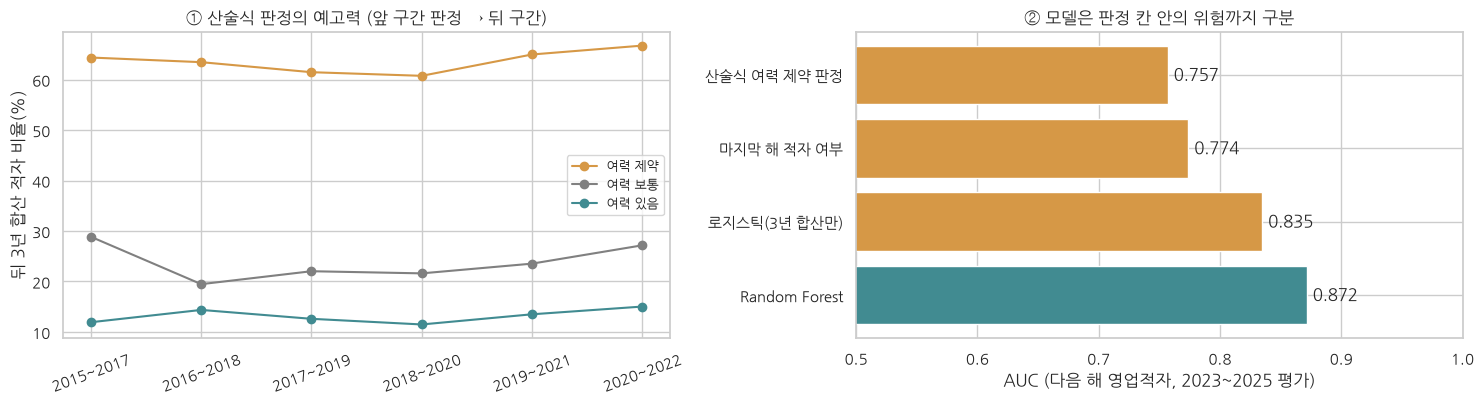

In [84]:
# [6-7] 산술식 판정 예고력(6개 구간) + 다음 해 적자 AUC 비교
display(formula_pred[['"여력 제약" → 이후 합산 적자(%)', '"여력 보통" → 이후 합산 적자(%)', '"여력 있음" → 이후 합산 적자(%)']].round(0))
cmp = risk_test.set_index('방법').loc[['산술식 여력 제약 판정', '마지막 해 적자 여부', '로지스틱(3년 합산만)', R_CHOSEN], ['AUC', 'Brier']]
cmp = cmp[~cmp.index.duplicated()]
display(cmp.round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
fp = formula_pred[['"여력 제약" → 이후 합산 적자(%)', '"여력 보통" → 이후 합산 적자(%)', '"여력 있음" → 이후 합산 적자(%)']]
for col, color in zip(fp.columns, [SUB_COLOR, 'grey', MAIN_COLOR]):
    axes[0].plot(range(len(fp)), fp[col], marker='o', color=color, label=col.split('"')[1])
axes[0].set(xticks=range(len(fp)), xticklabels=[x.split(' → ')[0] for x in fp.index], ylabel='뒤 3년 합산 적자 비율(%)',
            title='① 산술식 판정의 예고력 (앞 구간 판정 → 뒤 구간)')
axes[0].legend(fontsize=9); axes[0].tick_params(axis='x', rotation=20)
axes[1].barh(cmp.index[::-1], cmp['AUC'][::-1], color=[MAIN_COLOR if i == R_CHOSEN else SUB_COLOR for i in cmp.index[::-1]])
for k, v in enumerate(cmp['AUC'][::-1]): axes[1].text(v + .005, k, f'{v:.3f}', va='center')
axes[1].set(xlim=(.5, 1), xlabel='AUC (다음 해 영업적자, 2023~2025 평가)', title='② 모델은 판정 칸 안의 위험까지 구분')
plt.tight_layout(); save_figure(fig, '6_7_산술식_vs_모델'); plt.show()

**결과**: 산술식 판정만으로도 "여력 제약"과 "여력 있음"의 이후 적자 비율이 6개 구간 내내 약 4.5-5.5배 차이 납니다(①). 모델은 같은 정보에 최근 흐름을 더해 다음 해 적자를 AUC 0.872로 구분하고, 산술식 판정(0.757)보다 위험을 세밀하게 줄 세웁니다(②). **산술식은 진단, 모델은 미래 위험 경고**로 역할을 나눕니다.

(산술식 결과는 **모델 입력이 아니라 화면의 진단 정보**로 나란히 둡니다. 모델 B는 이미 산술식 여력 제약 판정(`constraint3`)을 입력으로 쓰고 있습니다.)

### 6-8. 회사별 통합 결과표 (2025년 기준)

In [85]:
# [6-8] 상식 점검 기업 통합 결과
CHECK = ['SK하이닉스', '삼성전자', 'LG전자', '현대모비스', '기아', 'NAVER', '현대자동차', '삼성SDI', '포스코퓨처엠',
         '카카오', 'LG유플러스', '한미반도체', '셀트리온', 'HD현대중공업', '에코프로비엠', '한화오션', '오뚜기']
board = cur_risk[['name', 'grp', 'constraint3', '다음해_적자확률']].rename(columns={'name': '기업명', 'grp': '업종그룹(모델)', 'constraint3': '여력제약'})
board = board.join(wq[['급여기준_참고', '급여기준_차이(%)']]).join(cur_state[['5%지급후_적자확률', '5%지급_새적자확률', '적용범위_주의']])
board = board.join(cur_q[['영업이익률_P10', '영업이익률_P50', '영업이익률_P90']])
s3 = scen[scen['규칙'].eq('영업이익 10%')].set_index('id')[['지급 후 적자 해 생김', '0원인 해 생김', '1인당 수령 변동계수']]
board = board.join(s3.add_prefix('3년·영업이익10%_'))
board['급여기준_참고'] = board['급여기준_참고'] / 1e4
# 5장 산술식 결과(같은 2,205곳) 붙이기
fw5 = fw.copy(); fw5.index = fw5.index.astype(str)
board = board.join(fw5[['업종_중분류', '비교군구성', '임금위치', '지급여력', '이익률하락_pp', 'g*', '진단문장']], how='left')
# (선택) 산술식 결과 파일 f6: 현금흐름 표시·급여 확인·WPS 맥락 — 드라이브 'V4 찐찐찐 최종본/3_최종계산_결과'
F6_PATH = None   # 예: '/content/drive/MyDrive/.../f6_최종계산_2023_2025.csv'
if F6_PATH and Path(F6_PATH).exists():
    f6 = pd.read_csv(F6_PATH, encoding='utf-8-sig', dtype={'기업고유코드': str})
    f6['id'] = f6['기업고유코드'].str.lstrip('0')
    board = board.join(f6.set_index('id')[['현금흐름 표시', '급여 확인', 'WPS_자발적 이직률 중앙(%)', 'WPS_성과배분제 운영률(%)']], how='left')
view = board[board['기업명'].isin(CHECK)].set_index('기업명').reindex([c for c in CHECK if c in set(board['기업명'])])
display(view.drop(columns=['진단문장']).round(3))
for firm in ['SK하이닉스', '현대자동차', '오뚜기']:
    if firm in view.index and pd.notna(view.loc[firm, '진단문장']):
        print('·', view.loc[firm, '진단문장'])
save_table(board.reset_index(), '6_8_통합결과_2025', index=False)
print('급여기준_참고 단위: 만 원 / 3년 시나리오는 여력 제약 기업에는 계산하지 않음')

,업종그룹(모델),여력제약,다음해_적자확률,급여기준_참고,급여기준_차이(%),5%지급후_적자확률,5%지급_새적자확률,적용범위_주의,영업이익률_P10,영업이익률_P50,영업이익률_P90,3년·영업이익10%_지급 후 적자 해 생김,3년·영업이익10%_0원인 해 생김,3년·영업이익10%_1인당 수령 변동계수,업종_중분류,비교군구성,임금위치,지급여력,이익률하락_pp,g*
기업명,,,,,,,,,,,,,,,,,,,,
SK하이닉스,C26,0,0.158,"11,689.820",17.941,0.180,0.011,False,0.003,0.391,0.606,0.106,0.106,0.254,26,같은 중분류 20곳 + 같은 대분류 0곳,임금 높음,여력 있음,0.389,0.006
삼성전자,C26,0,0.118,"11,189.229",17.904,0.121,0.013,False,-0.006,0.076,0.133,0.453,0.453,0.710,26,같은 중분류 20곳 + 같은 대분류 0곳,임금 높음,여력 있음,0.457,0.013
LG전자,C26,0,0.451,"8,692.604",31.909,0.535,0.077,False,-0.082,-0.005,0.035,0.541,0.541,0.745,26,같은 중분류 20곳 + 같은 대분류 0곳,임금 높음,여력 보통,0.770,0.068
현대모비스,C30,0,0.065,"11,640.525",10.507,0.085,0.014,False,0.039,0.045,0.061,0.087,0.087,0.229,30,같은 중분류 20곳 + 같은 대분류 0곳,임금 높음,여력 있음,0.253,0.027
기아,C30,0,0.081,"10,200.896",29.656,0.073,0.007,False,0.059,0.089,0.115,0.060,0.060,0.139,30,같은 중분류 20곳 + 같은 대분류 0곳,임금 높음,여력 있음,0.413,0.021
NAVER,J63,0,0.040,"11,433.668",13.246,0.040,0.006,False,0.198,0.263,0.316,0.064,0.064,0.118,63,같은 중분류 20곳 + 같은 대분류 0곳,임금 높음,여력 있음,0.557,0.014
현대자동차,C30,0,0.083,"10,526.354",17.893,0.103,0.018,False,0.017,0.049,0.077,0.097,0.097,0.193,30,같은 중분류 20곳 + 같은 대분류 0곳,임금 높음,여력 있음,0.665,0.033
삼성SDI,C28,1,0.675,"10,327.664",-5.738,0.701,0.025,False,NaN,NaN,NaN,NaN,NaN,NaN,28,같은 중분류 20곳 + 같은 대분류 0곳,임금 높음,여력 제약,0.580,NaN
포스코퓨처엠,C28,1,0.235,"9,661.413",-12.092,0.290,0.048,False,NaN,NaN,NaN,NaN,NaN,NaN,28,같은 중분류 20곳 + 같은 대분류 0곳,임금 보통,여력 제약,0.537,0.032


· SK하이닉스의 1인당 급여는 13,787만 원으로, 같은 업종(전자부품·컴퓨터·통신장비(반도체 등)) 중심으로 매출·자산이 비슷한 20곳(같은 중분류 20곳 + 같은 대분류 0곳)의 중앙값보다 +75.3%입니다(순위 100%, 비교 20곳의 가운데 절반은 6,328~9,831만 원) → 임금 높음. 주의: 비교 기업의 매출 규모가 크게 다름. 지급 여력은 '여력 있음'입니다(3년 영업이익률 35.6%, 같은 업종 중앙값 0.9%). 급여를 5% 올리면 회사 부담이 연 3,381억 원 늘어 영업이익률이 0.39%p 낮아집니다(마지막 해 영업이익의 1%). 본전을 찾으려면 급여+영업이익+감가상각비 등이 0.6% 늘어야 합니다.
· 현대자동차의 1인당 급여는 12,410만 원으로, 같은 업종(자동차·트레일러) 중심으로 매출·자산이 비슷한 20곳(같은 중분류 20곳 + 같은 대분류 0곳)의 중앙값보다 +34.3%입니다(순위 85%, 비교 20곳의 가운데 절반은 8,370~10,521만 원) → 임금 높음. 주의: 비교 기업의 매출 규모가 크게 다름. 지급 여력은 '여력 있음'입니다(3년 영업이익률 7.1%, 같은 업종 중앙값 3.5%). 급여를 5% 올리면 회사 부담이 연 5,236억 원 늘어 영업이익률이 0.66%p 낮아집니다(마지막 해 영업이익의 15%). 본전을 찾으려면 급여+영업이익+감가상각비 등이 3.3% 늘어야 합니다.
· 오뚜기의 1인당 급여는 4,921만 원으로, 같은 업종(식료품) 중심으로 매출·자산이 비슷한 20곳(같은 중분류 20곳 + 같은 대분류 0곳)의 중앙값보다 -19.0%입니다(순위 10%, 비교 20곳의 가운데 절반은 5,330~6,625만 원) → 임금 낮음. 지급 여력은 '여력 있음'입니다(3년 영업이익률 4.2%, 같은 업종 중앙값 3.3%). 급여를 5% 올리면 회사 부담이 연 96억 원 늘어 영업이익률이 0.32%p 낮아집니다(마지막 해 영업이익의 11%). 본전을 찾으려면 급여+영업이익+감가상각비 등이 2.8% 늘어야 합니다

**읽는 법**: 예를 들어 SK하이닉스는 1인당 급여가 HGB 참고값보다 18% 높고, 다음 해 적자 확률은 16%입니다. 급여총액 5%를 더 주면 지급 후 적자 확률은 18%입니다. 영업이익 10% 성과급이면 3년 중 0원인 해가 생기는 시나리오가 11%입니다.

같은 SK하이닉스가 5장 비교군 20곳 기준으로는 +75%인데 HGB 참고값 기준으로는 +18%입니다. 5장 비교군에서는 같은 중분류 안의 훨씬 작은 회사들과 비교되기 때문이고("비교 기업의 매출 규모가 크게 다름" 표시), HGB는 매출 규모를 입력으로 함께 씁니다.

삼성SDI·포스코퓨처엠처럼 **여력 제약 기업은 범위·3년 시나리오를 계산하지 않고**(학습 대상 밖), 다음 해 적자 위험(삼성SDI 68%)으로 먼저 경고합니다.

`업종그룹(모델)`은 6장 모델의 그룹입니다(예: `C26`. 통신처럼 작은 중분류는 대분류 `J`). `업종_중분류`·`비교군구성`은 5장 산술식 기준입니다. 모든 값은 별도 재무제표 기준입니다. 결과표에는 5장 산술식의 임금 위치·지급 여력·진단문장을 함께 붙였고, 산술식 결과 파일(f6)의 경로를 `F6_PATH`에 넣으면 현금흐름 표시·급여 확인·WPS 맥락도 붙습니다.

### 6-9. 예측 결과 내보내기 (MVP 기능 4: 미래 위험)
다음 해 적자 확률(모델 B), 5% 추가 지급 후 상태(모델 C), 다음 해 영업이익률·매출·급여총액·직원수 성장의 P10·P50·P90(모델 D), 3년 스트레스 시나리오(모델 E)를 기업별로 한 파일에 모읍니다. MVP는 이 파일만 읽고, 인상안과의 결합 계산은 `formula.pay_plan_forecast`가, 업황 충격·모델 P10을 한 표로 비교하는 업계 불황 대비 점검는 `formula.stress_test`가 합니다.

In [86]:
# [6-9] 예측 결과 내보내기 — MVP 기능 4(미래 위험)의 재료. 2025년 기준 → 2026년 예측, 기업 한 줄씩
pred = cur_risk[['name', '다음해_적자확률']].rename(columns={'name': '기업명'})
pred = pred.join(cur_state[['원래_적자확률', '5%지급_새적자확률', '5%지급후_적자확률', '적용범위_주의']])
qcols = [c for c in cur_q.columns if c.endswith(('_P10', '_P50', '_P90'))]
pred = pred.join(cur_q[qcols])     # 영업이익률은 비율, 매출·급여총액·직원수 성장은 로그 변화(ln 다음 해 ÷ 올해)
wide = scen.pivot_table(index='id', columns='규칙', aggfunc='first',
                        values=['3년 비용 P50(억)', '3년 비용 P90(억)', '지급 후 적자 해 생김', '지급 때문에 새 적자',
                                '0원인 해 생김', '1인당 수령 변동계수'])
wide.columns = [f'3년·{rule}_{val}' for val, rule in wide.columns]
pred = pred.join(wide)
pred.index = pred.index.astype(str)
pred.insert(0, '기업고유코드', pred.index.str.zfill(8))   # formula.py 결과와 같은 8자리 코드
pred['범위예측_대상'] = pred[qcols].notna().any(axis=1)    # 범위·3년 시나리오는 여력 제약이 아니고 마지막 해 매출 > 0인 기업만
print(f'{len(pred):,}곳 · 범위 예측 대상 {int(pred["범위예측_대상"].sum()):,}곳 · 열 {pred.shape[1]}개')
display(pred[['다음해_적자확률', '5%지급후_적자확률'] + qcols].describe().T.round(3))
save_table(pred.reset_index(drop=True), '6_9_예측결과_2025', index=False)


2,205곳 · 범위 예측 대상 1,365곳 · 열 44개


,count,mean,std,min,25%,50%,75%,max
다음해_적자확률,"2,205.000",0.336,0.293,0.008,0.072,0.226,0.579,0.972
5%지급후_적자확률,"2,205.000",0.359,0.287,0.011,0.092,0.274,0.600,0.971
영업이익률_P10,"1,365.000",-0.010,0.158,-2.984,-0.042,0.001,0.040,0.542
영업이익률_P50,"1,365.000",0.079,0.098,-0.929,0.024,0.056,0.110,0.807
영업이익률_P90,"1,365.000",0.136,0.118,-0.154,0.064,0.104,0.170,1.738
매출 성장_P10,"1,365.000",-0.202,0.129,-1.078,-0.247,-0.169,-0.122,-0.008
매출 성장_P50,"1,365.000",0.025,0.035,-0.088,0.004,0.025,0.046,0.178
매출 성장_P90,"1,365.000",0.232,0.089,0.074,0.181,0.210,0.254,0.868
급여총액 성장_P10,"1,365.000",-0.148,0.097,-0.754,-0.189,-0.127,-0.081,0.009
급여총액 성장_P50,"1,365.000",0.056,0.067,-0.138,0.014,0.051,0.088,0.416
